WESAD data loader: raw synchronized .pkl files -> per-subject baseline-normalized,
windowed, per-modality signal tensors ready for encoder input.

Reference (from the dataset README):
- Each SX.pkl is a dict: {'subject': 'SX', 'signal': {'chest': {...}, 'wrist': {...}}, 'label': array}
- 'label' is sampled at 700 Hz (chest rate). IDs: 0=transient, 1=baseline, 2=stress,
  3=amusement, 4=meditation, 5/6/7=ignore.
- Chest (RespiBAN): ACC(3ch), ECG, EDA, EMG, Resp, Temp -- all at 700 Hz, already
  time-aligned with the label array (same index -> same instant).
- Wrist (Empatica E4): ACC(3ch)@32Hz, BVP@64Hz, EDA@4Hz, TEMP@4Hz -- lower rates,
  synchronized in the .pkl to the same start time as chest/label, but sample index
  does NOT line up 1:1 with chest index -- must convert via elapsed seconds.
- S1 and S12 are missing (discarded for sensor malfunction).

#**Unzipping the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip -q "/content/drive/MyDrive/licenta/WESAD/WESAD.zip" -d /content/wesad_data

#**Loading the dataset**

In [ ]:
import pickle
from pathlib import Path

import numpy as np

CHEST_FS = 700
WRIST_FS = {"ACC": 32, "BVP": 64, "EDA": 4, "TEMP": 4}

CHEST_CHANNELS = ["ACC", "ECG", "EDA", "EMG", "Resp", "Temp"]
WRIST_CHANNELS = ["ACC", "BVP", "EDA", "TEMP"]

# Which protocol-condition labels we keep, and how they map to model class indices.
LABEL_MAP = {1: 0, 2: 1, 3: 2, 4: 3}  # baseline -> 0, stress -> 1, amusement -> 2, meditation -> 3
BASELINE_LABEL_RAW = 1

ALL_SUBJECTS = [f"S{i}" for i in list(range(2, 12)) + list(range(13, 18))]  # S1, S12 excluded as per dataset documentation

In [ ]:
def load_subject_pkl(pkl_path):
    """Load one SX.pkl and return the raw chest/wrist signal dicts + label array."""
    with open(pkl_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    chest = {ch: np.asarray(data["signal"]["chest"][ch], dtype=np.float64) for ch in CHEST_CHANNELS}
    wrist = {ch: np.asarray(data["signal"]["wrist"][ch], dtype=np.float64) for ch in WRIST_CHANNELS}
    label = np.asarray(data["label"]).reshape(-1)
    # Every chest channel must be 700Hz-aligned with label, 1:1 by index.
    for ch, arr in chest.items():
        assert arr.shape[0] == label.shape[0], (
            f"{data['subject']}: chest[{ch}] length {arr.shape[0]} != label length {label.shape[0]}"
        )
    return {"subject": data["subject"], "chest": chest, "wrist": wrist, "label": label}

In [ ]:
def find_label_runs(label, keep_labels=None):
    """Return contiguous (start, end, label) index runs (chest/label index space,
    end exclusive) where label stays constant. keep_labels=None keeps every run
    regardless of label; pass a set/tuple to restrict to specific label values."""
    runs = []
    n = len(label)
    i = 0
    while i < n:
        lab = label[i]
        j = i
        while j < n and label[j] == lab:
            j += 1
        if keep_labels is None or lab in keep_labels:
            runs.append((i, j, int(lab)))
        i = j
    return runs

In [ ]:
def compute_baseline_stats(subject_data, trim_start_sec=300):
    """Per-subject, per-channel mean/std computed over the baseline (label==1)
    segment, EXCLUDING the first trim_start_sec seconds. Default 300s (5 min):
    wrist EDA in particular shows a device-donning decay artifact early in the
    baseline segment for most (not all) subjects -- averaging over the whole
    segment pulls the mean up and inflates std from that transient rather than
    real resting variability. Trimming costs little even for subjects whose
    baseline was already stable, since the segment is generally longer.
    Returns {'chest': {ch: (mean, std)}, 'wrist': {ch: (mean, std)}}."""
    label = subject_data["label"]
    baseline_idx = np.where(label == BASELINE_LABEL_RAW)[0]
    if baseline_idx.size == 0:
        raise ValueError(f"{subject_data['subject']}: no baseline (label==1) segment found")
    b_start_full, b_end = baseline_idx[0], baseline_idx[-1] + 1
    b_start = b_start_full + int(trim_start_sec * CHEST_FS)
    if b_start >= b_end:
        raise ValueError(
            f"{subject_data['subject']}: trim_start_sec={trim_start_sec} leaves no baseline "
            f"(segment is only {(b_end - b_start_full) / CHEST_FS:.0f}s)"
        )

    stats = {"chest": {}, "wrist": {}}
    for ch in CHEST_CHANNELS:
        seg = subject_data["chest"][ch][b_start:b_end]
        stats["chest"][ch] = (seg.mean(axis=0), seg.std(axis=0) + 1e-8)

    b_start_sec = b_start / CHEST_FS
    b_end_sec = b_end / CHEST_FS
    for ch in WRIST_CHANNELS:
        fs = WRIST_FS[ch]
        w_start = int(round(b_start_sec * fs))
        w_end = int(round(b_end_sec * fs))
        seg = subject_data["wrist"][ch][w_start:w_end]
        stats["wrist"][ch] = (seg.mean(axis=0), seg.std(axis=0) + 1e-8)
    return stats

In [ ]:
def _slice_and_normalize(arr, start_idx, end_idx, mean, std):
    seg = arr[start_idx:end_idx]
    return (seg - mean) / std


def generate_windows_for_subject(subject_data, baseline_stats, window_sec=60, step_sec=15,
                                  keep_labels=None):
    """Slide a fixed window over each contiguous label run; one normalized multi-modal
    example per window. Windows never cross a label boundary. Stores t_start_sec so
    quality metrics can be computed from the raw signals afterwards."""
    window_len_chest = int(window_sec * CHEST_FS)
    step_len_chest = int(step_sec * CHEST_FS)

    runs = find_label_runs(subject_data["label"], keep_labels=keep_labels)
    windows = []
    for run_start, run_end, raw_label in runs:
        pos = run_start
        while pos + window_len_chest <= run_end:
            w_start_chest, w_end_chest = pos, pos + window_len_chest
            t_start_sec = w_start_chest / CHEST_FS

            example = {
                "subject": subject_data["subject"],
                "label": raw_label,
                "t_start_sec": t_start_sec,
                "chest": {},
                "wrist": {},
            }
            for ch in CHEST_CHANNELS:
                mean, std = baseline_stats["chest"][ch]
                example["chest"][ch] = _slice_and_normalize(
                    subject_data["chest"][ch], w_start_chest, w_end_chest, mean, std
                ).astype(np.float32)

            for ch in WRIST_CHANNELS:
                fs = WRIST_FS[ch]
                mean, std = baseline_stats["wrist"][ch]
                w_start_wrist = int(round(t_start_sec * fs))
                w_end_wrist = w_start_wrist + int(window_sec * fs)
                example["wrist"][ch] = _slice_and_normalize(
                    subject_data["wrist"][ch], w_start_wrist, w_end_wrist, mean, std
                ).astype(np.float32)

            windows.append(example)
            pos += step_len_chest
    return windows

#**Visualizing the dataset**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

LABEL_COLORS = {
    0: "#c7c7c7",  # transient/undefined
    1: "#4c72b0",  # baseline
    2: "#c44e52",  # stress
    3: "#55a868",  # amusement
    4: "#8172b2",  # meditation
    5: "#ccb974", 6: "#64b5cd", 7: "#dd8452",
}

LABEL_NAMES = {
    0: "Transient",
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation",
    5: "Ignore",
    6: "Ignore",
    7: "Ignore"
}

def plot_label_distribution_seconds(dist, save_path=None):
    """dist: output of summarize_label_distribution(), {subject: {label: seconds}}.
    Stacked bar per subject so you can see, per subject, how much of each label is
    actually present (e.g. whether label 0 is negligible or substantial)."""
    subjects = sorted(dist.keys(), key=lambda s: int(s[1:]))
    all_labels = sorted({lab for d in dist.values() for lab in d})

    fig, ax = plt.subplots(figsize=(max(8, len(subjects) * 0.6), 5))
    bottoms = np.zeros(len(subjects))
    for lab in all_labels:
        vals = np.array([dist[s].get(lab, 0.0) for s in subjects])
        ax.bar(subjects, vals, bottom=bottoms, color=LABEL_COLORS.get(lab, "#333333"),
               label=f"{lab}: {LABEL_NAMES.get(lab, '?')}")
        bottoms += vals

    ax.set_ylabel("seconds")
    ax.set_title("Label composition per subject (raw, unfiltered)")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
    plt.xticks(rotation=45)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    return fig


def plot_subject_label_timeline(subject_data, save_path=None):
    """Horizontal timeline of protocol conditions over one subject's session, so you
    can see the actual ordering/duration of segments (including where label 0 falls
    -- typically the gaps between defined conditions)."""
    label = subject_data["label"]
    n = len(label)
    runs = []
    i = 0
    while i < n:
        lab = label[i]
        j = i
        while j < n and label[j] == lab:
            j += 1
        runs.append((i / CHEST_FS, (j - i) / CHEST_FS, int(lab)))
        i = j

    fig, ax = plt.subplots(figsize=(12, 1.8))
    for start_sec, dur_sec, lab in runs:
        ax.broken_barh([(start_sec / 60, dur_sec / 60)], (0, 1),
                        facecolors=LABEL_COLORS.get(lab, "#333333"))
    ax.set_xlabel("time (minutes)")
    ax.set_yticks([])
    ax.set_title(f"{subject_data['subject']}: protocol timeline (raw labels)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS.get(l, "#333")) for l in sorted(set(r[2] for r in runs))]
    labels_present = sorted(set(r[2] for r in runs))
    ax.legend(handles, [f"{l}: {LABEL_NAMES.get(l, '?')}" for l in labels_present],
              bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    return fig


def plot_channel_with_label_shading(subject_data, device="wrist", channel="EDA", save_path=None):
    """Line plot of one raw channel across the full session, with background shading
    per label region -- lets you visually sanity-check whether the signal actually
    moves with the protocol before you commit to a label scheme."""
    label = subject_data["label"]
    n = len(label)
    fs = CHEST_FS if device == "chest" else WRIST_FS[channel]
    sig = subject_data[device][channel]
    sig_1d = sig[:, 0] if sig.ndim > 1 else sig
    t_sig = np.arange(len(sig_1d)) / fs

    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(t_sig / 60, sig_1d, color="black", linewidth=0.6)

    i = 0
    while i < n:
        lab = label[i]
        j = i
        while j < n and label[j] == lab:
            j += 1
        ax.axvspan(i / CHEST_FS / 60, j / CHEST_FS / 60, color=LABEL_COLORS.get(lab, "#333333"), alpha=0.25)
        i = j

    ax.set_xlabel("time (minutes)")
    ax.set_ylabel(f"{device}.{channel} (raw units)")
    ax.set_title(f"{subject_data['subject']}: {device}.{channel} with protocol shading")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=130)
    return fig

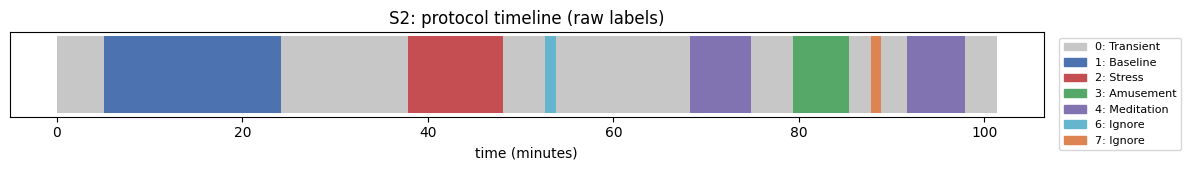

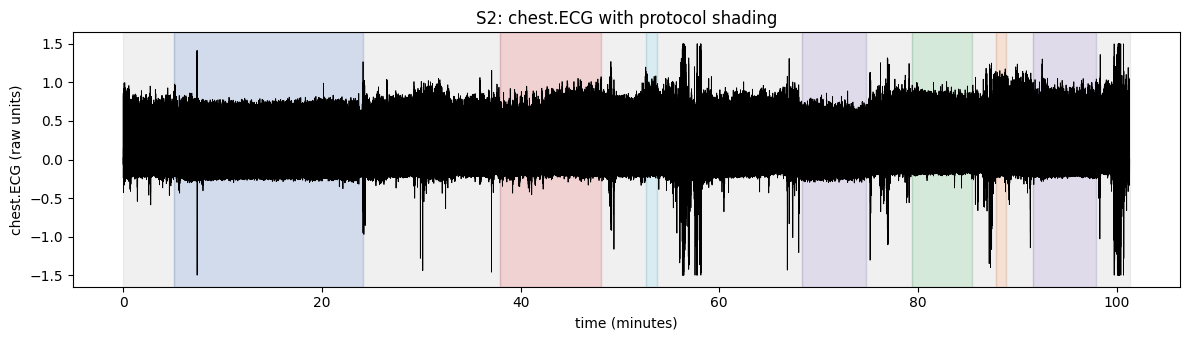

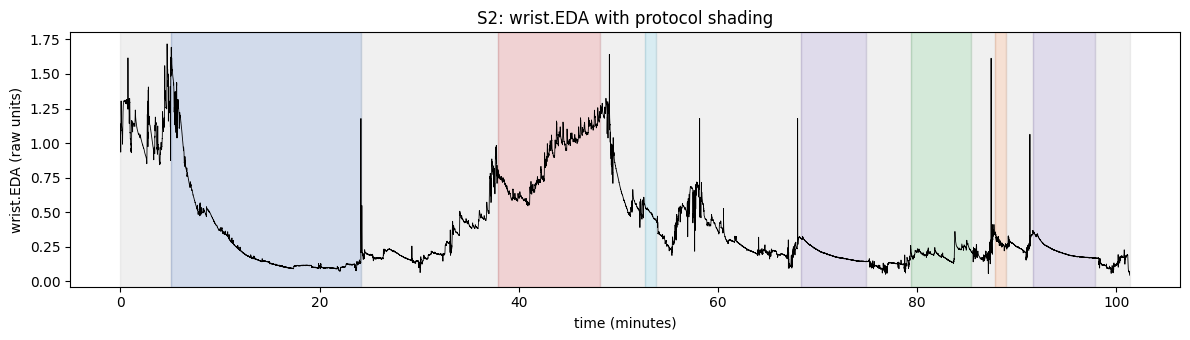

In [ ]:
# 1. Load a single subject's raw data
sample_subject = load_subject_pkl("/content/wesad_data/WESAD/S2/S2.pkl")

# 2. Plot the protocol timeline
fig1 = plot_subject_label_timeline(sample_subject)
plt.show()

# 3. Plot a raw chest signal (e.g., ECG) with the protocol shading
fig2 = plot_channel_with_label_shading(sample_subject, device="chest", channel="ECG")
plt.show()

# 4. Plot a raw wrist signal (e.g., EDA) to verify the dual-device alignment
fig3 = plot_channel_with_label_shading(sample_subject, device="wrist", channel="EDA")
plt.show()

In [ ]:
def load_entire_dataset(root_dir="/content/wesad_data/WESAD"):
    """
    Loads all valid subjects into a single dictionary.
    Format: dataset['S2']['chest']['ECG'], dataset['S2']['label'], etc.
    """
    full_dataset = {}

    # S1 and S12 are excluded as per the dataset documentation
    subject_ids = [f"S{i}" for i in list(range(2, 12)) + list(range(13, 18))]

    for sid in subject_ids:
        pkl_path = f"{root_dir}/{sid}/{sid}.pkl"
        try:
            print(f"Loading {sid}...")
            full_dataset[sid] = load_subject_pkl(pkl_path)
        except FileNotFoundError:
            print(f"  [Warning] {pkl_path} not found. Skipping.")

    print(f"Successfully loaded {len(full_dataset)} subjects into RAM.")
    return full_dataset

wesad_full = load_entire_dataset()

Loading S2...
Loading S3...
Loading S4...
Loading S5...
Loading S6...
Loading S7...
Loading S8...
Loading S9...
Loading S10...
Loading S11...
Loading S13...
Loading S14...
Loading S15...
Loading S16...
Loading S17...
Successfully loaded 15 subjects into RAM.


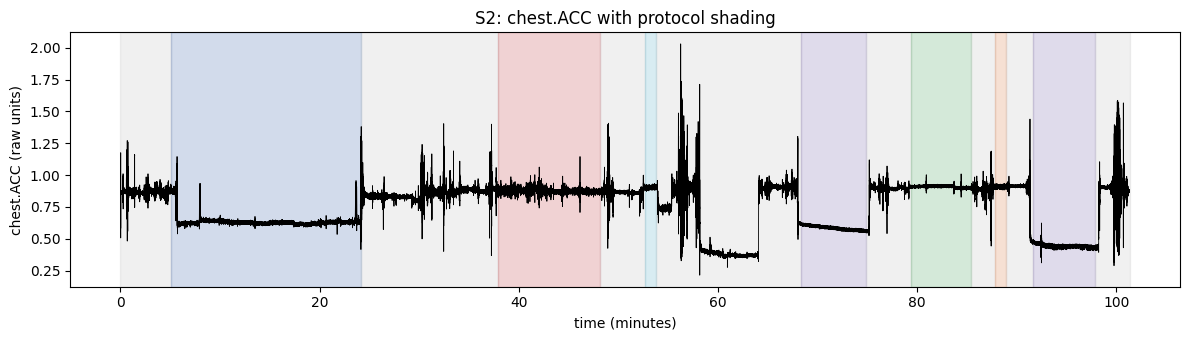

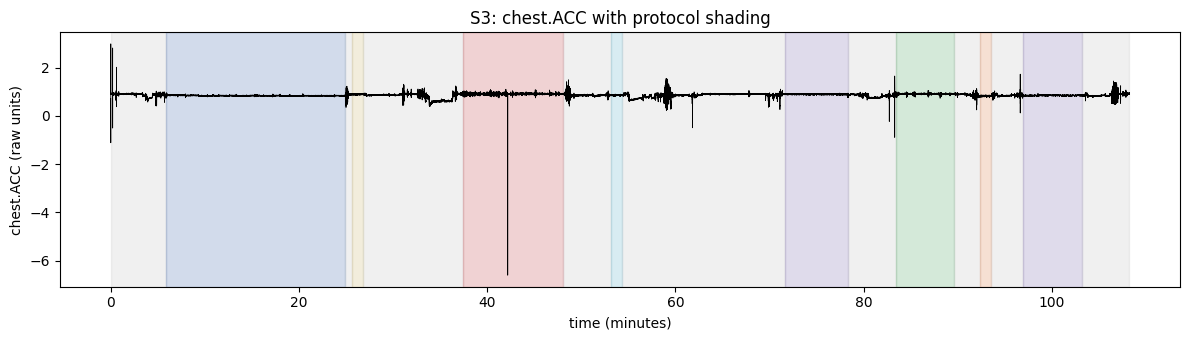

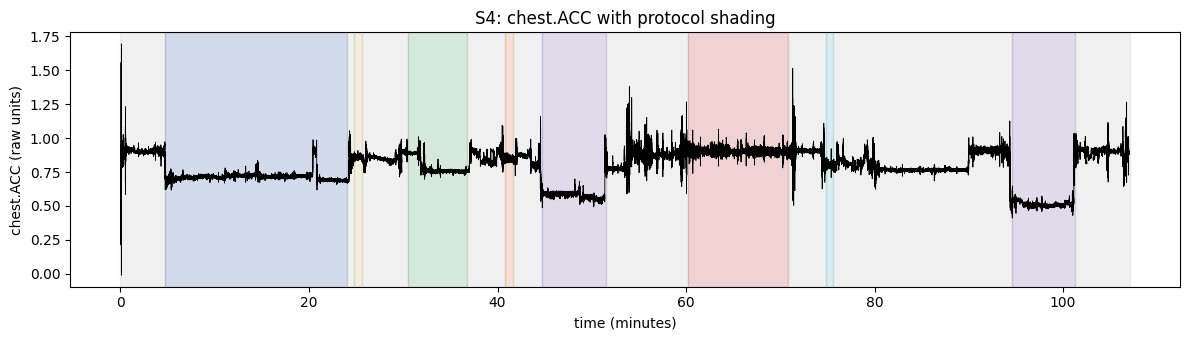

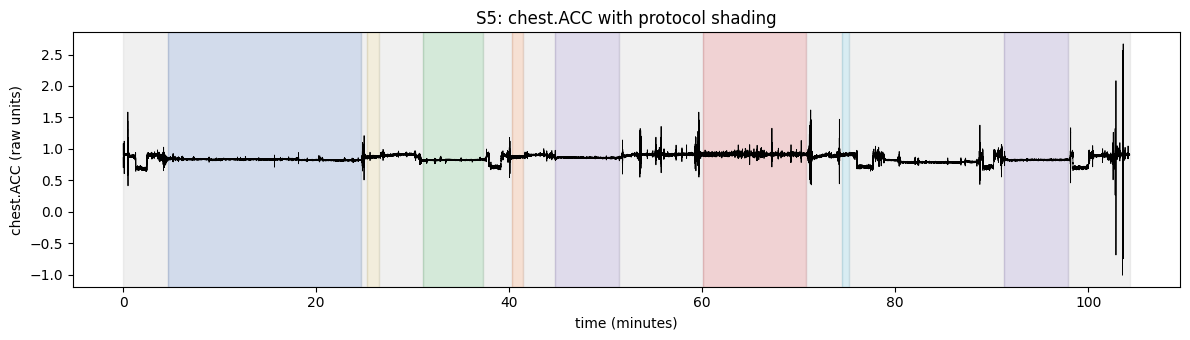

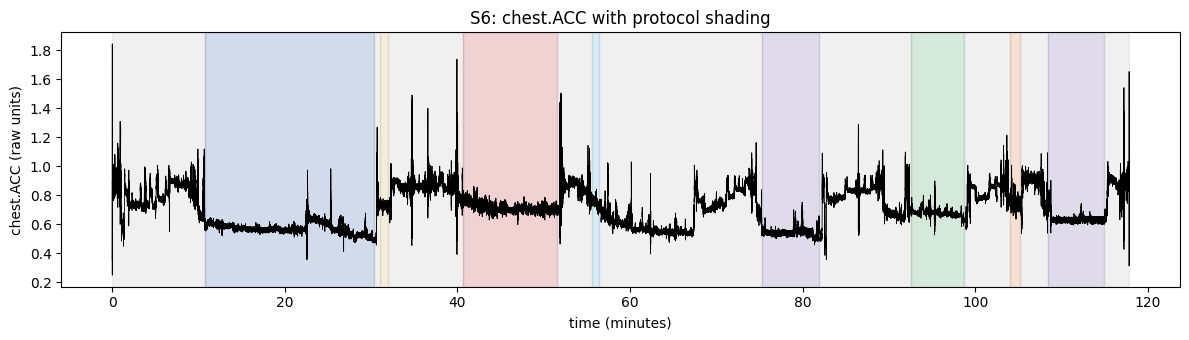

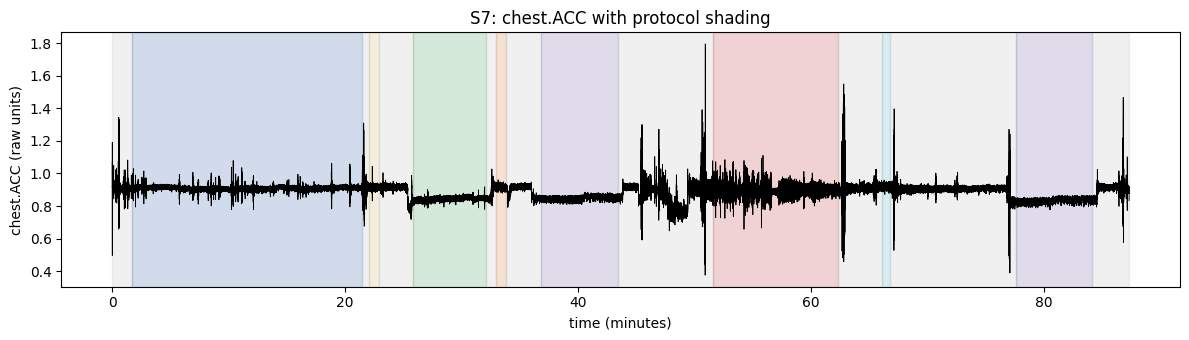

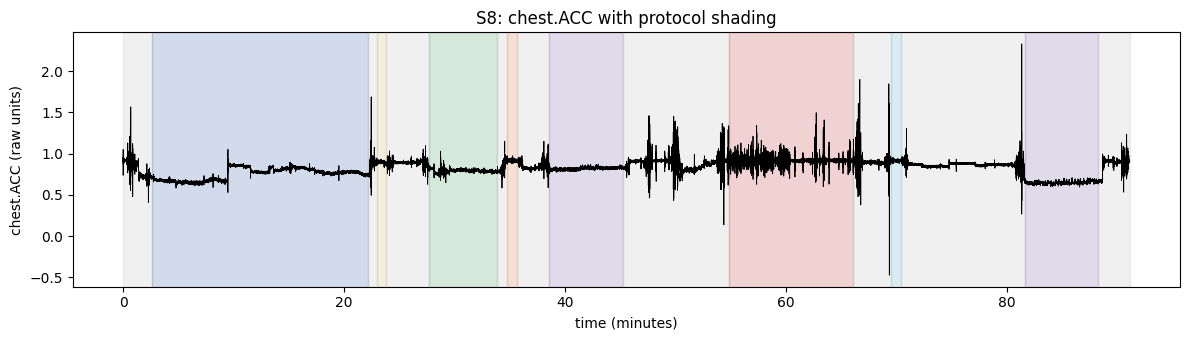

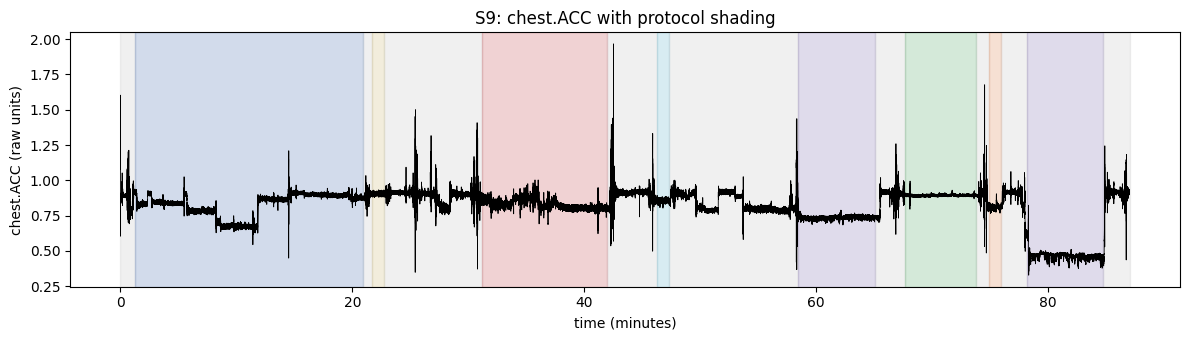

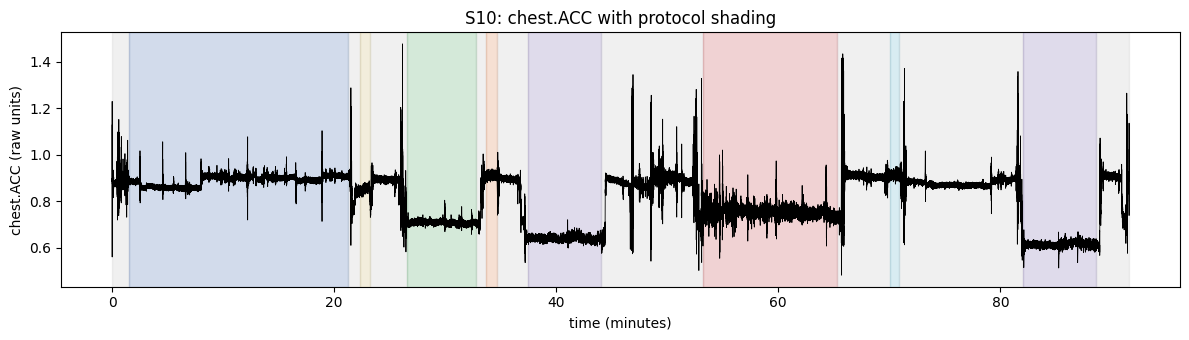

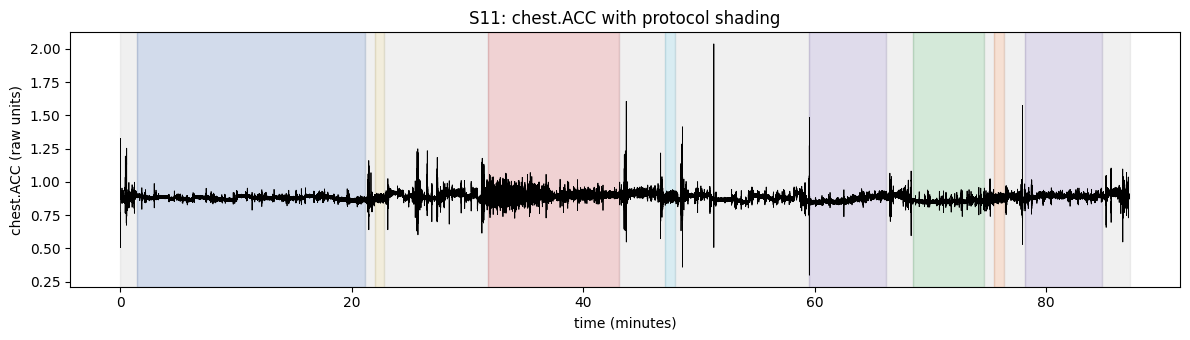

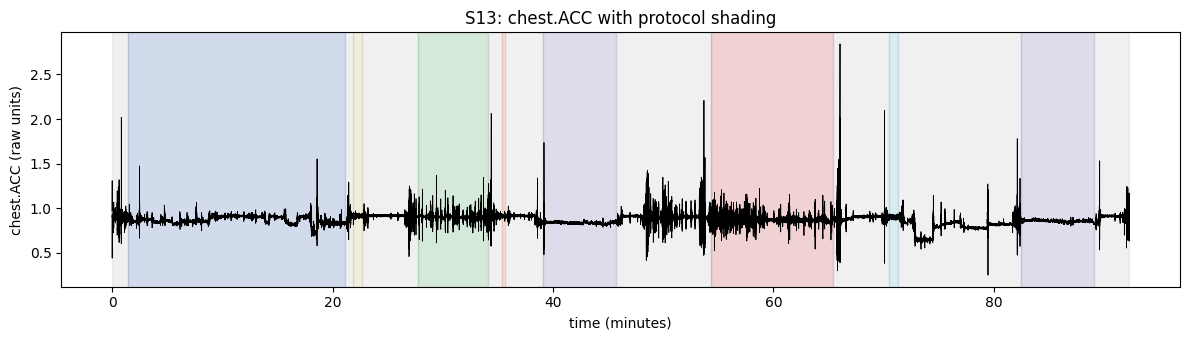

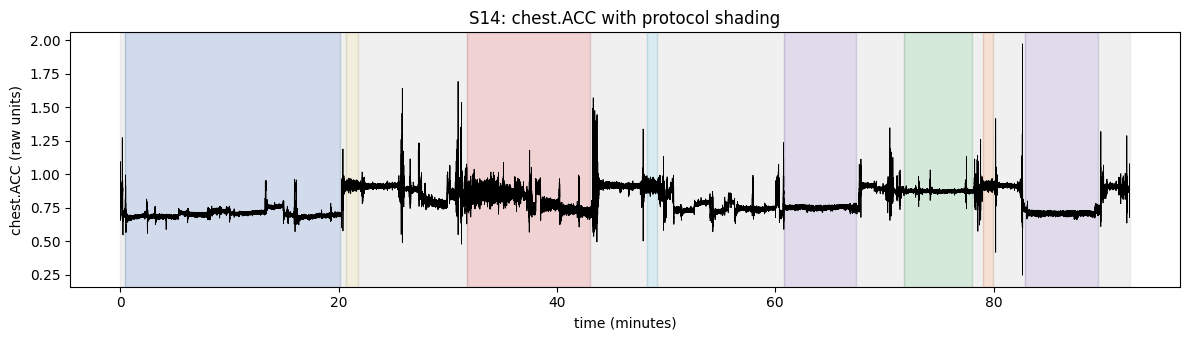

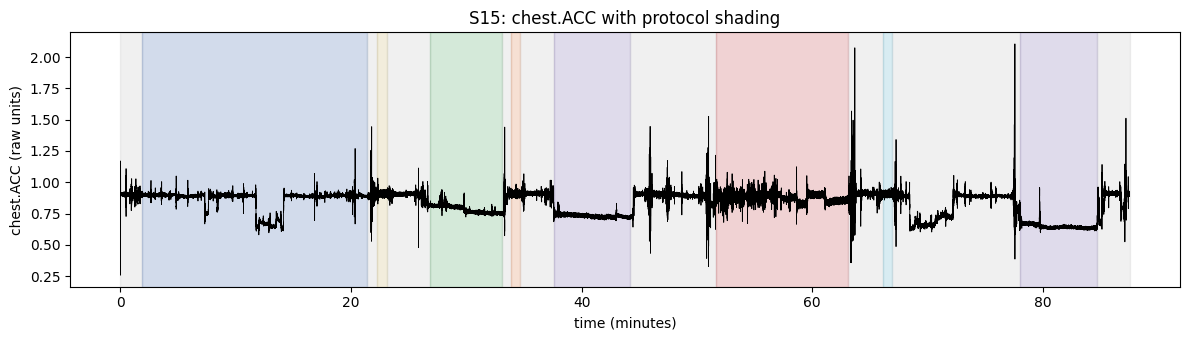

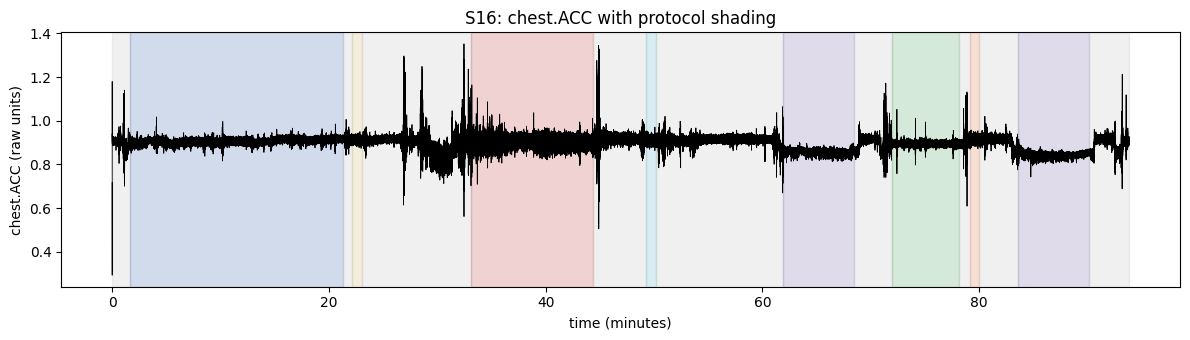

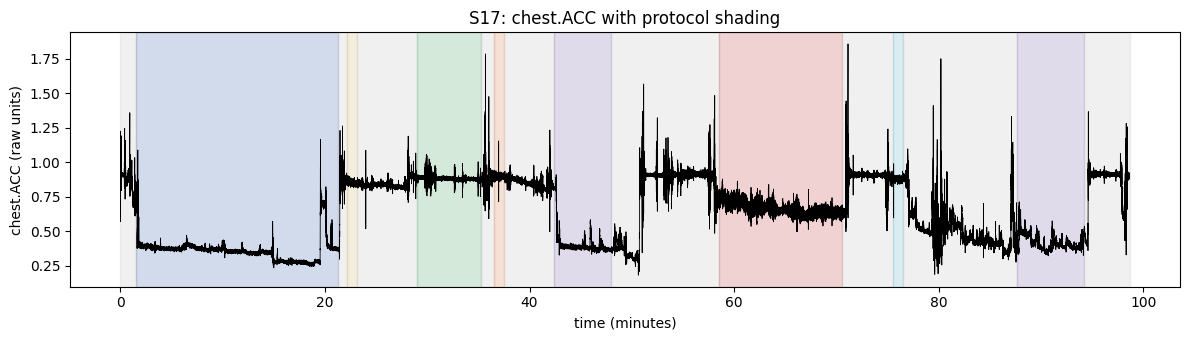

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="ACC")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

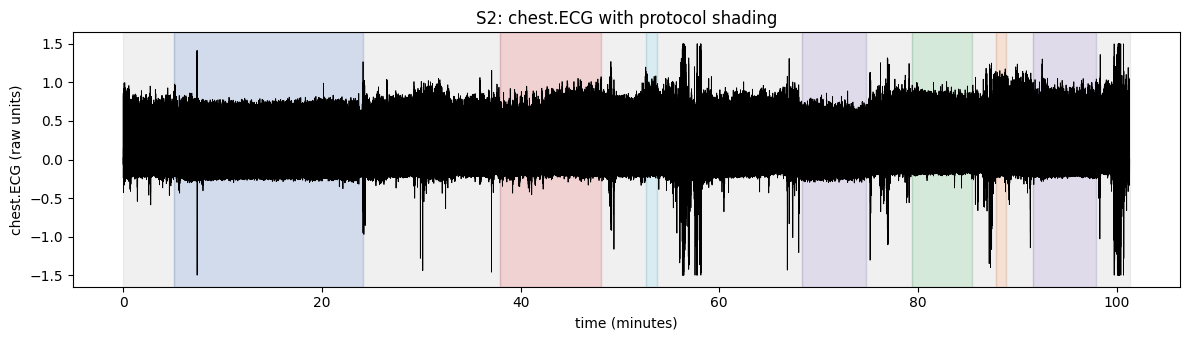

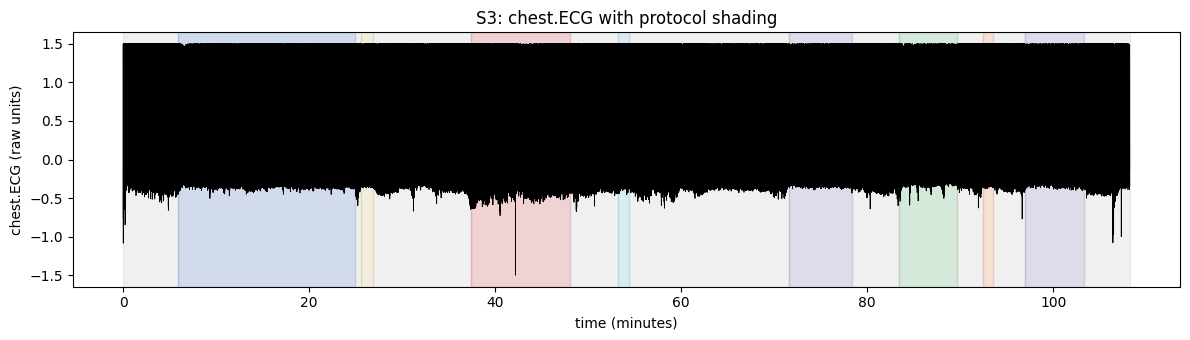

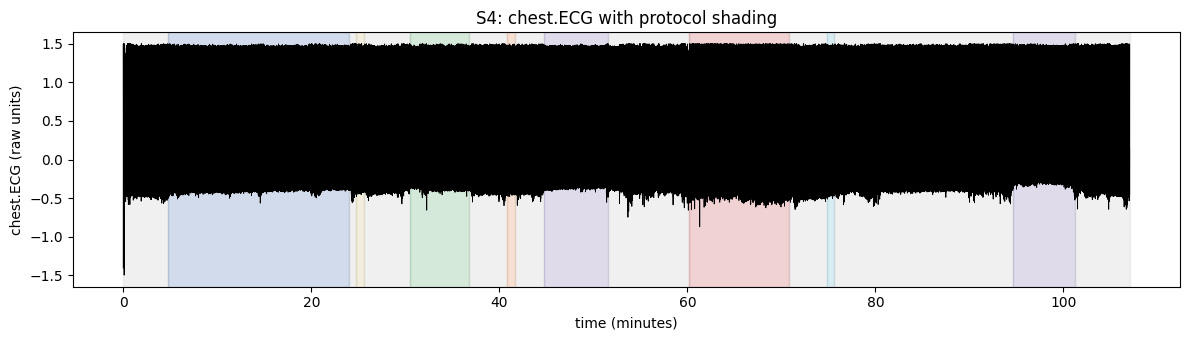

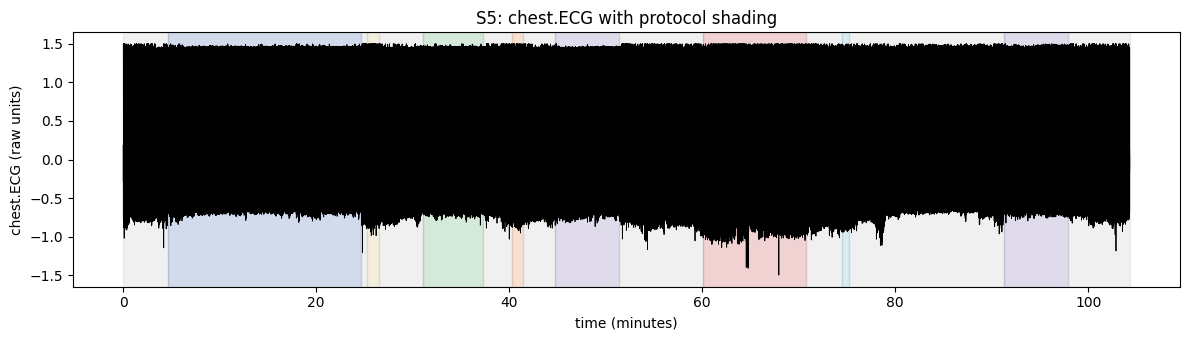

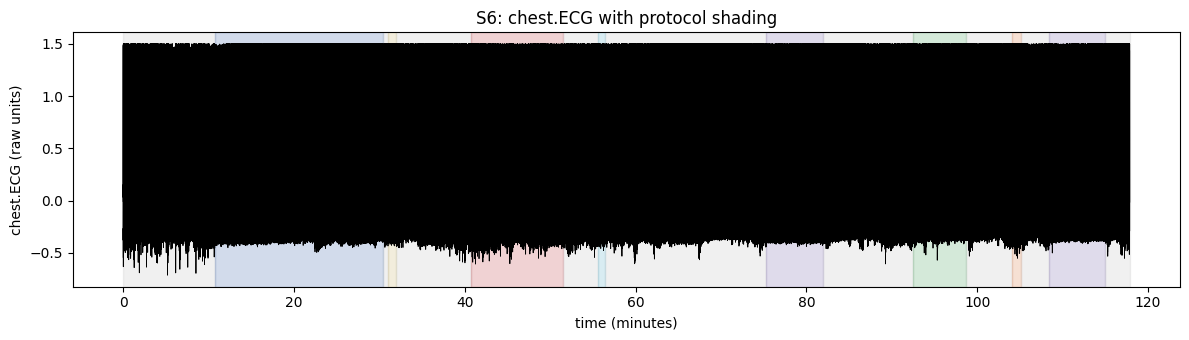

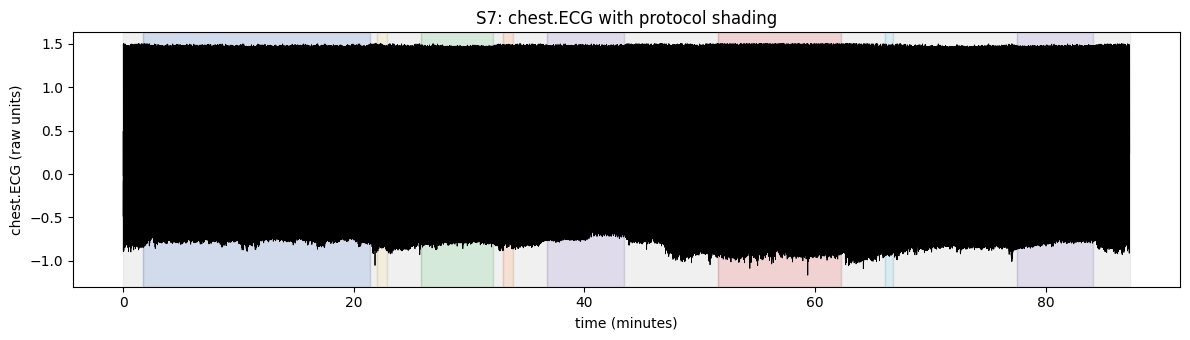

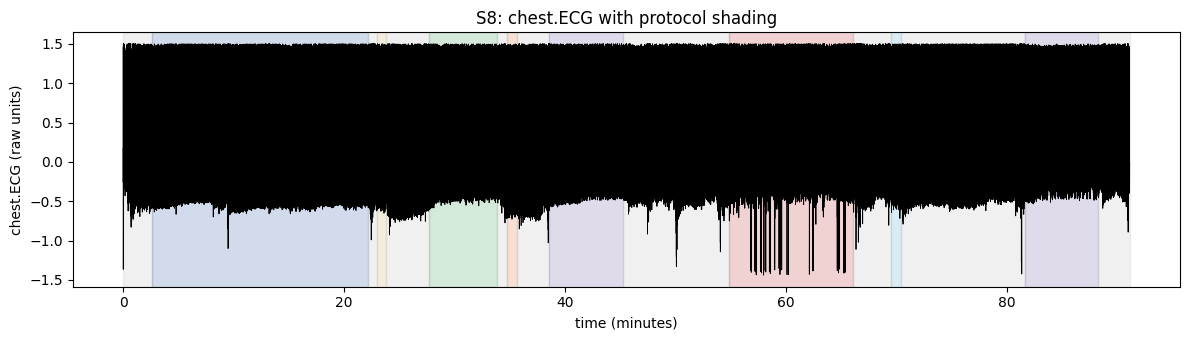

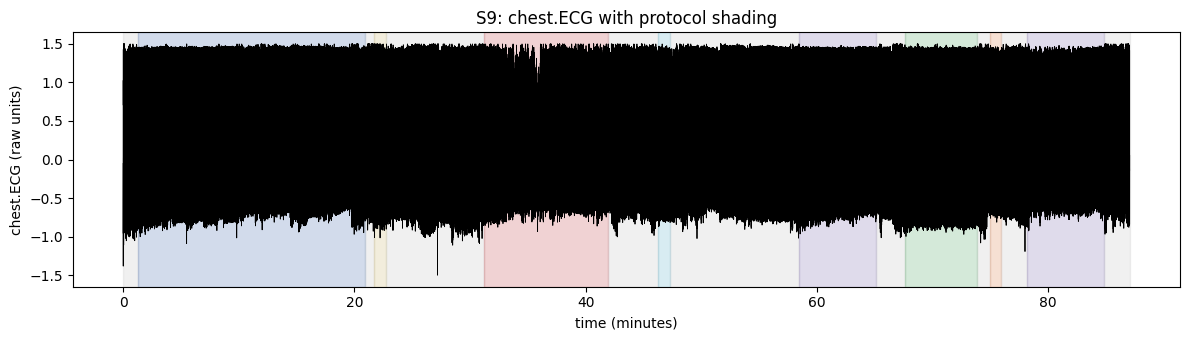

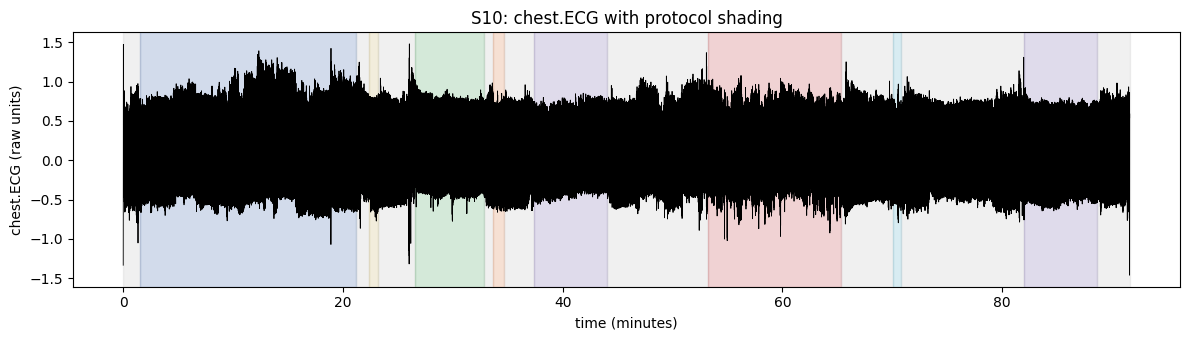

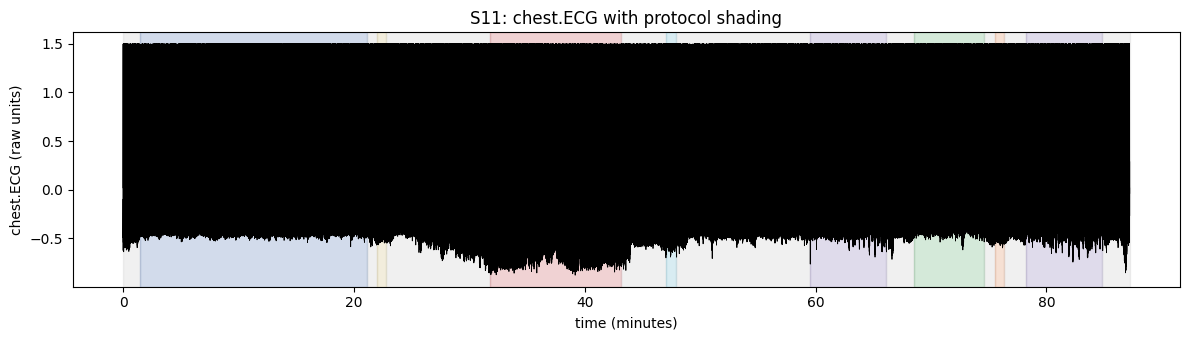

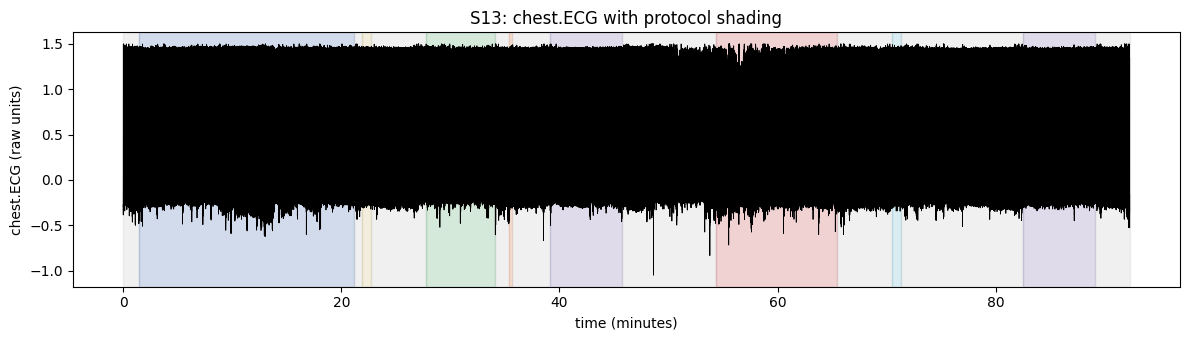

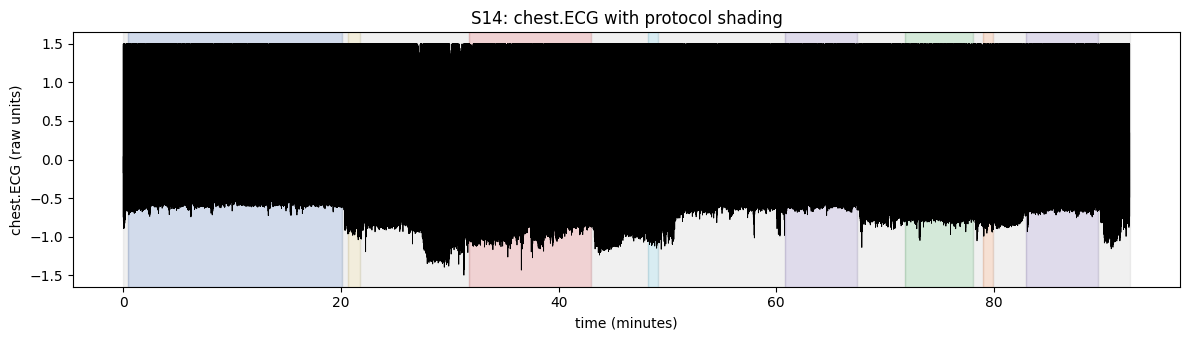

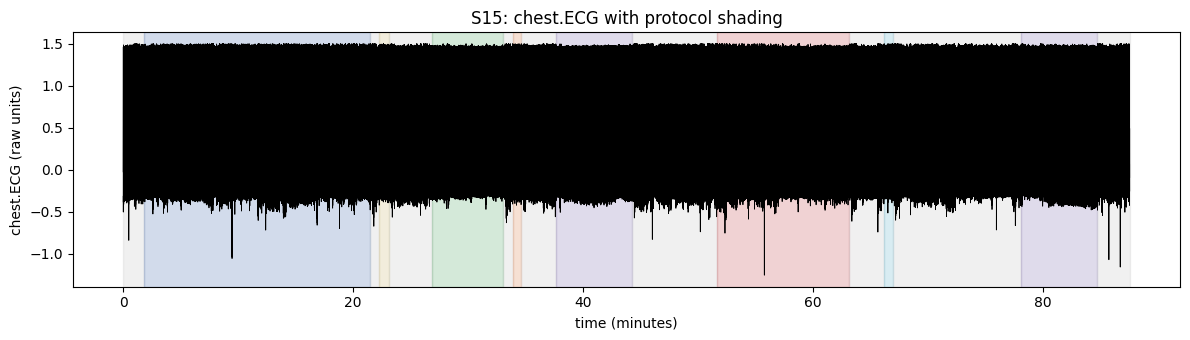

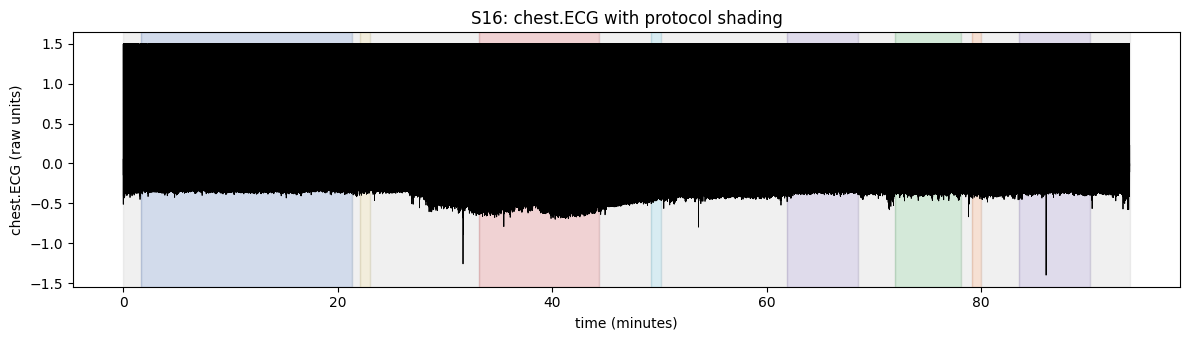

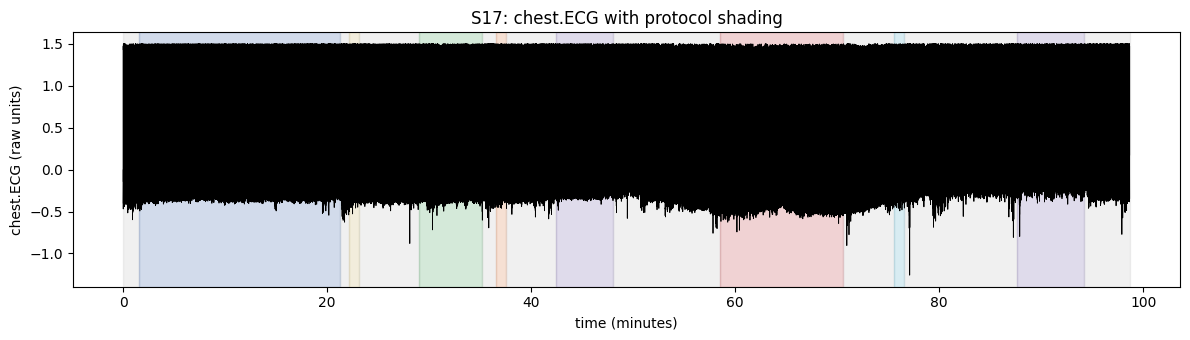

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="ECG")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

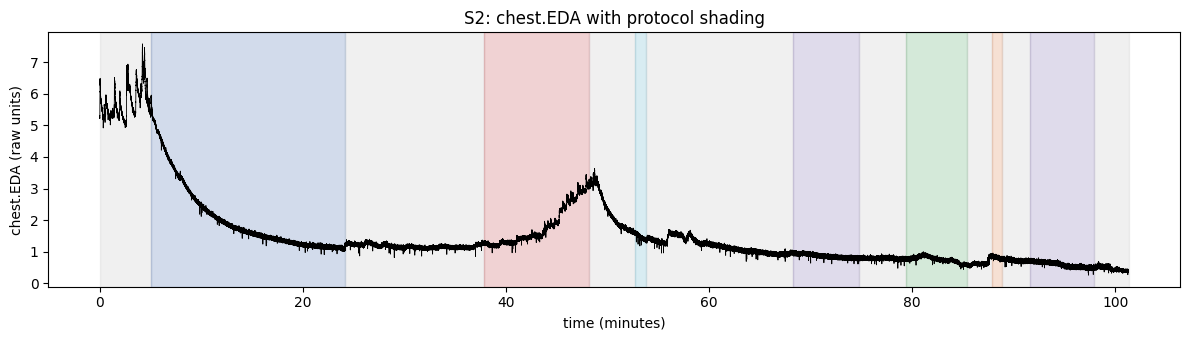

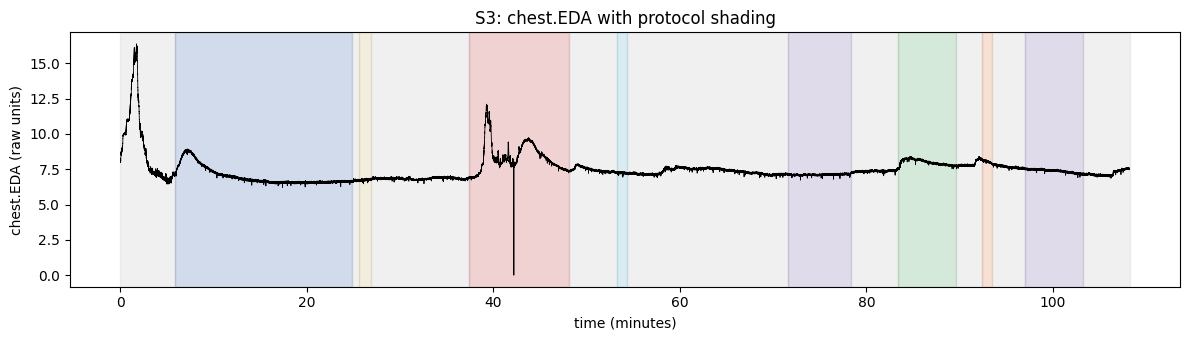

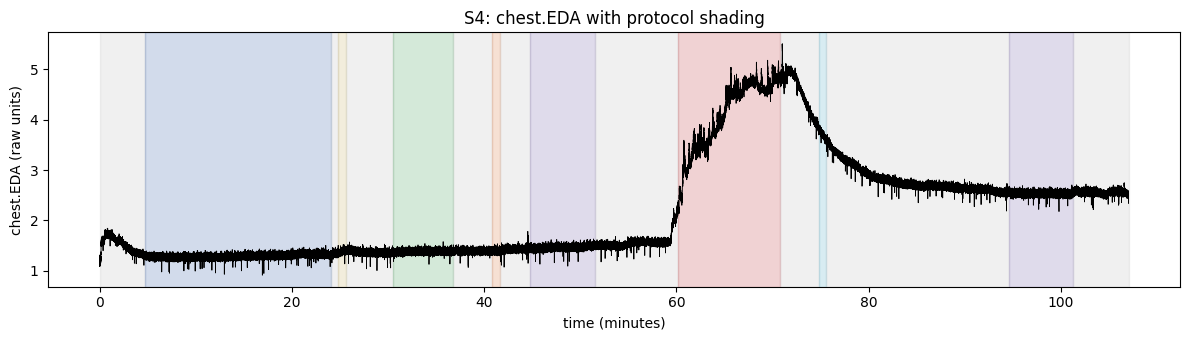

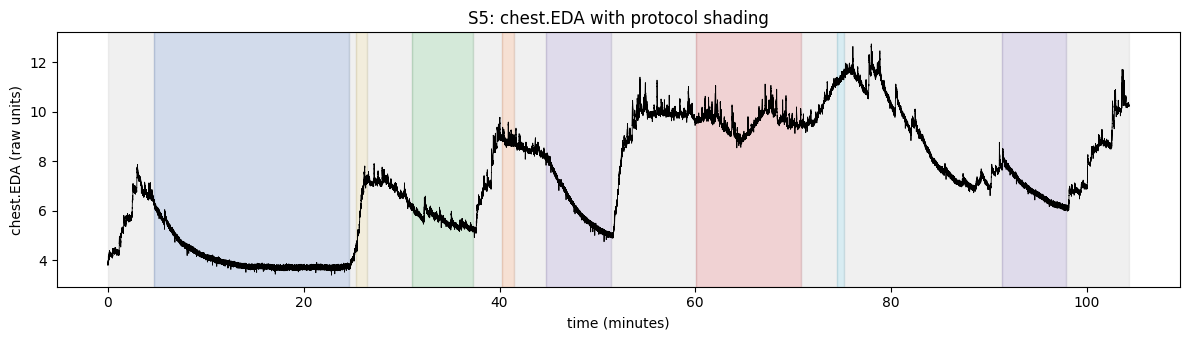

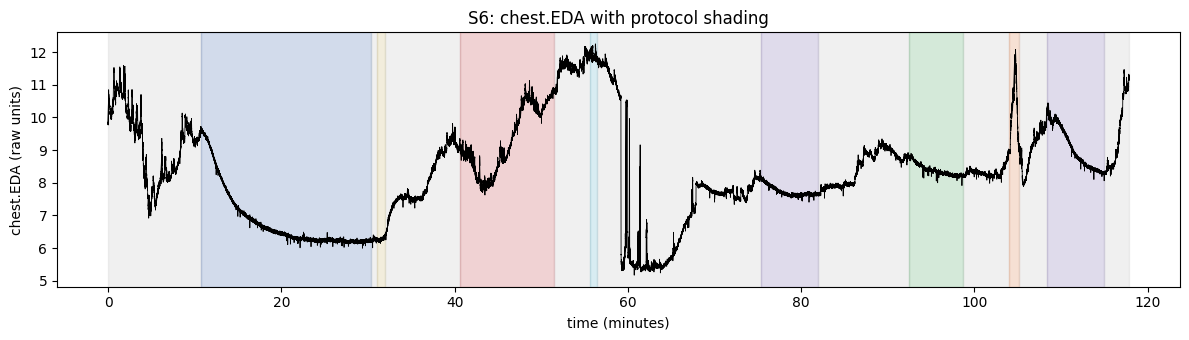

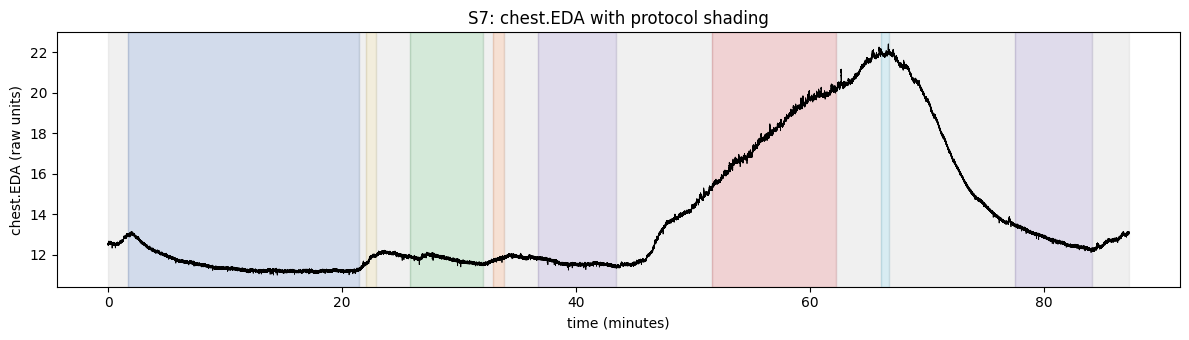

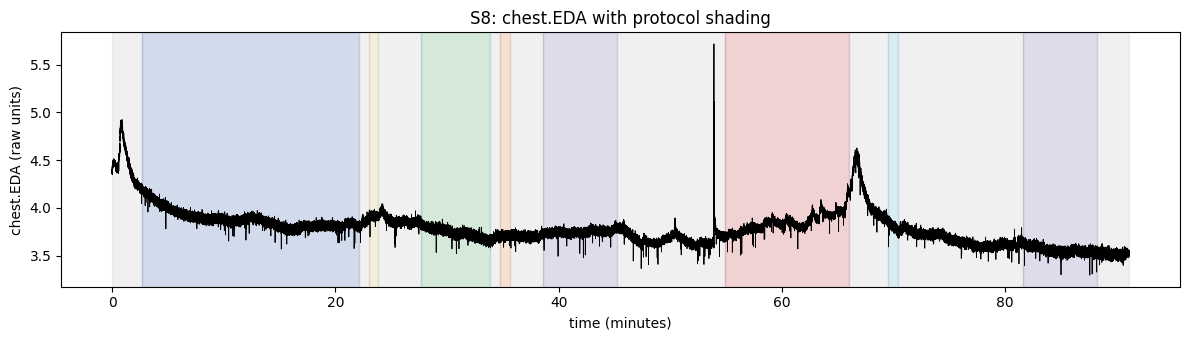

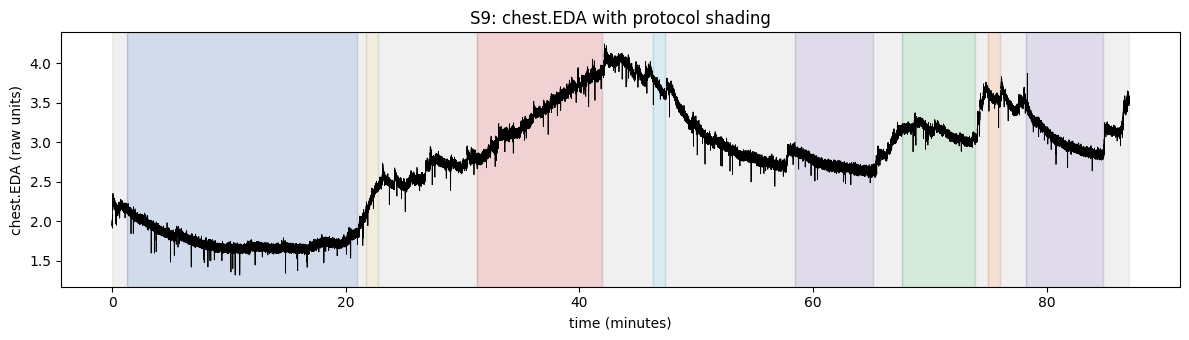

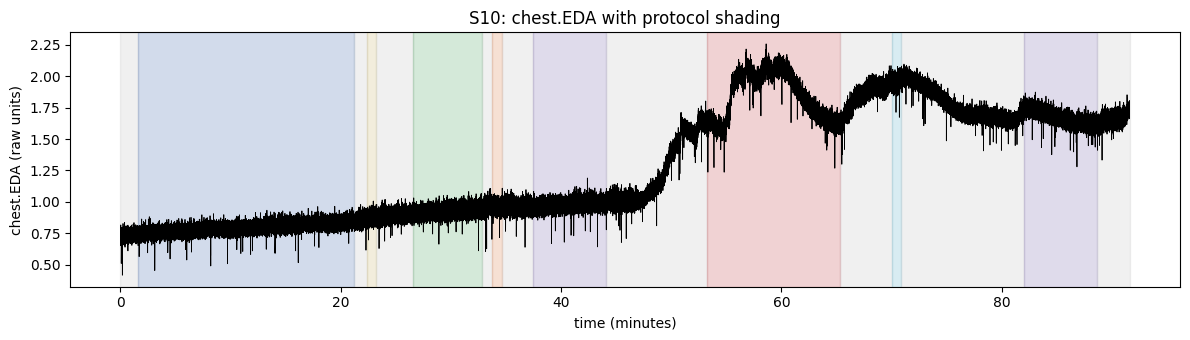

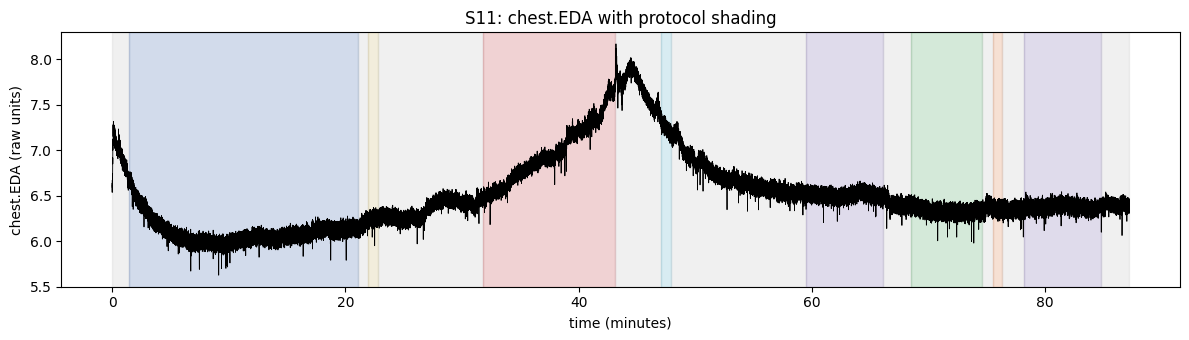

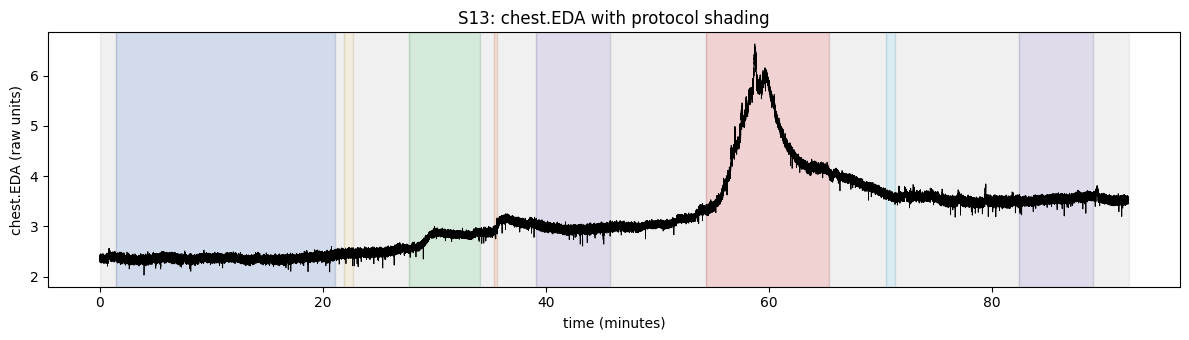

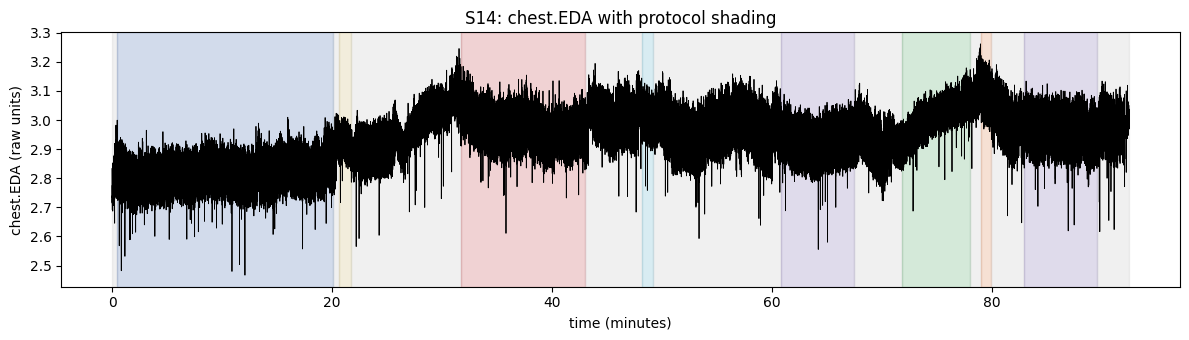

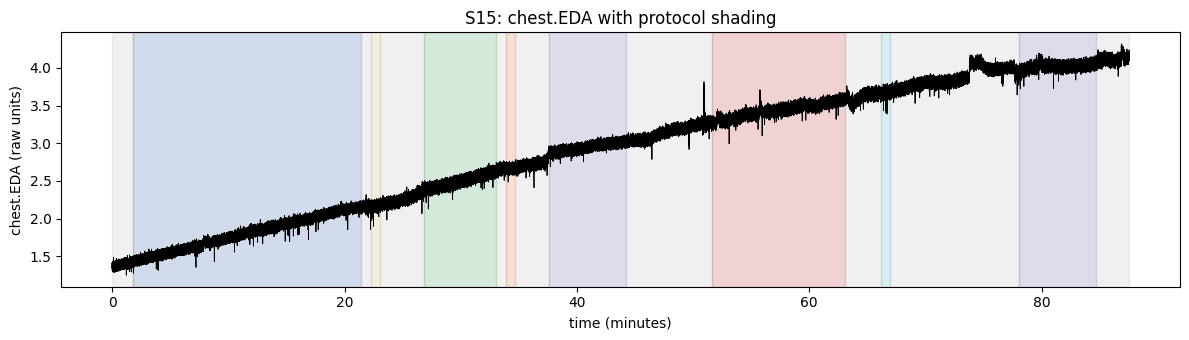

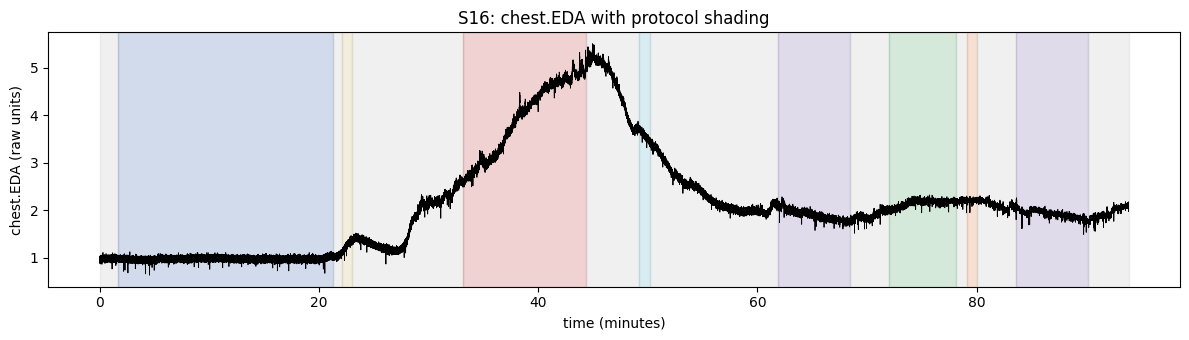

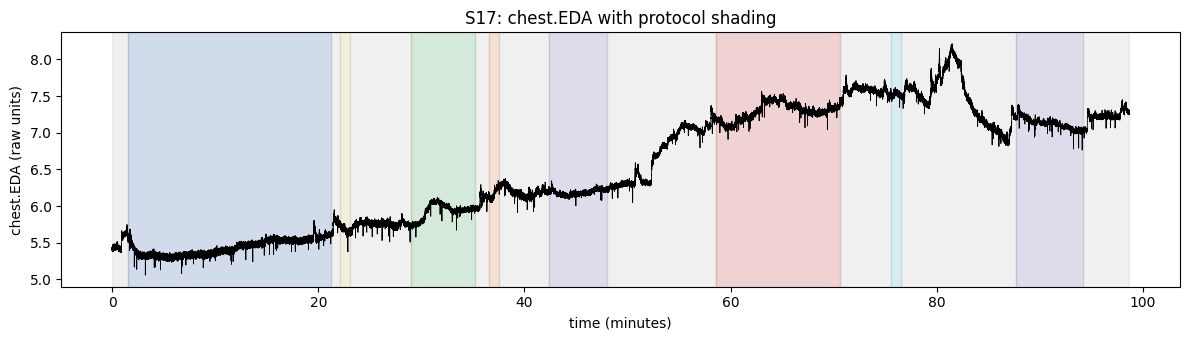

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="EDA")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

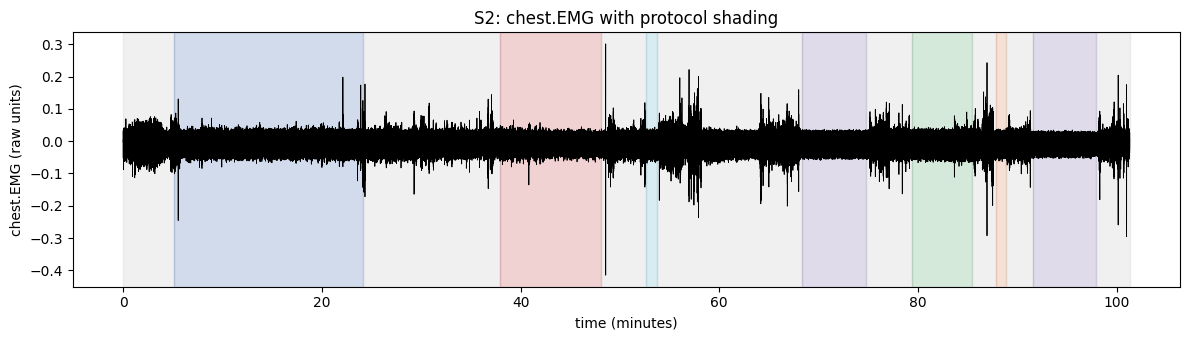

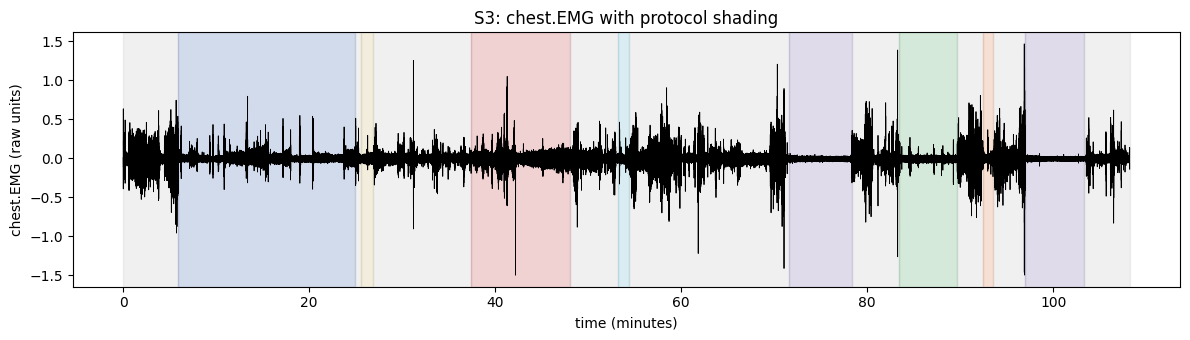

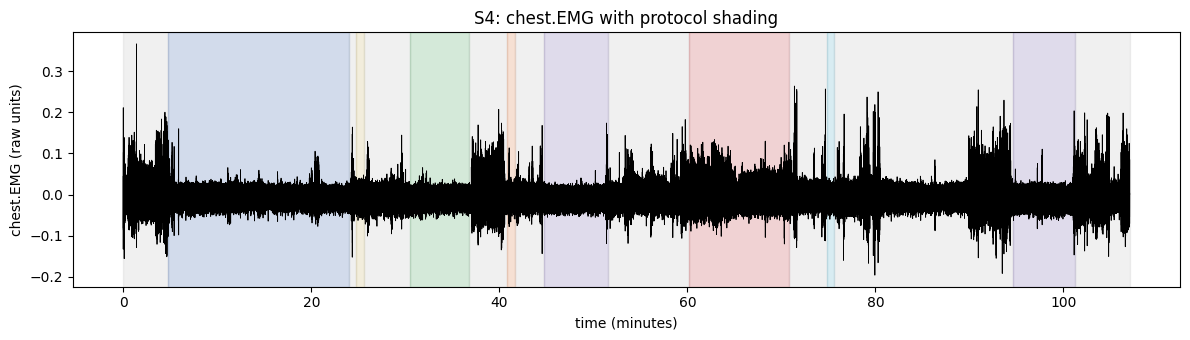

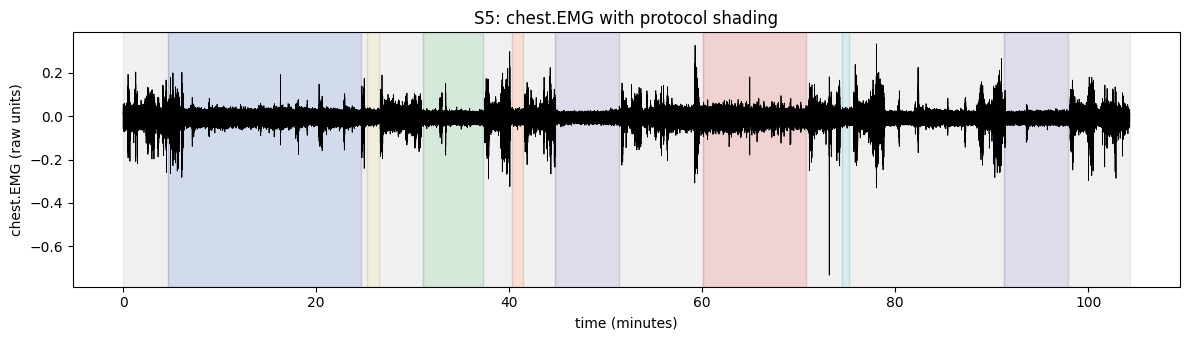

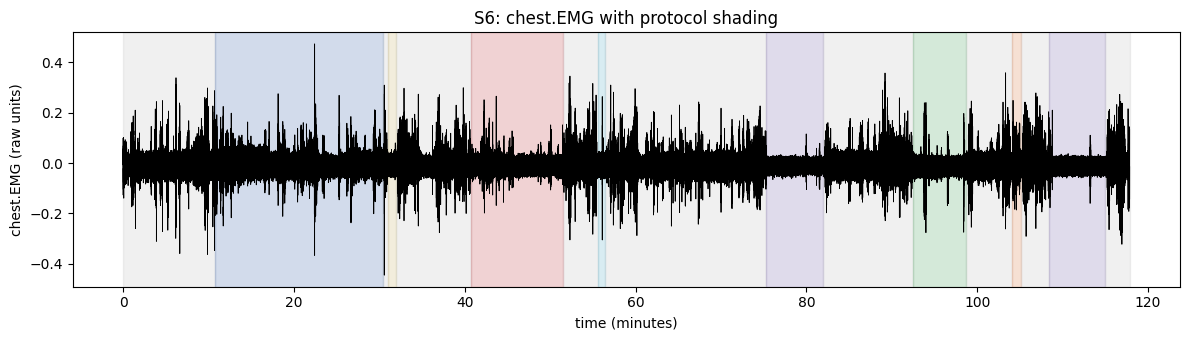

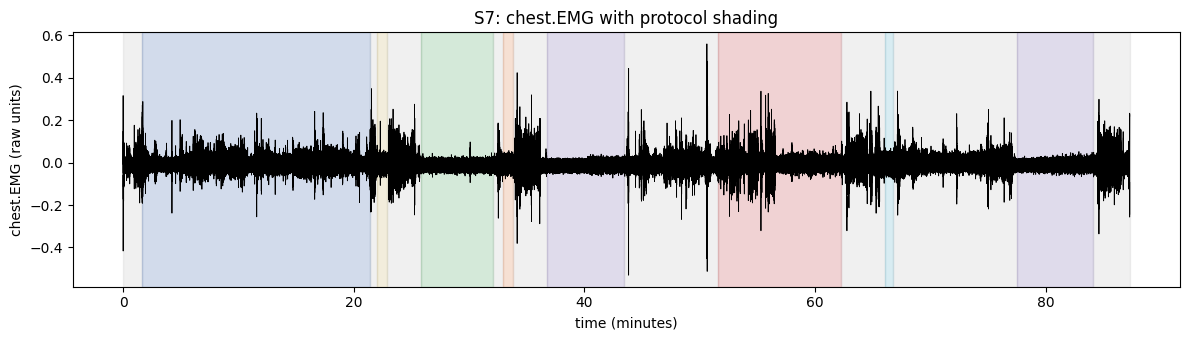

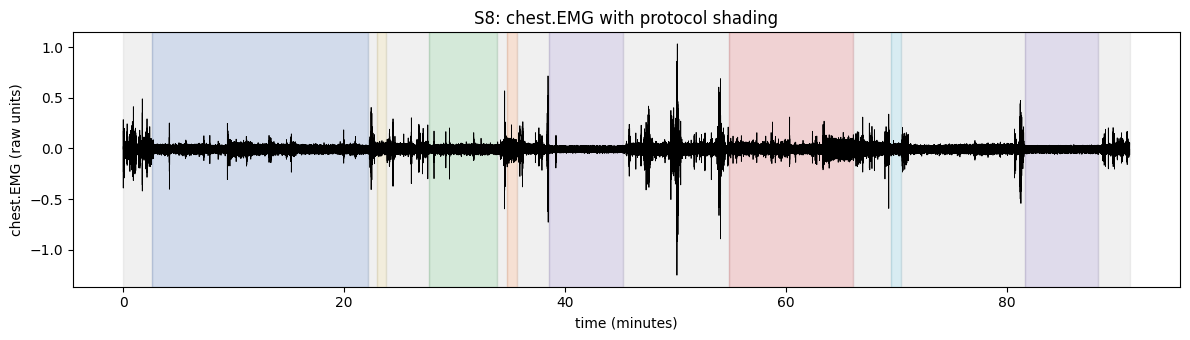

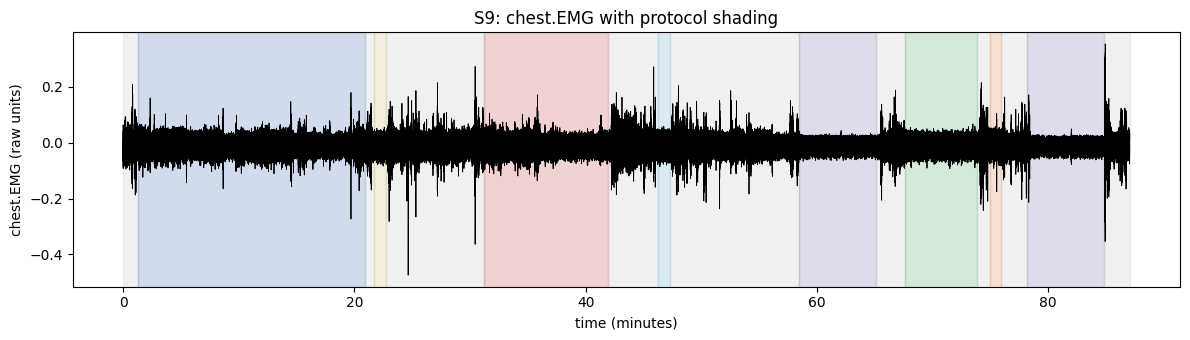

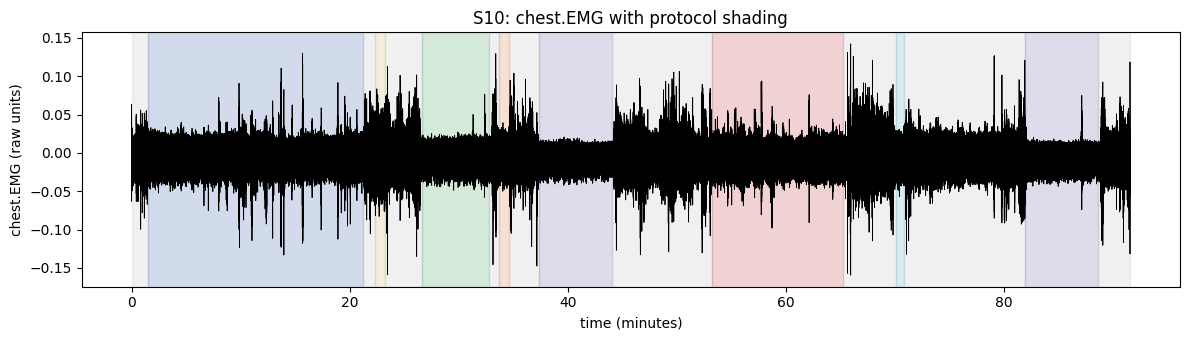

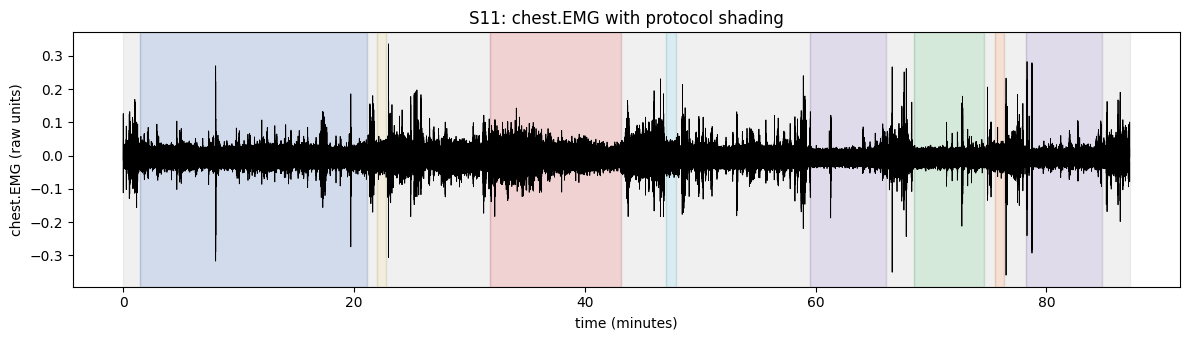

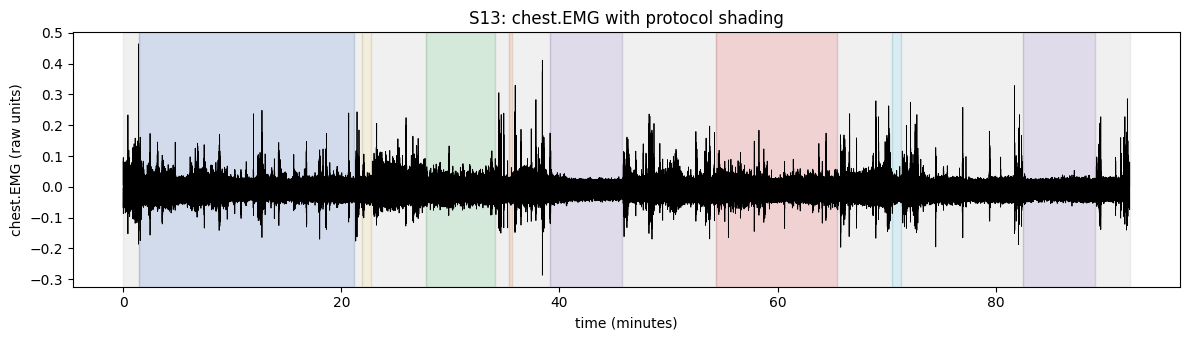

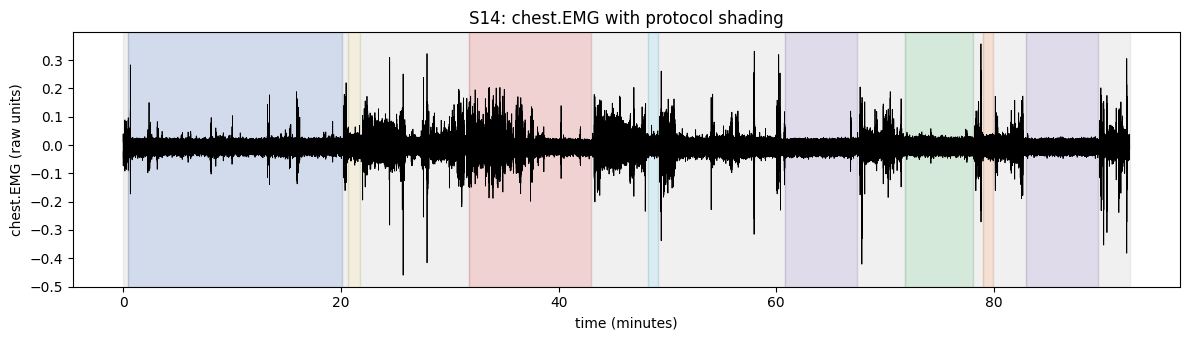

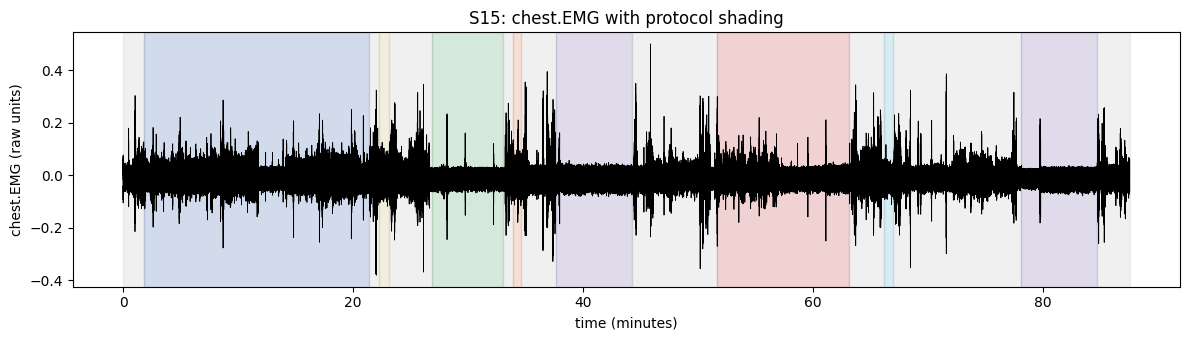

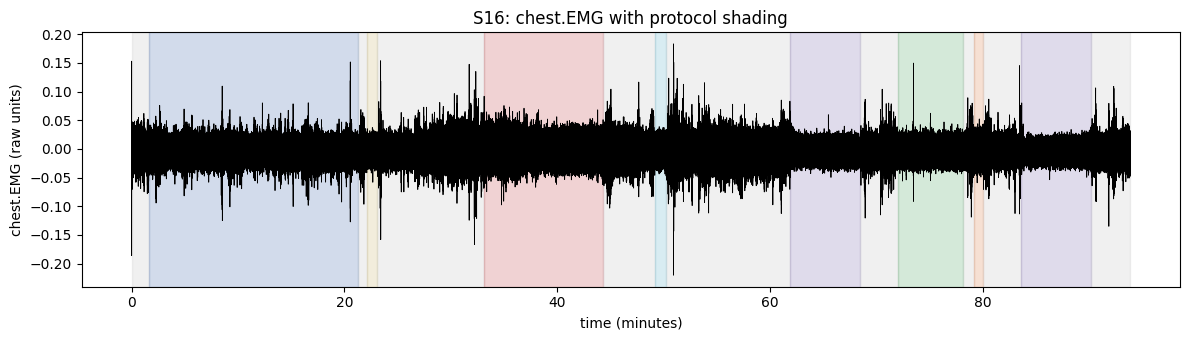

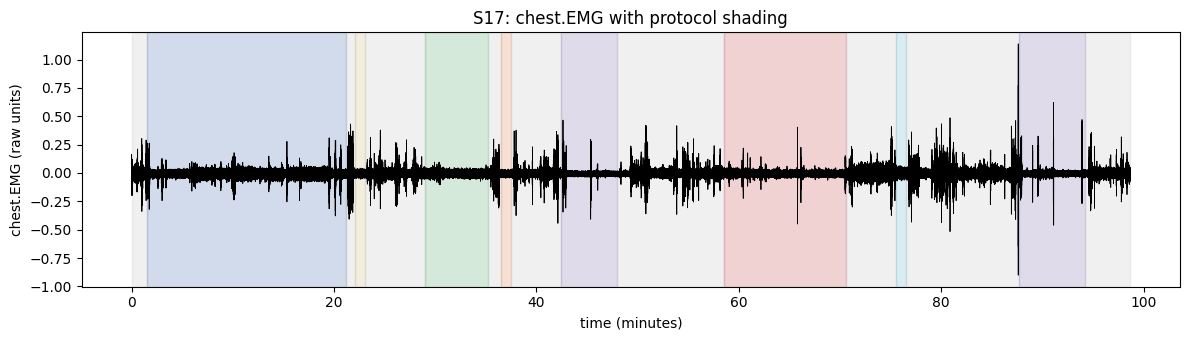

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="EMG")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

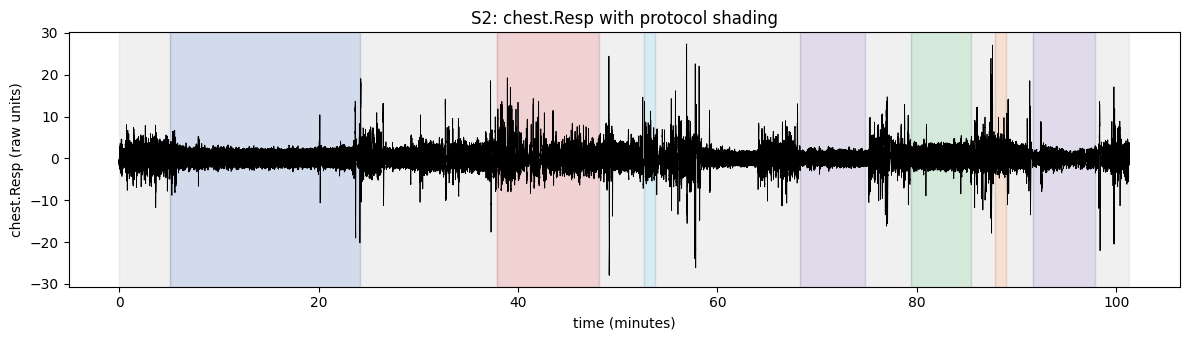

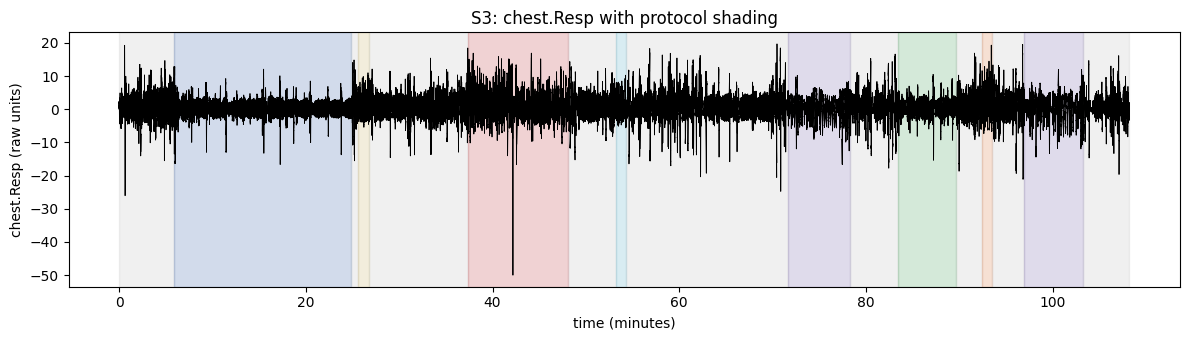

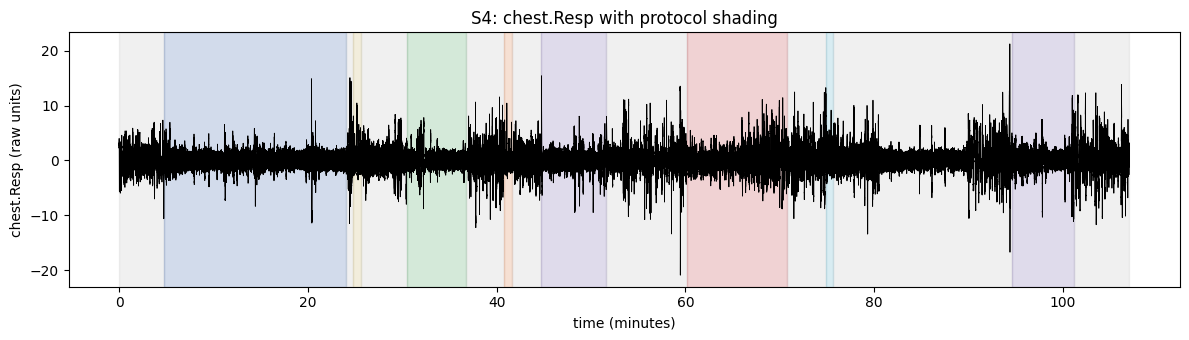

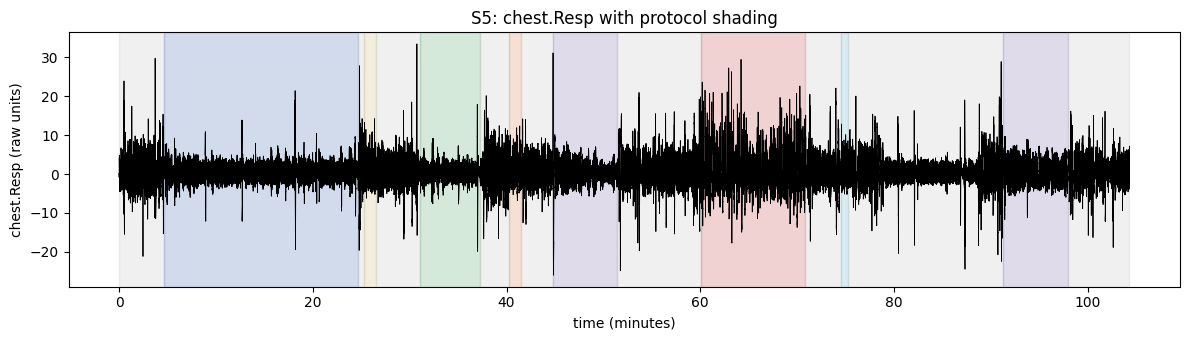

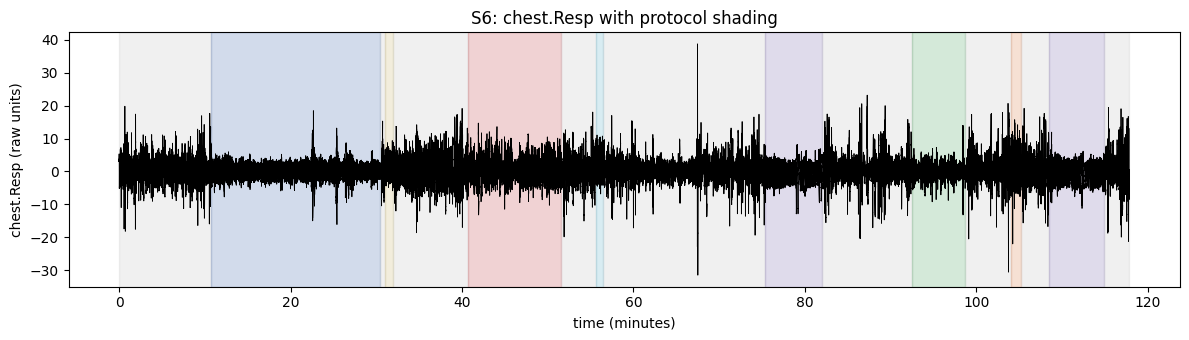

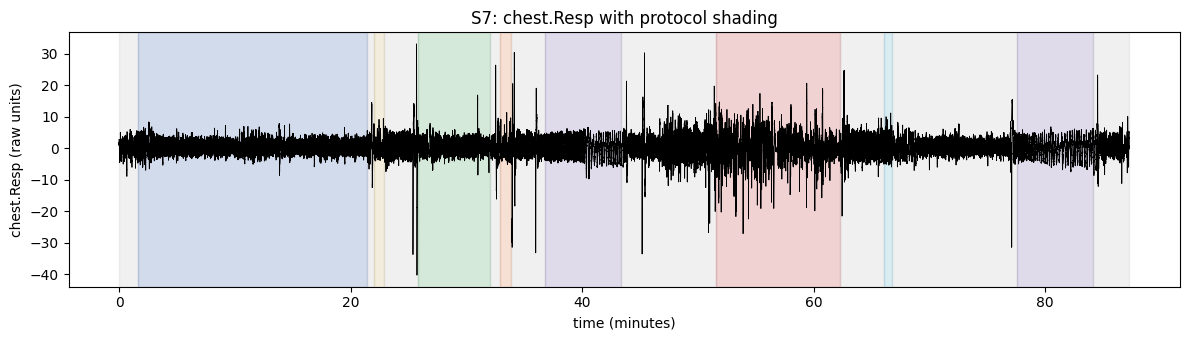

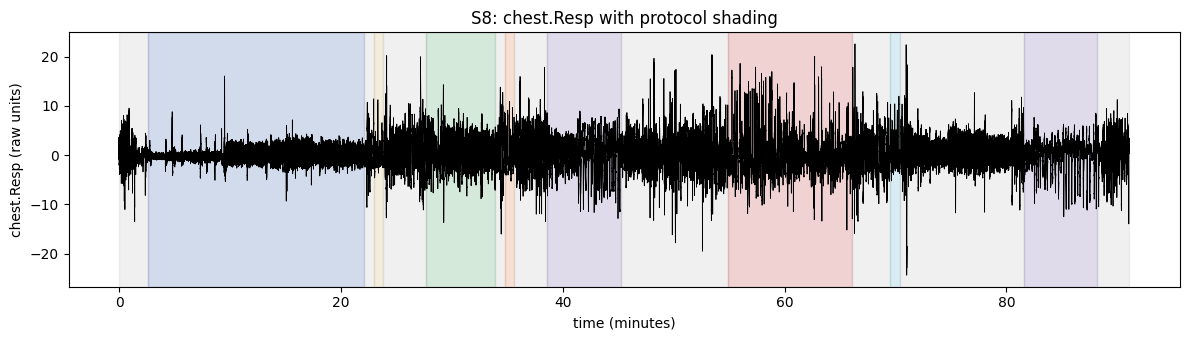

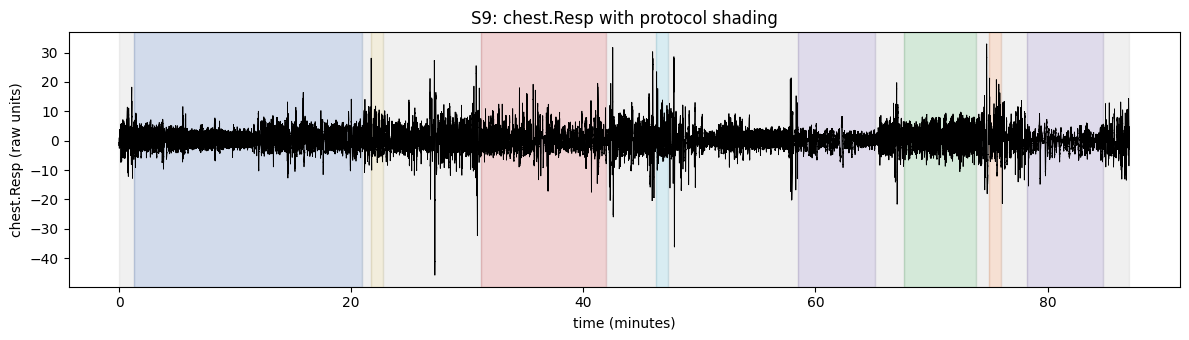

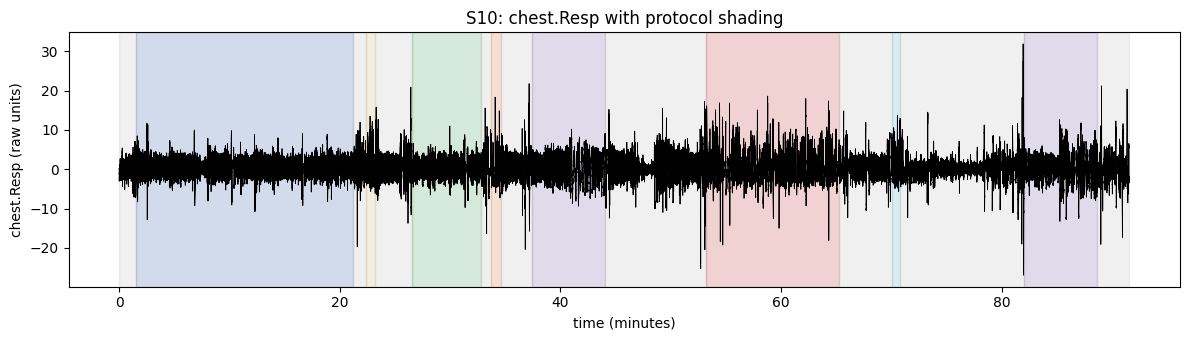

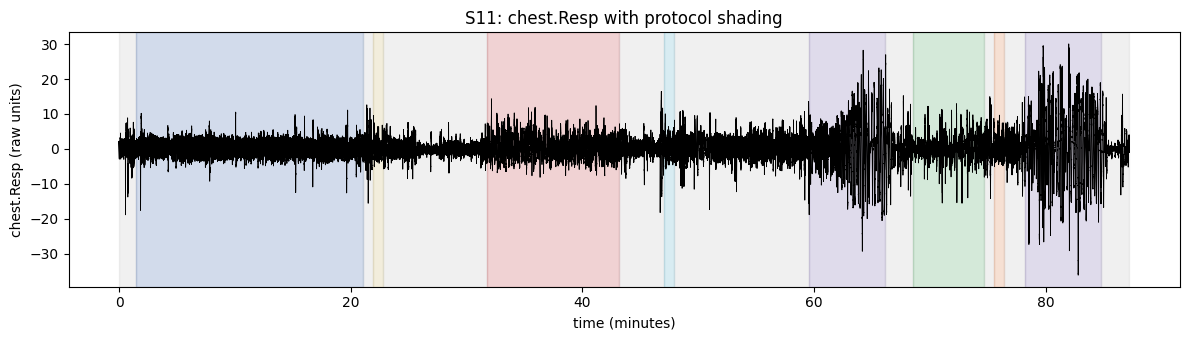

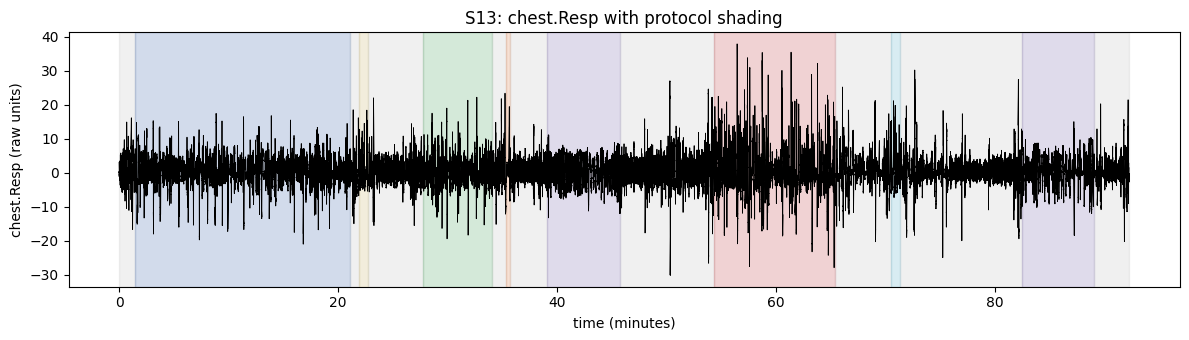

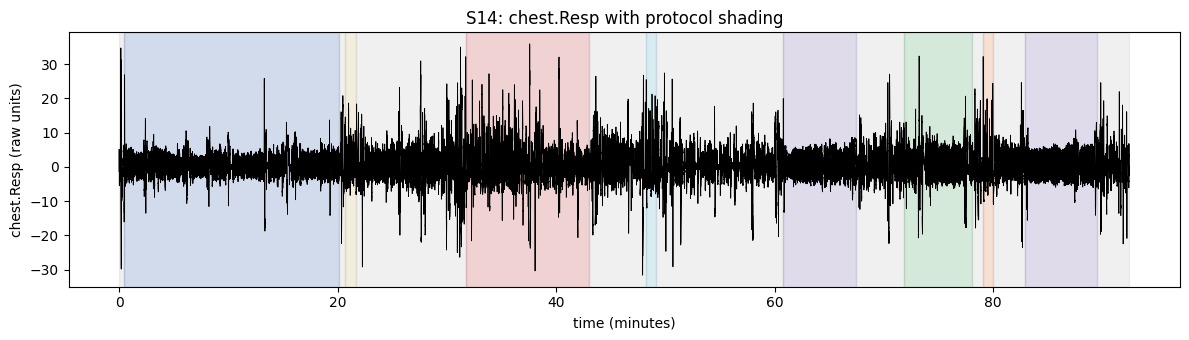

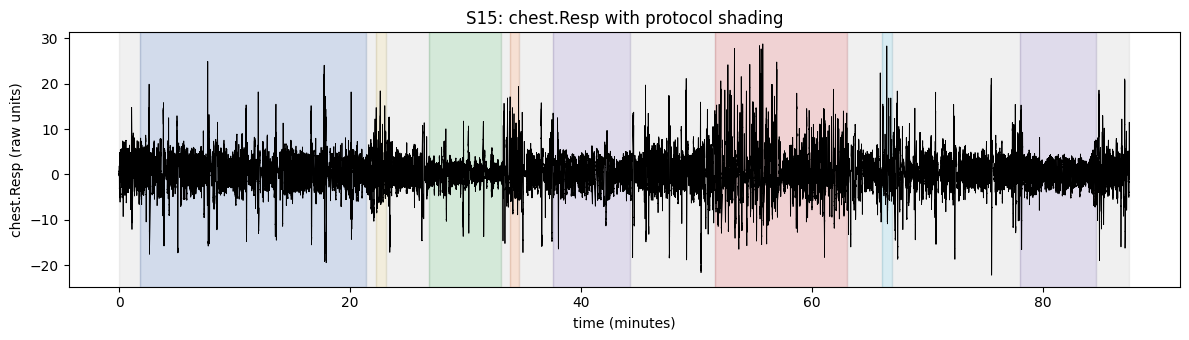

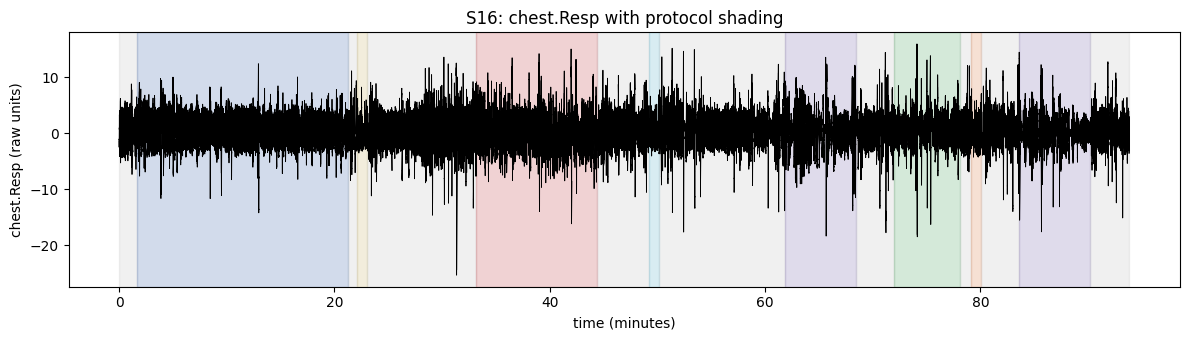

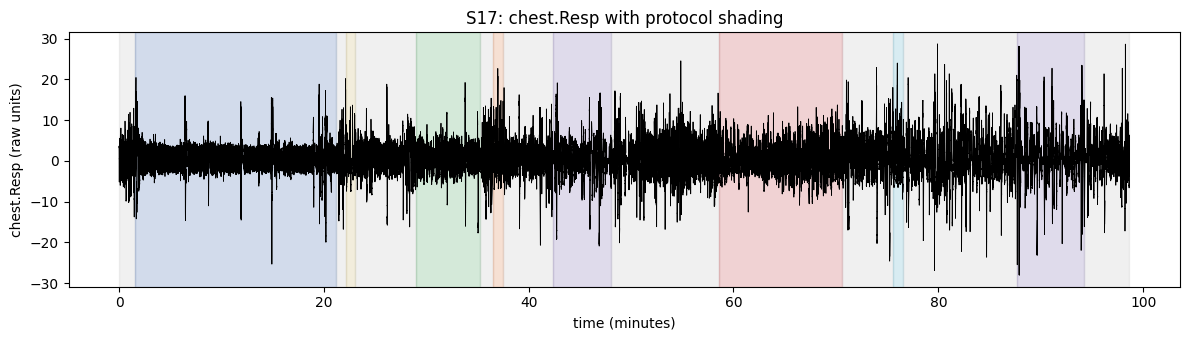

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="Resp")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

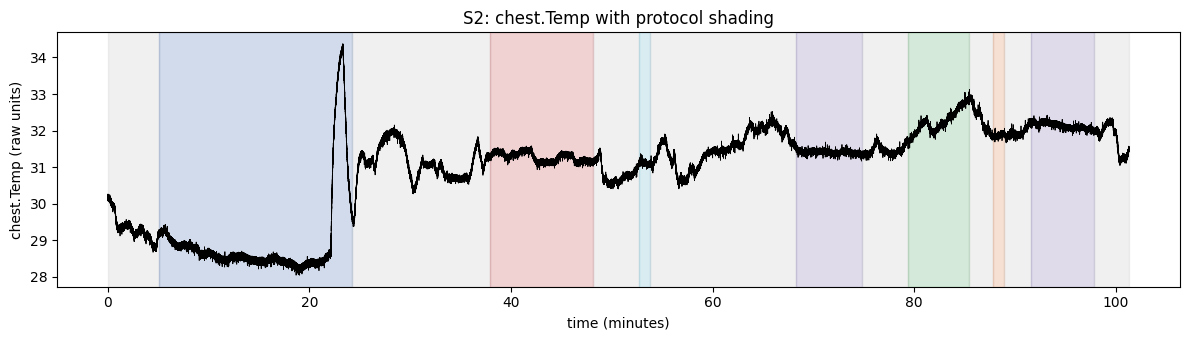

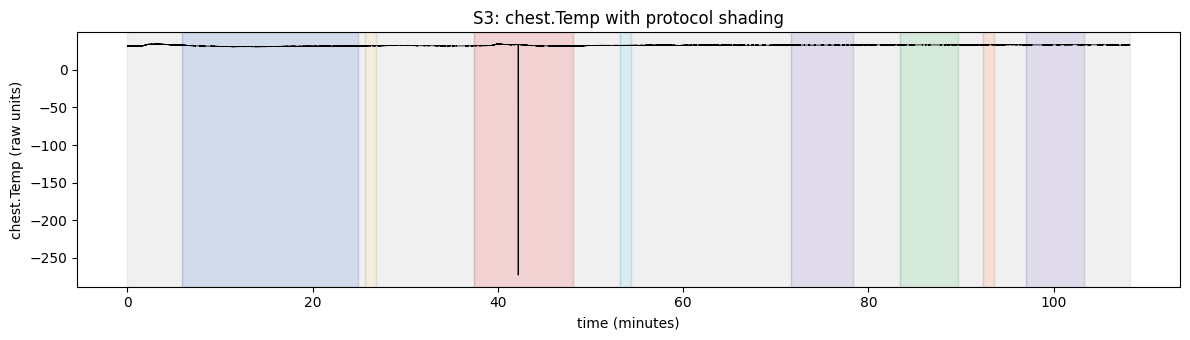

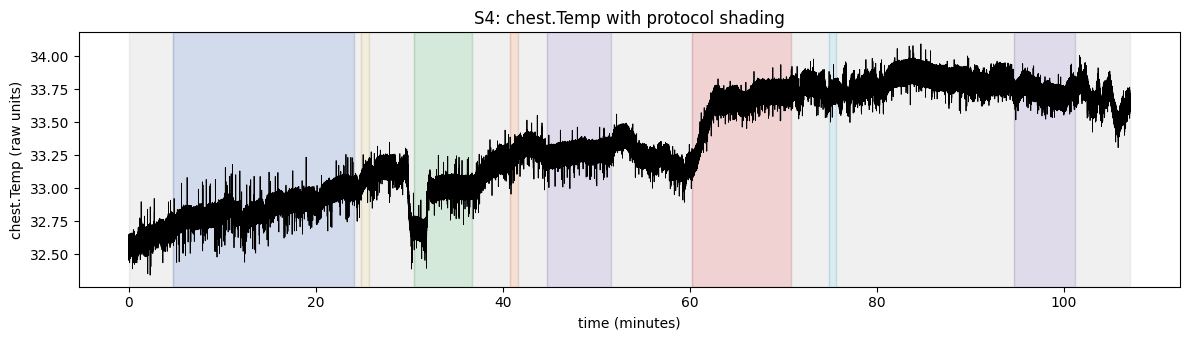

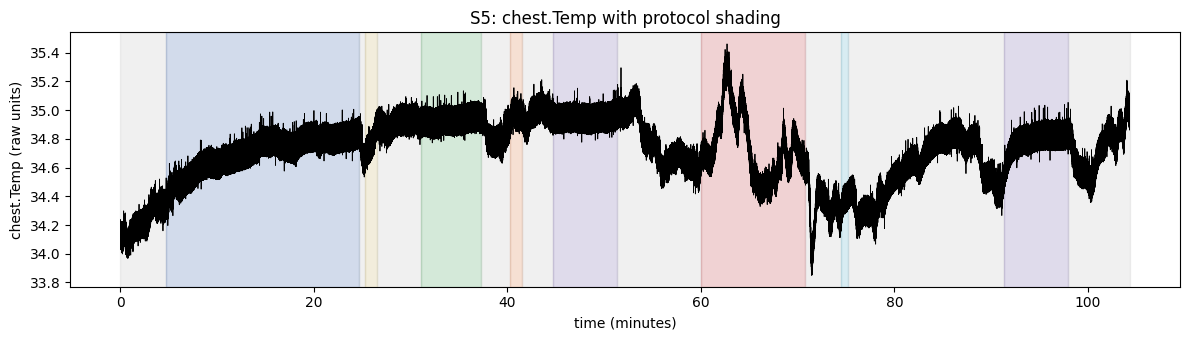

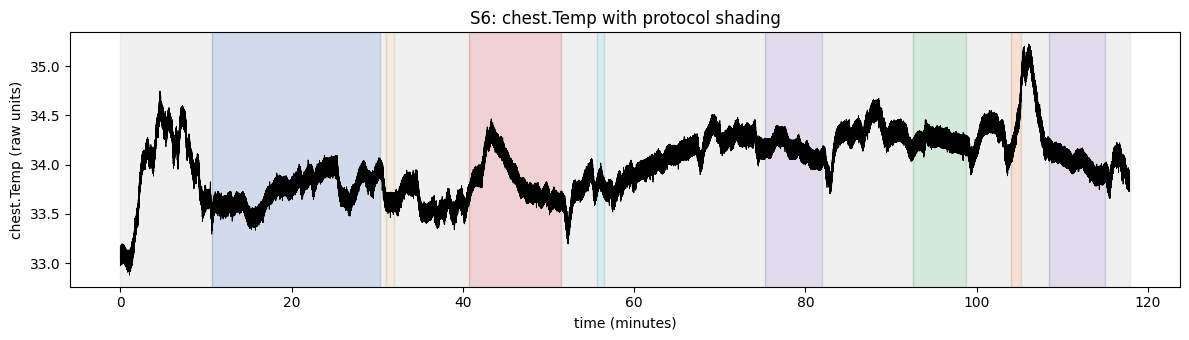

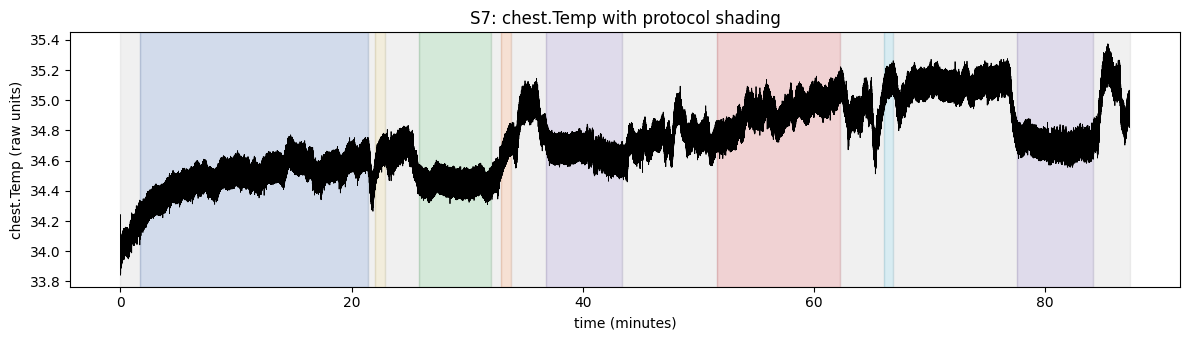

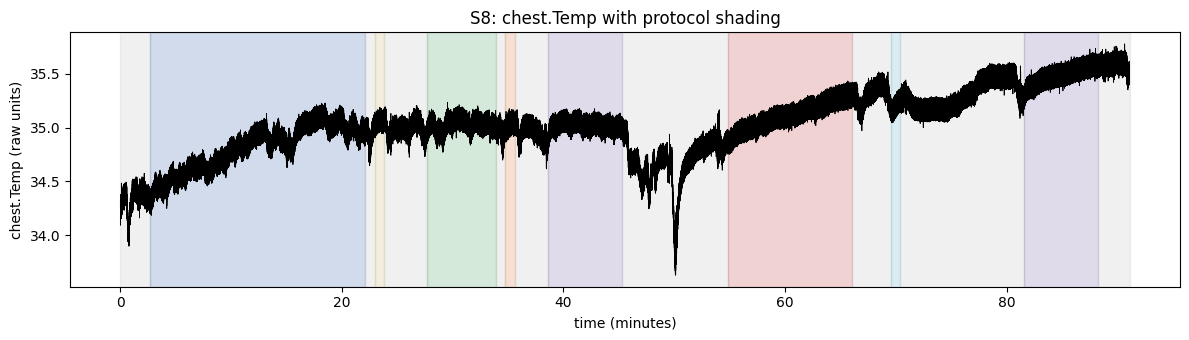

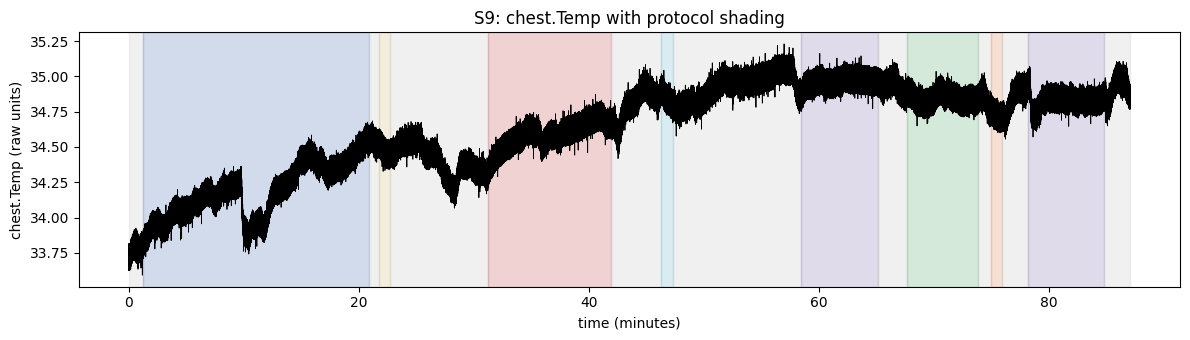

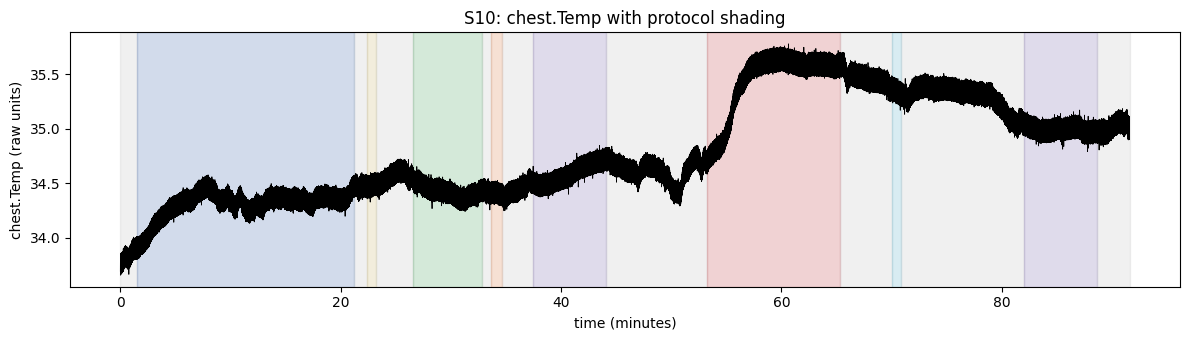

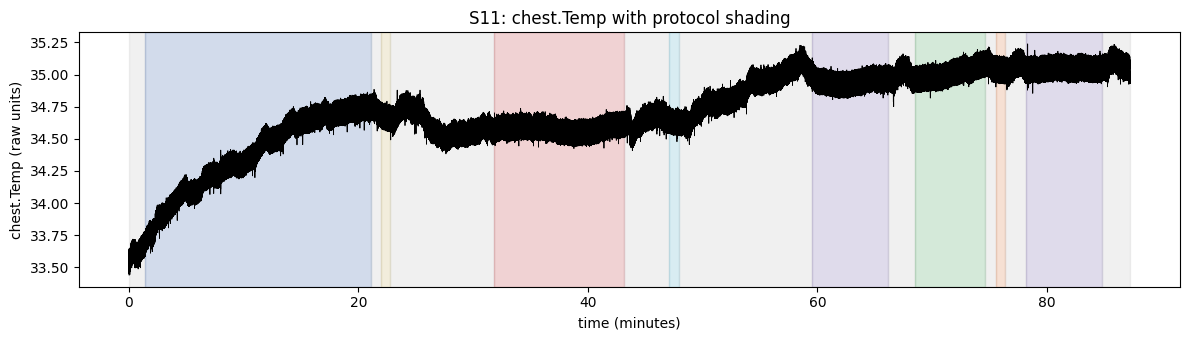

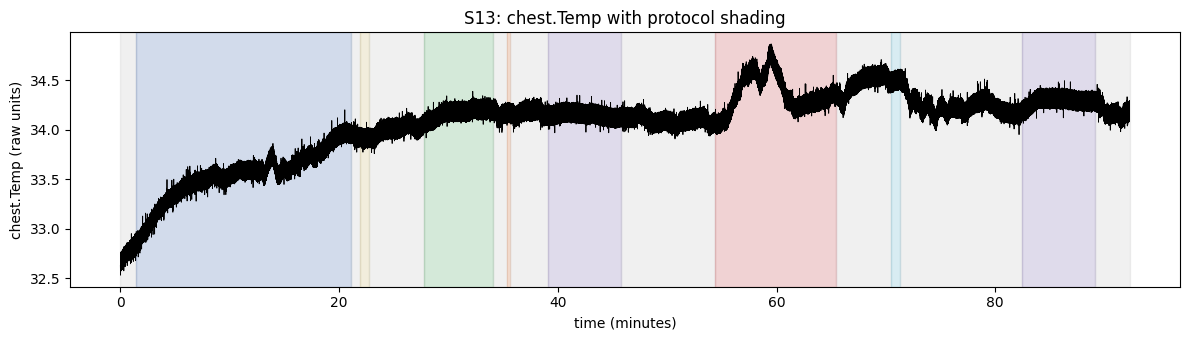

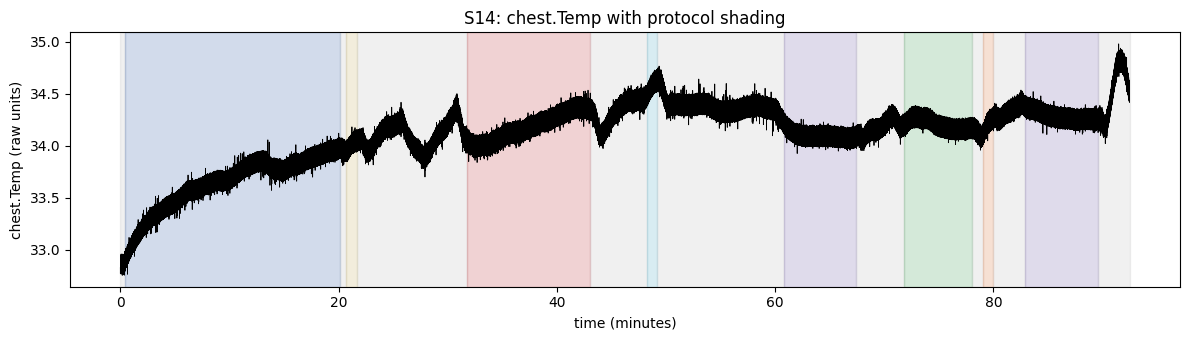

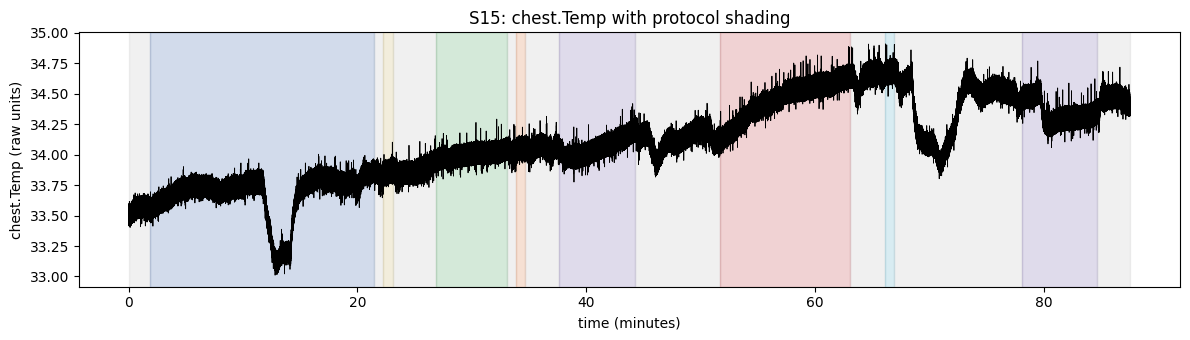

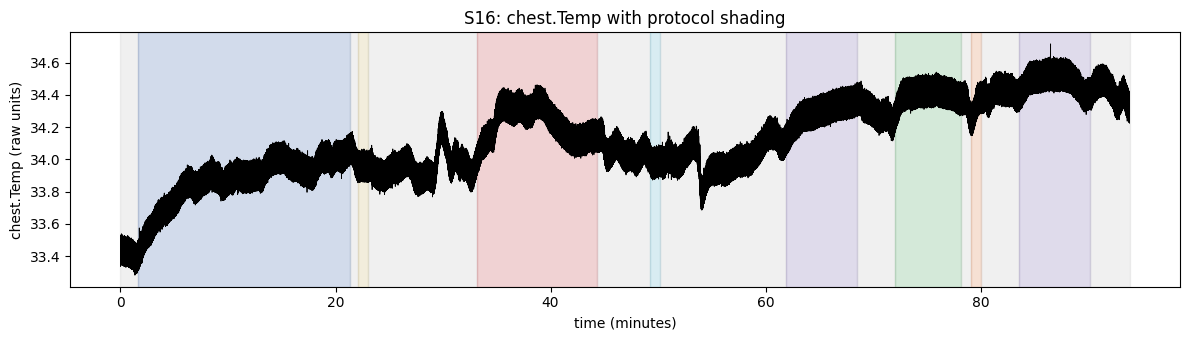

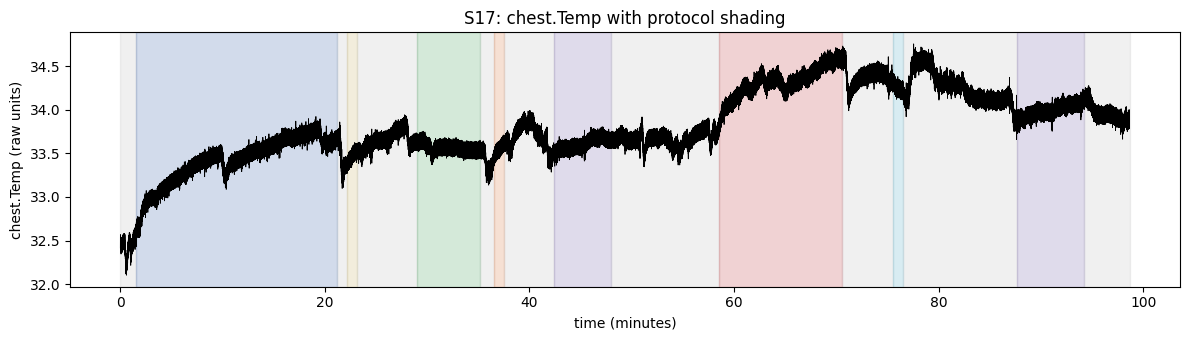

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="chest", channel="Temp")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

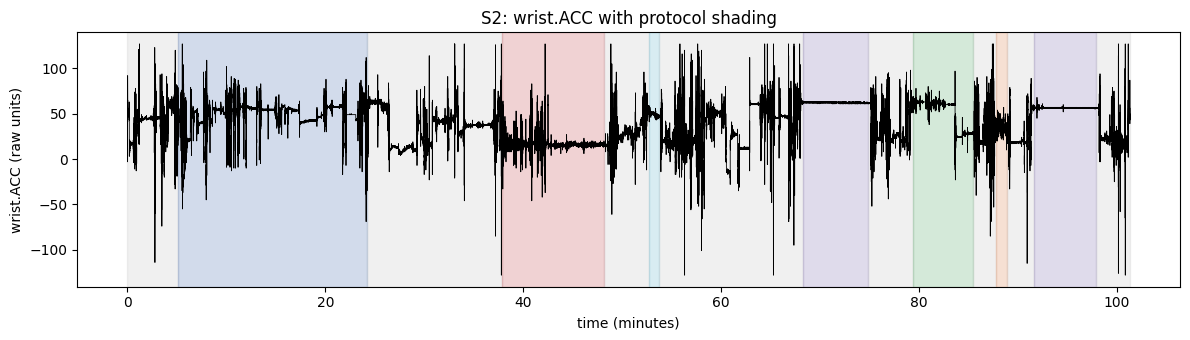

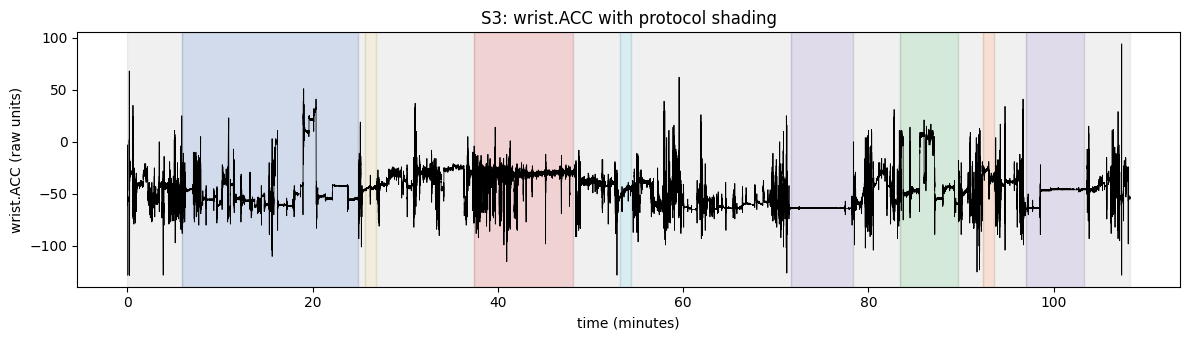

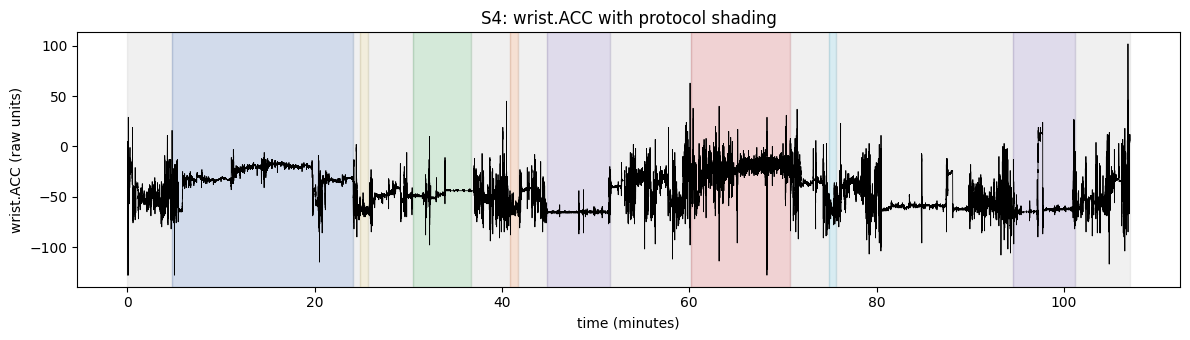

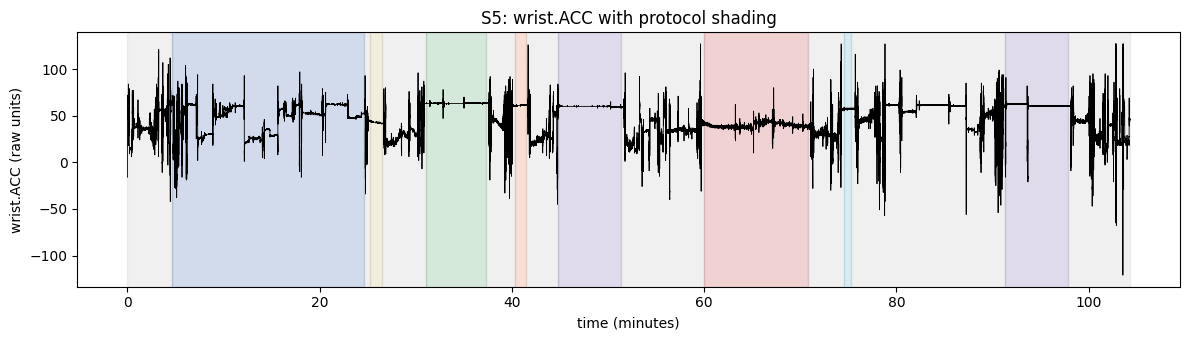

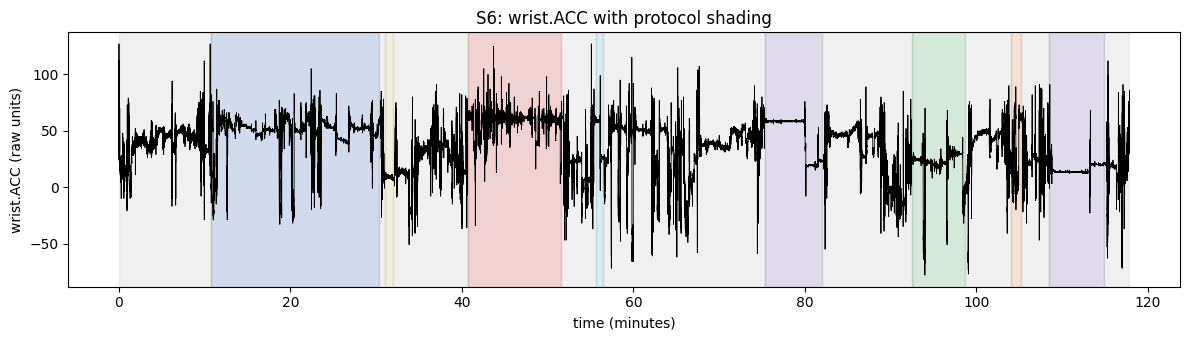

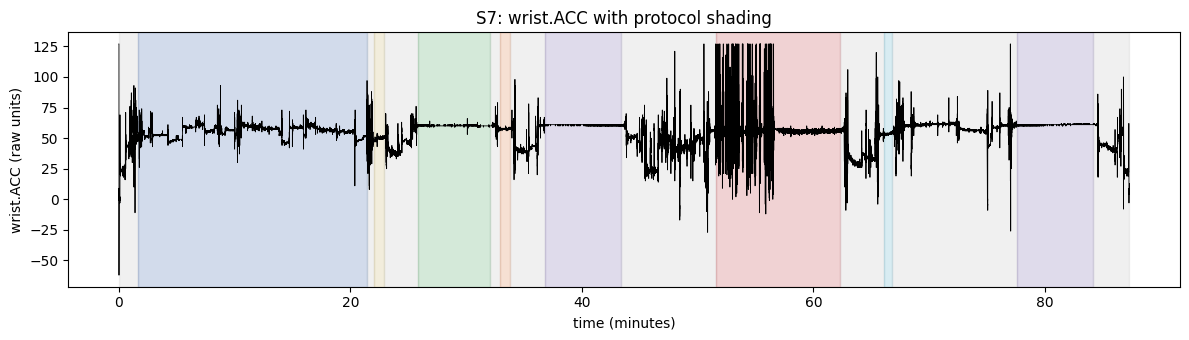

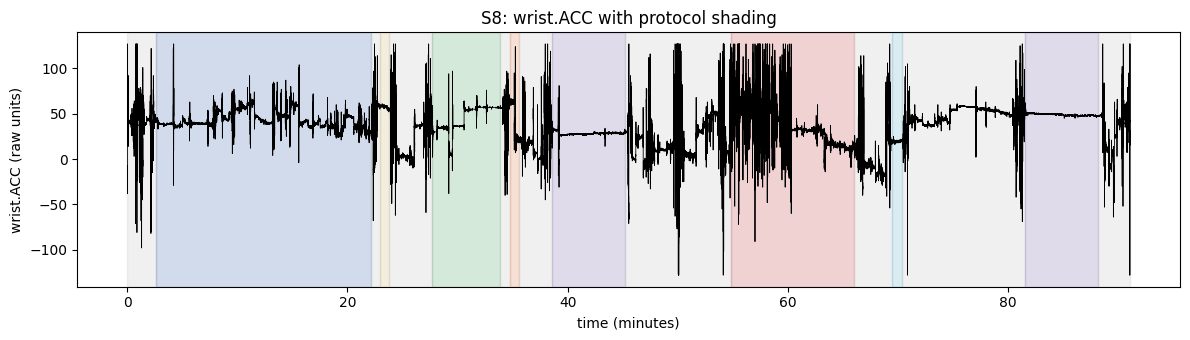

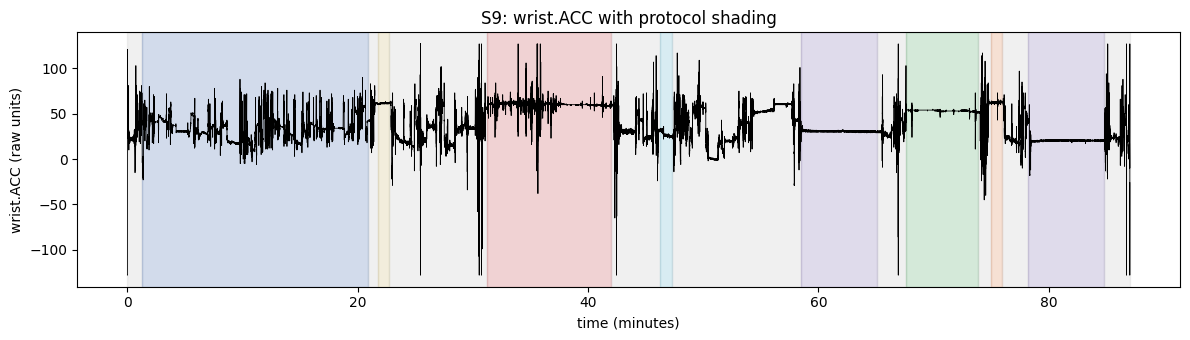

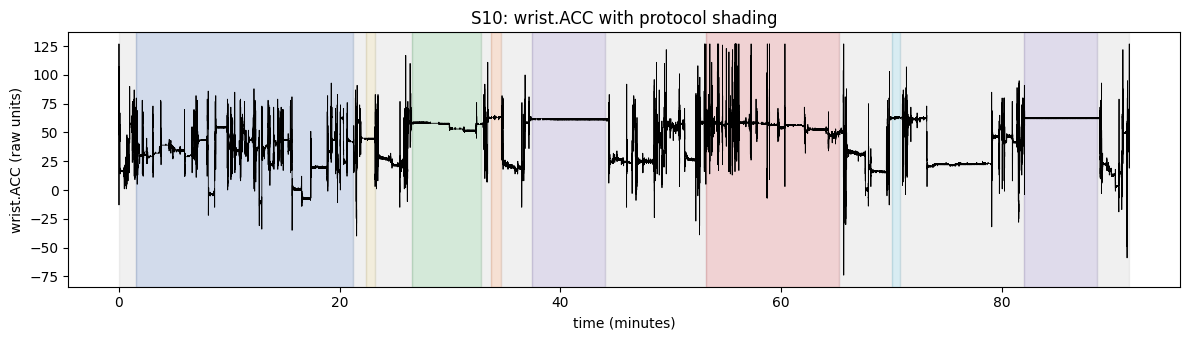

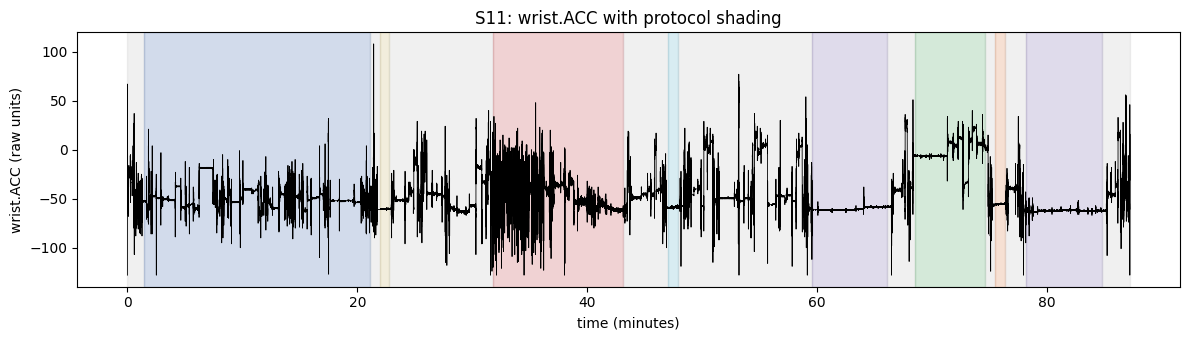

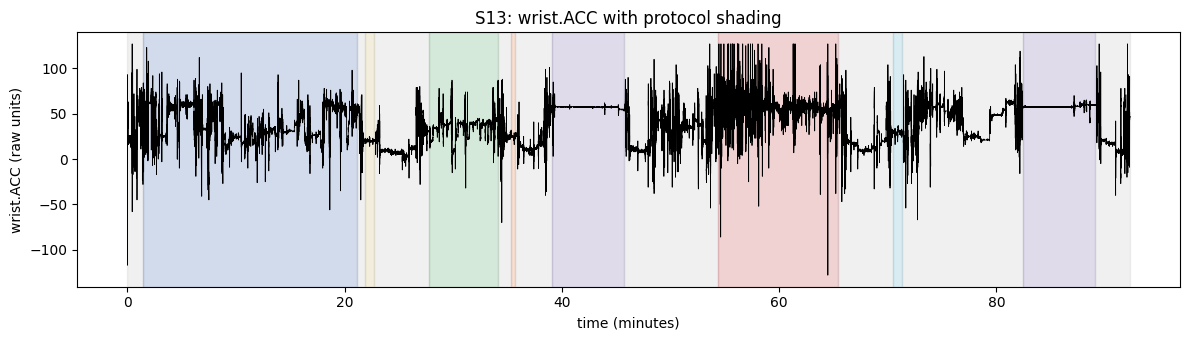

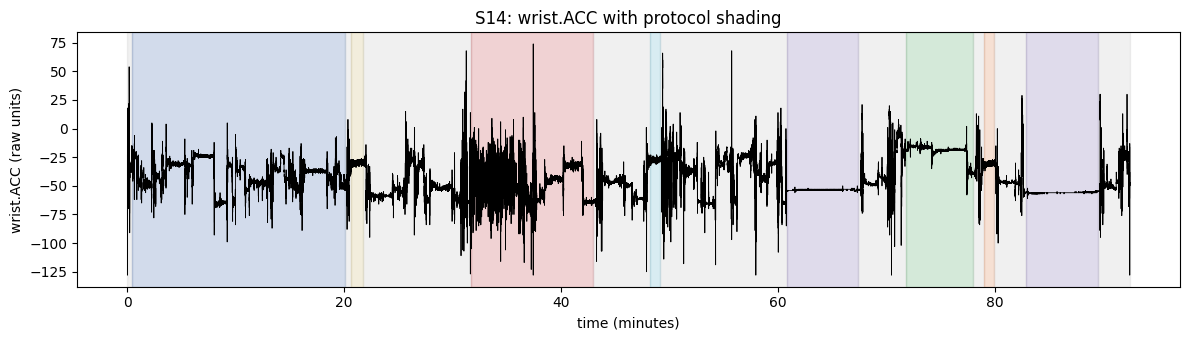

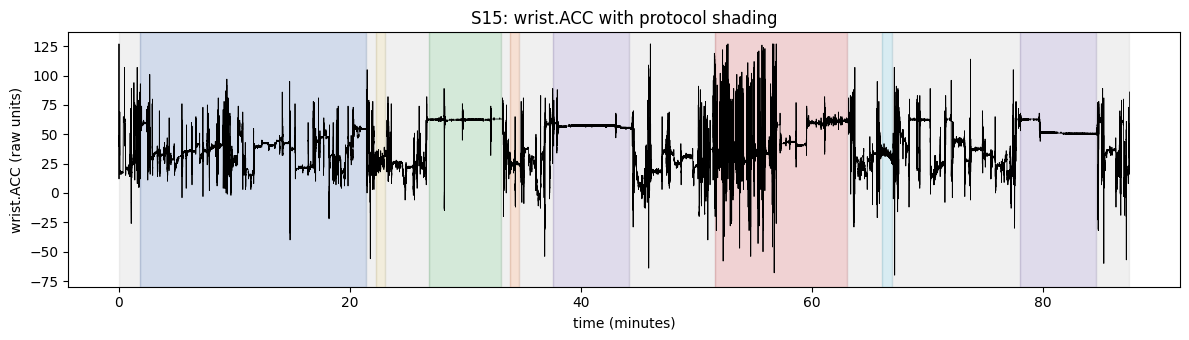

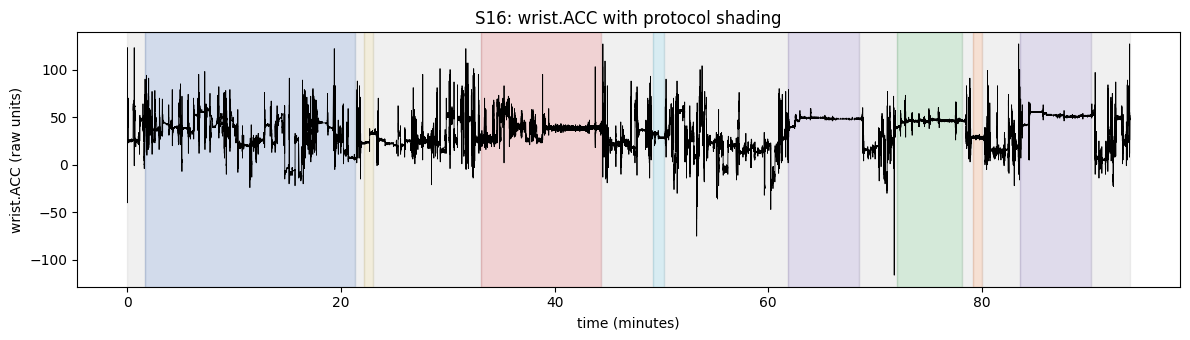

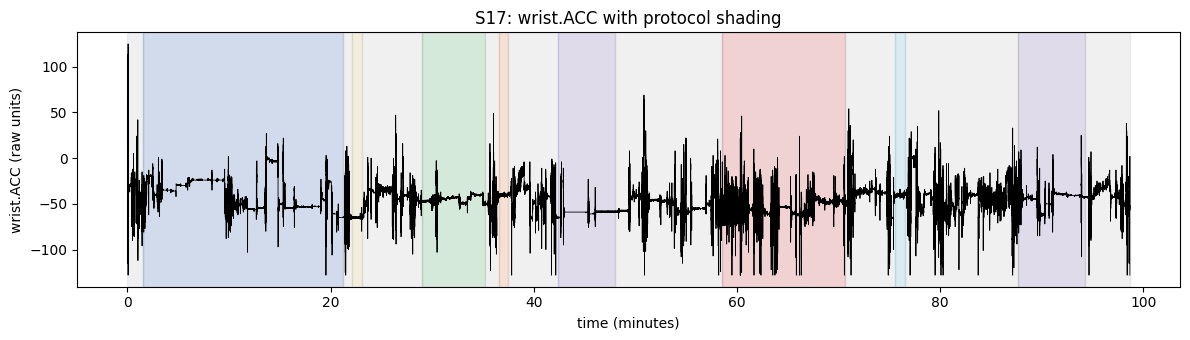

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="wrist", channel="ACC")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

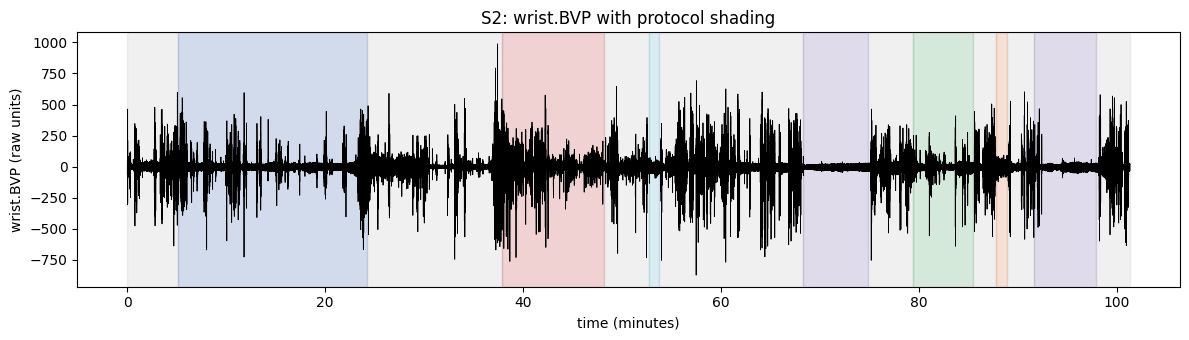

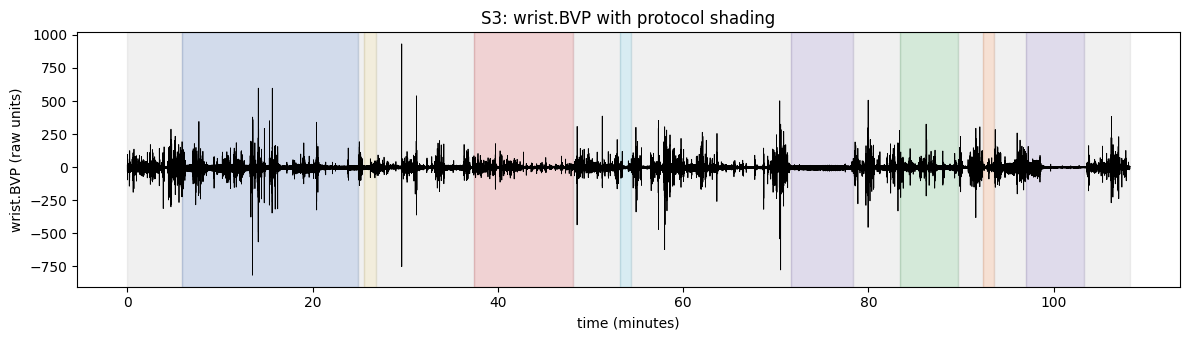

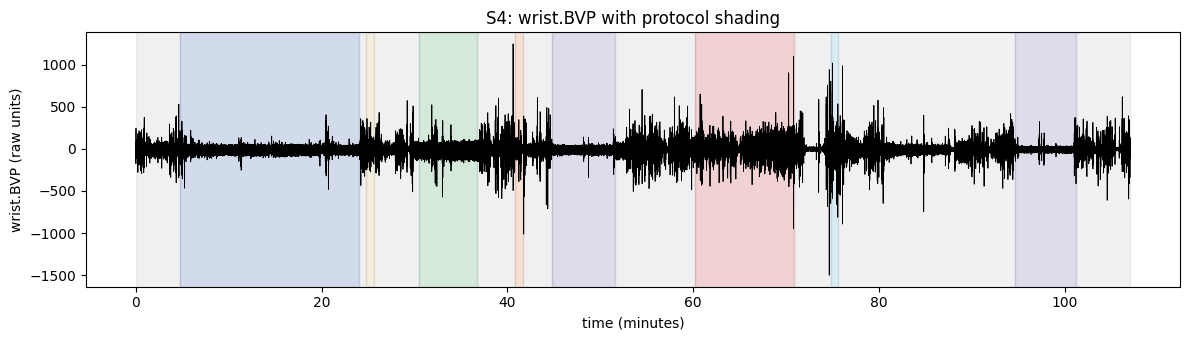

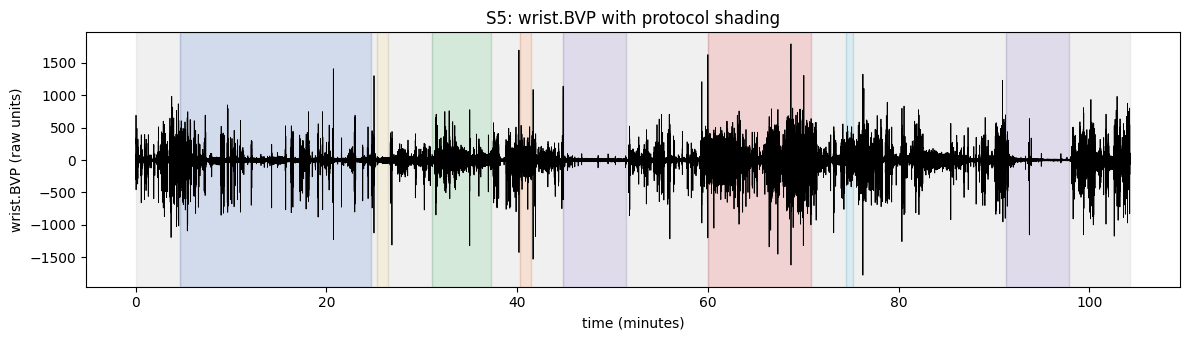

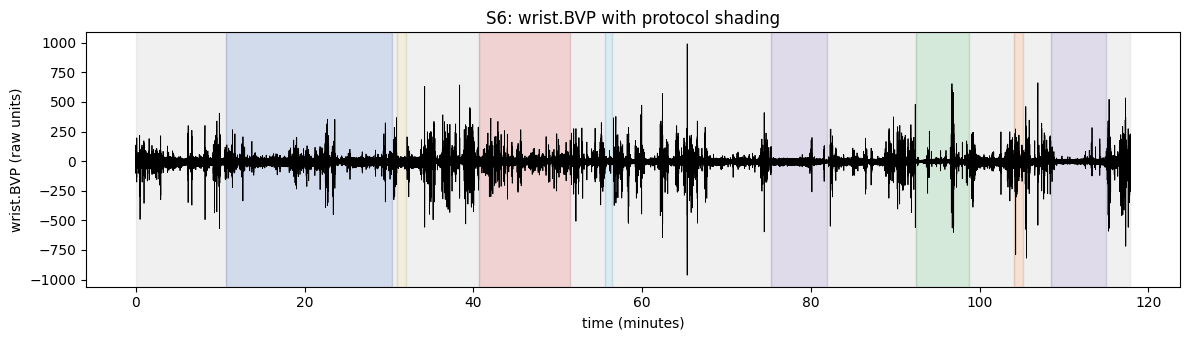

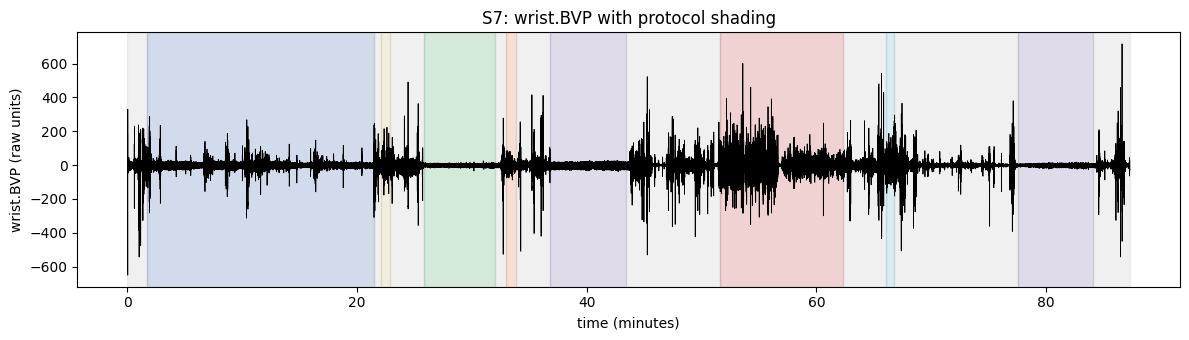

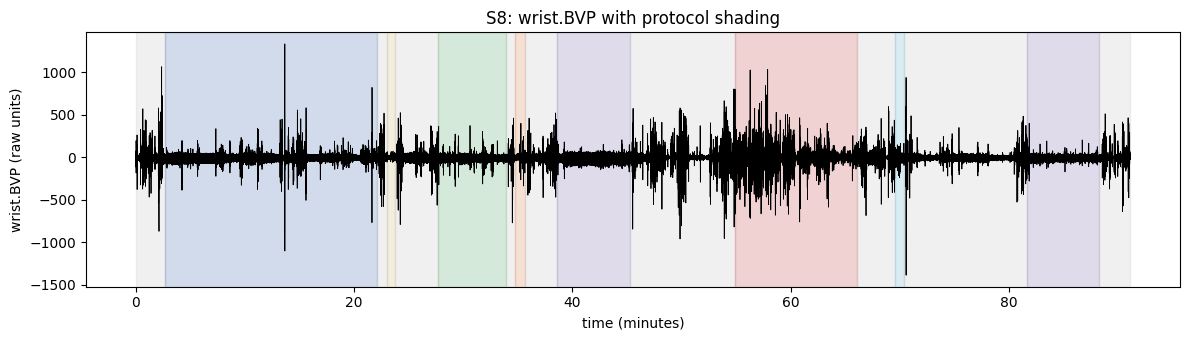

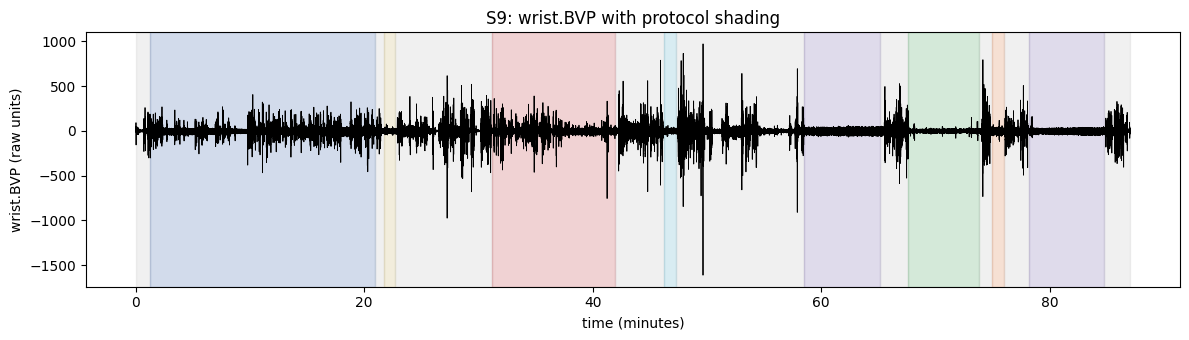

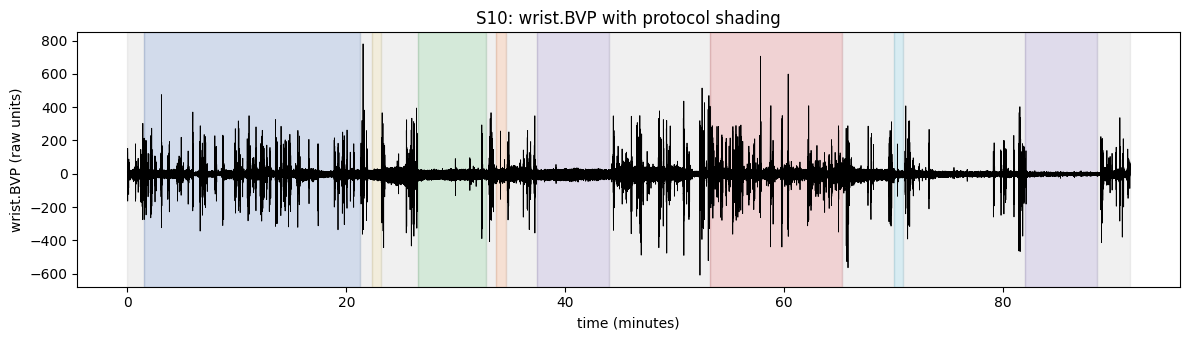

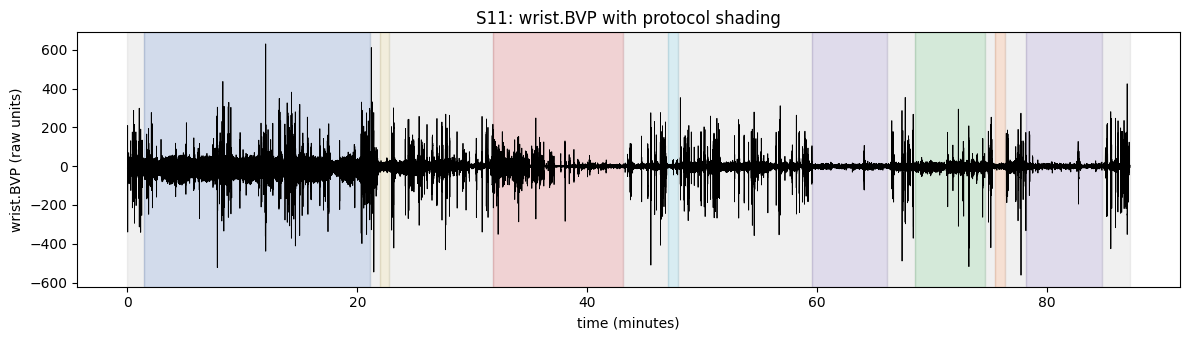

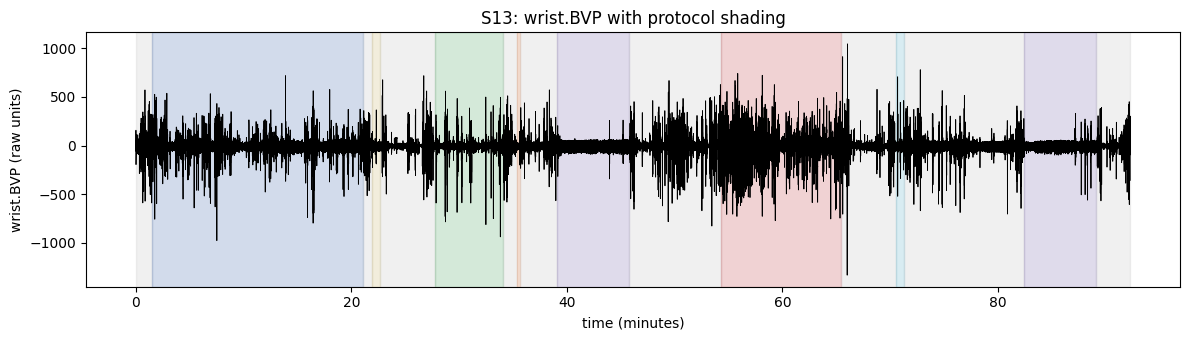

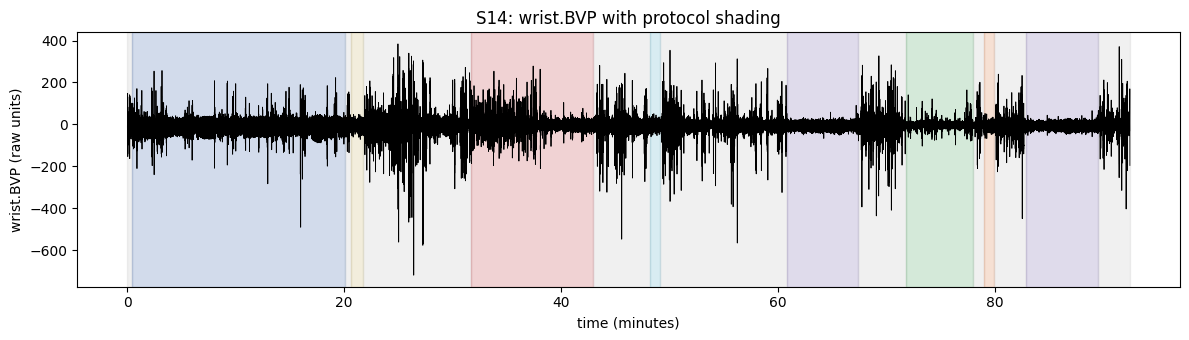

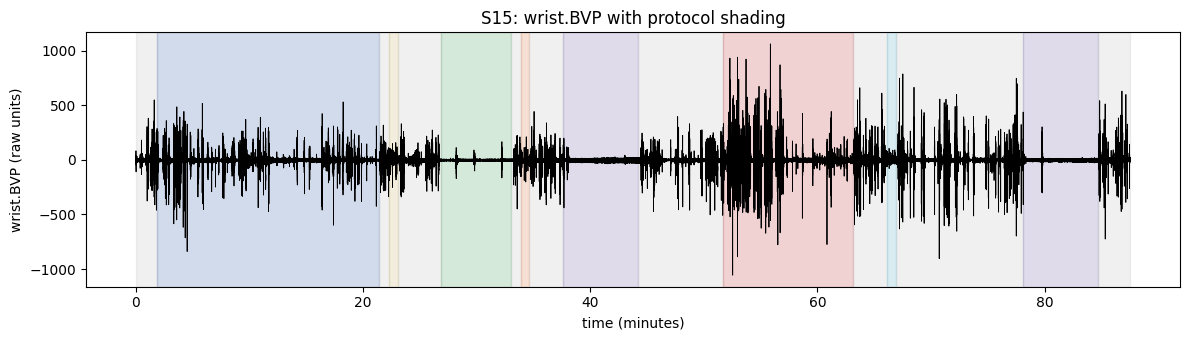

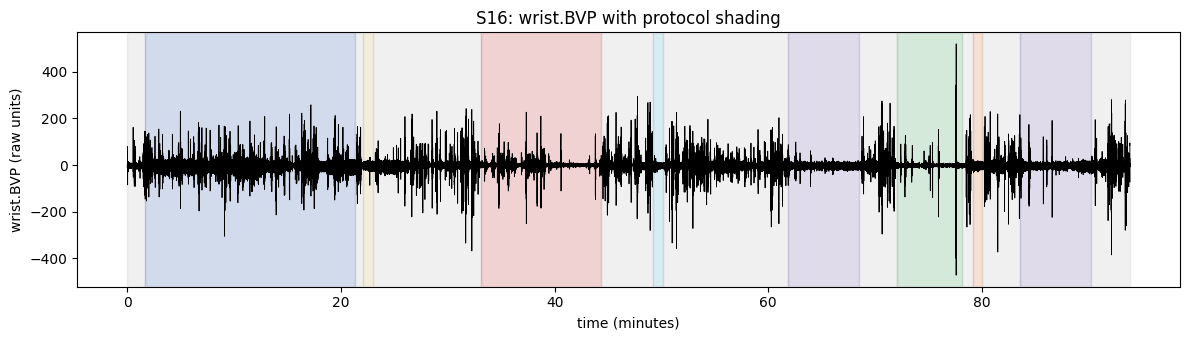

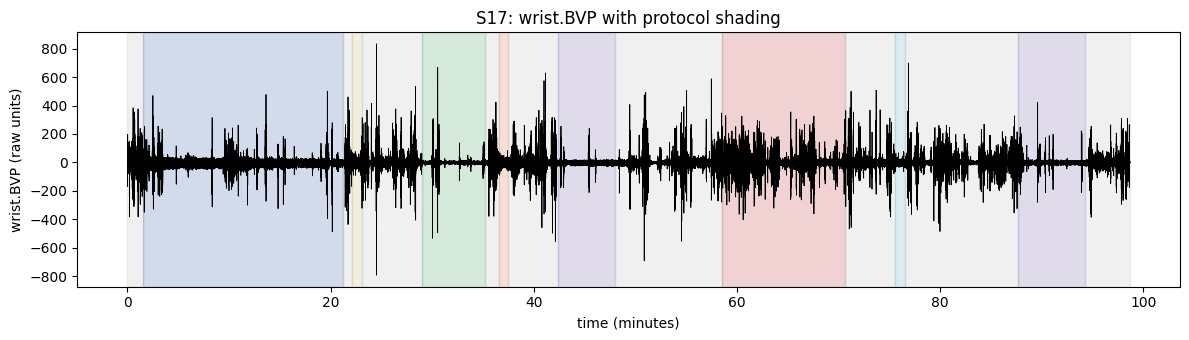

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="wrist", channel="BVP")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

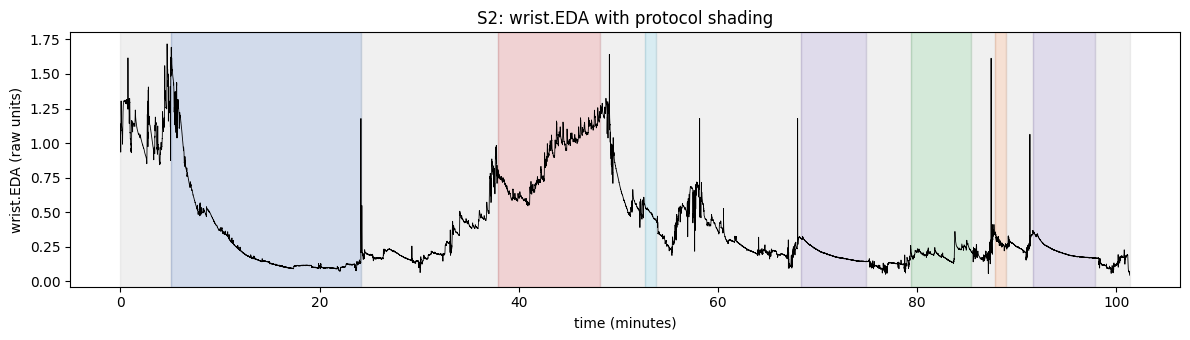

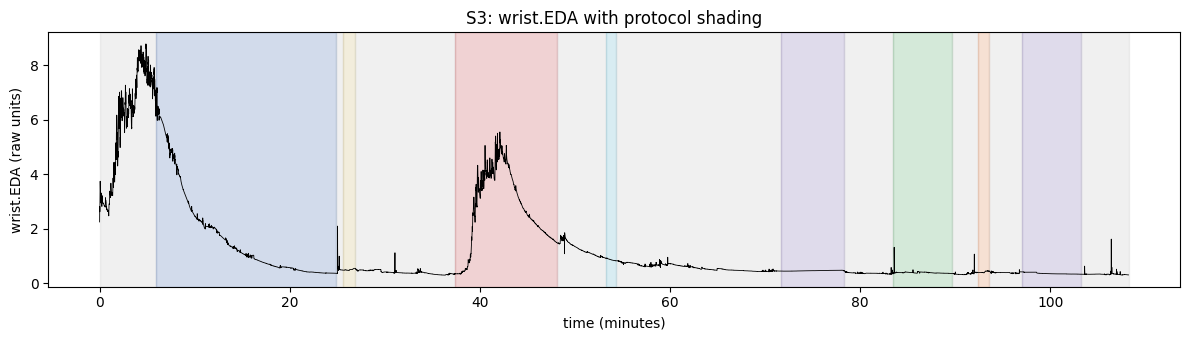

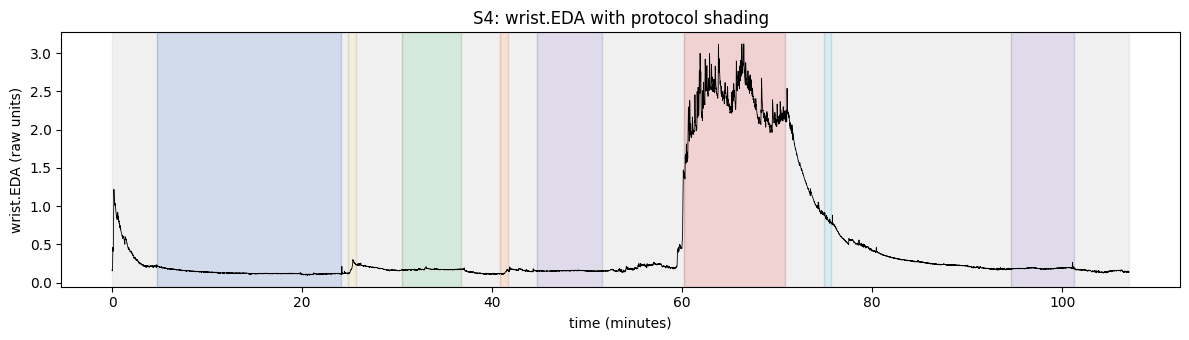

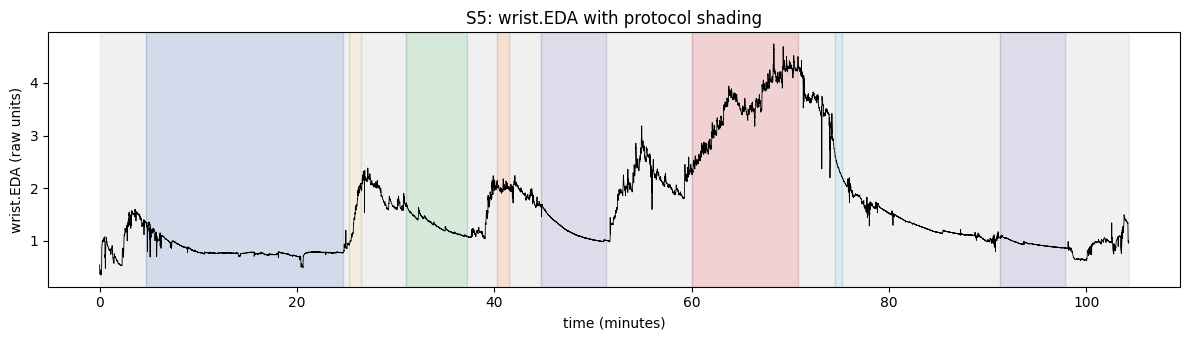

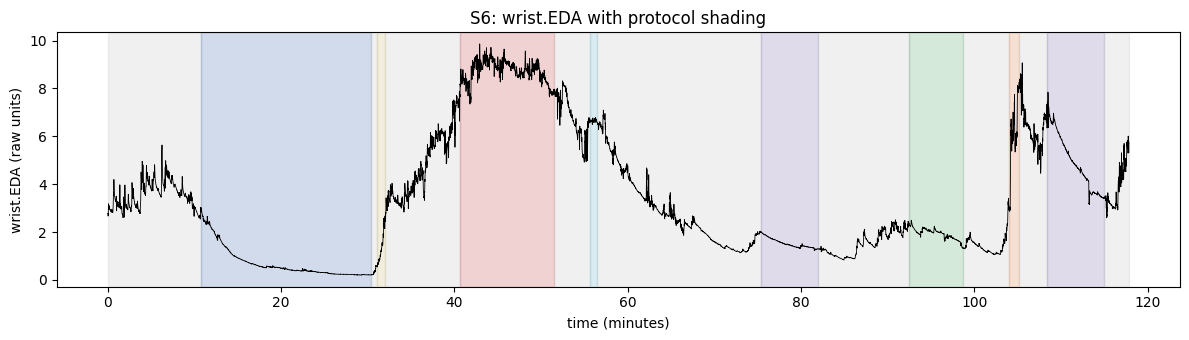

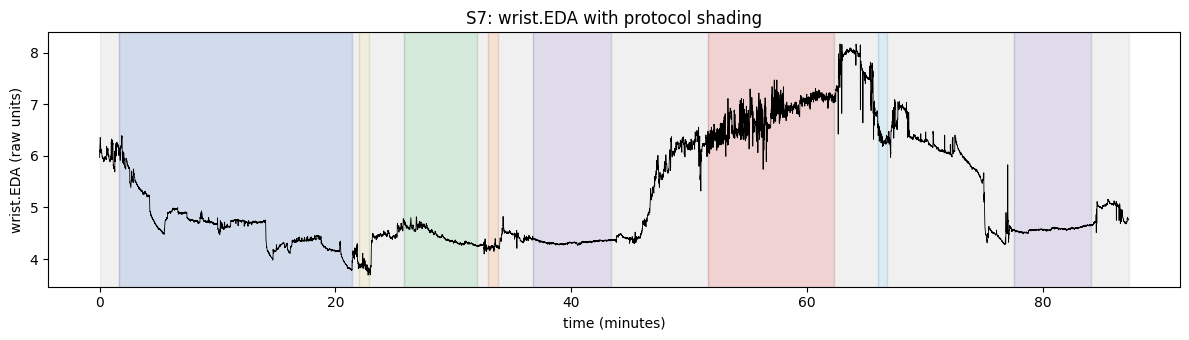

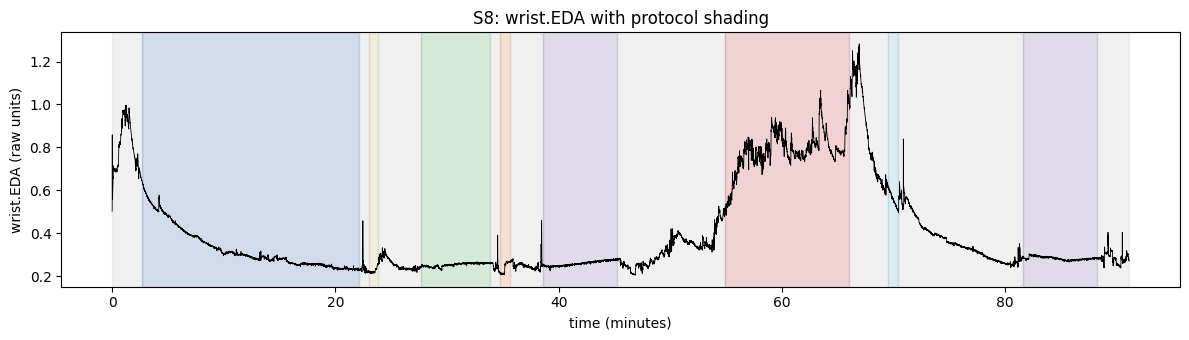

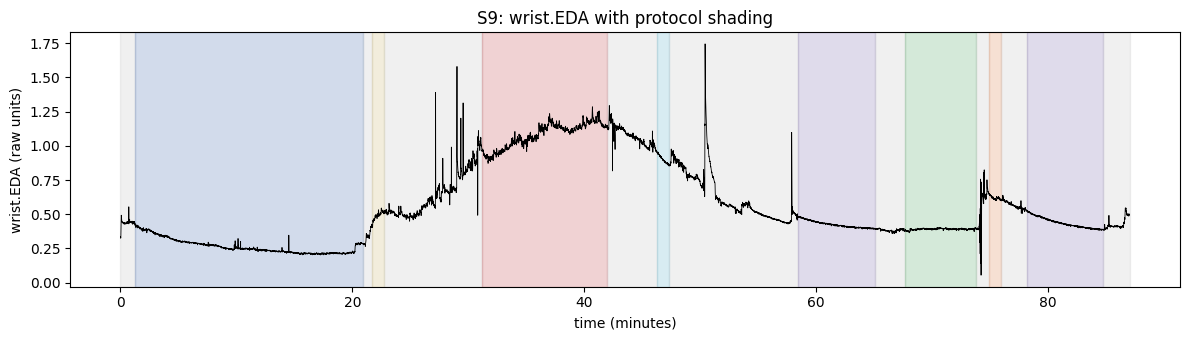

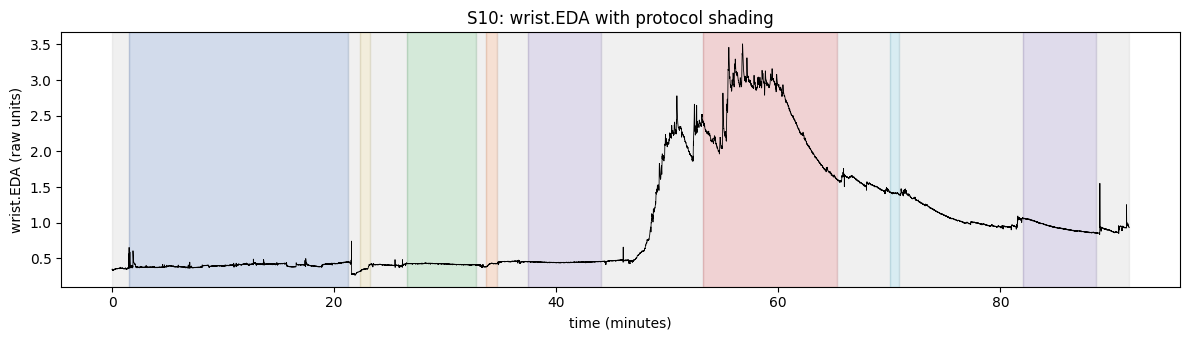

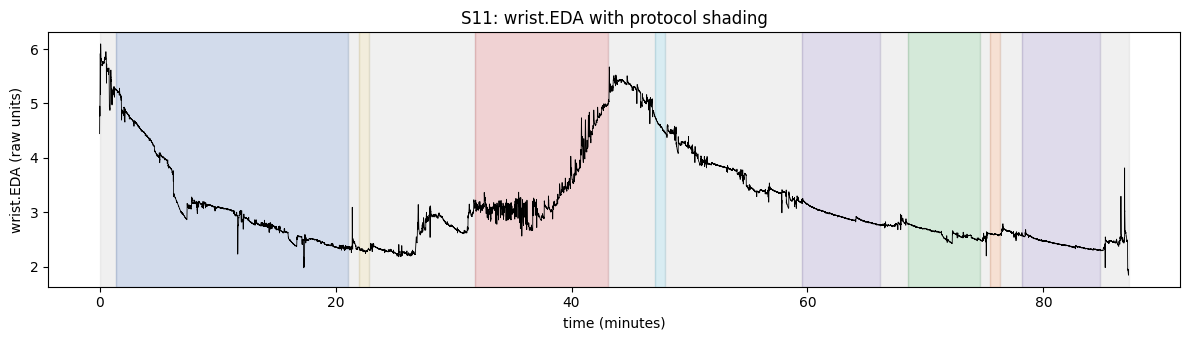

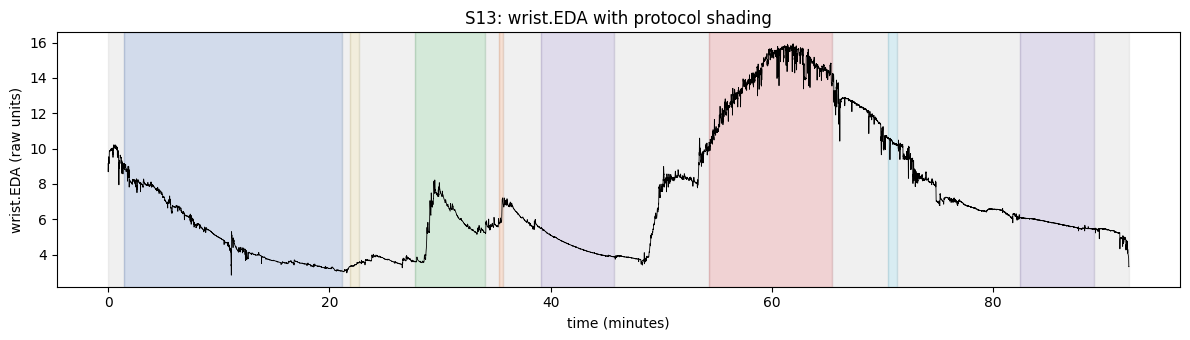

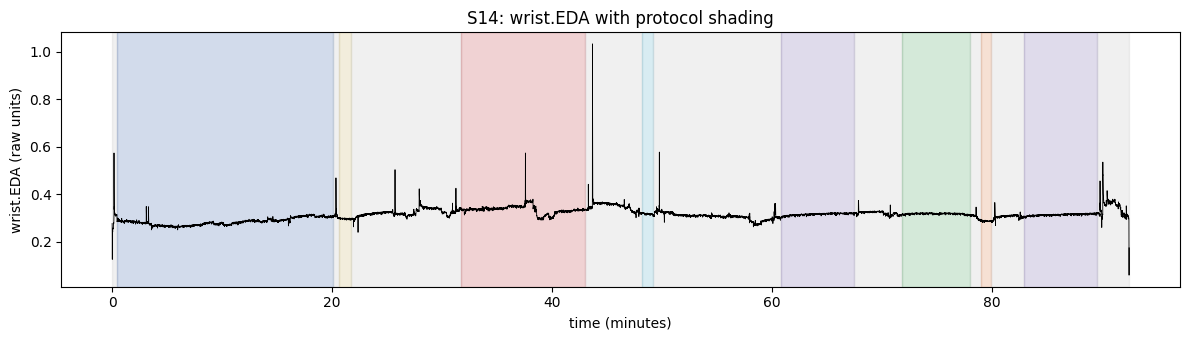

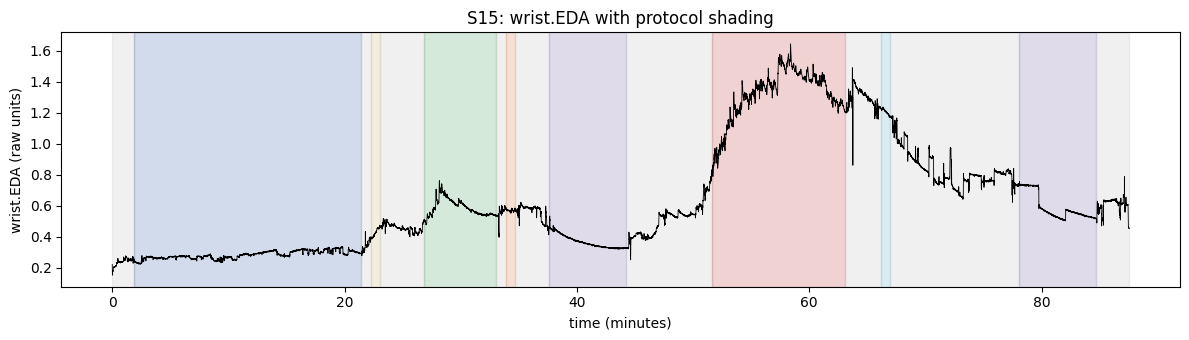

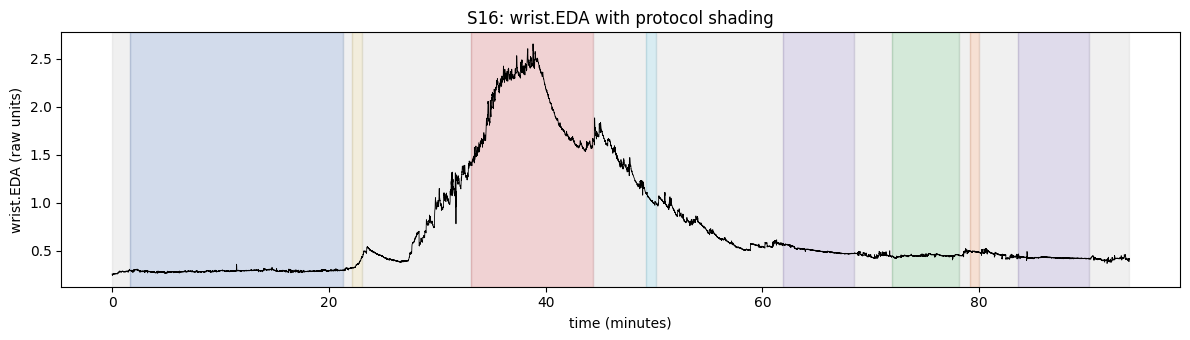

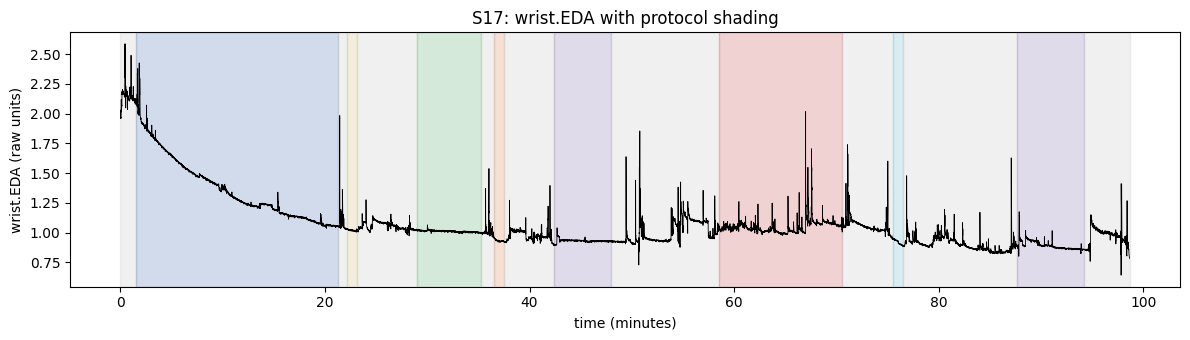

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="wrist", channel="EDA")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

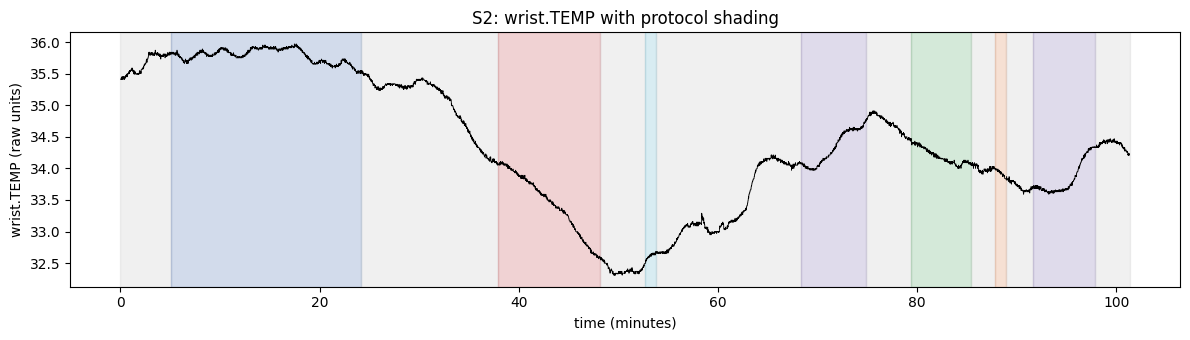

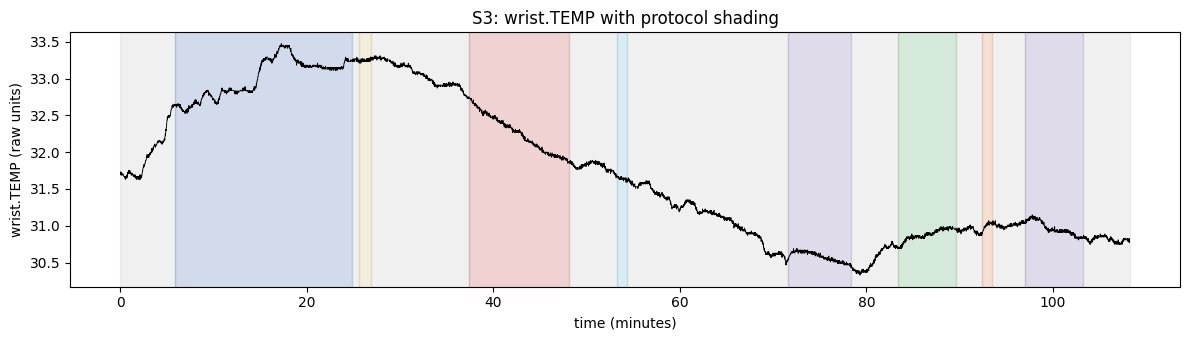

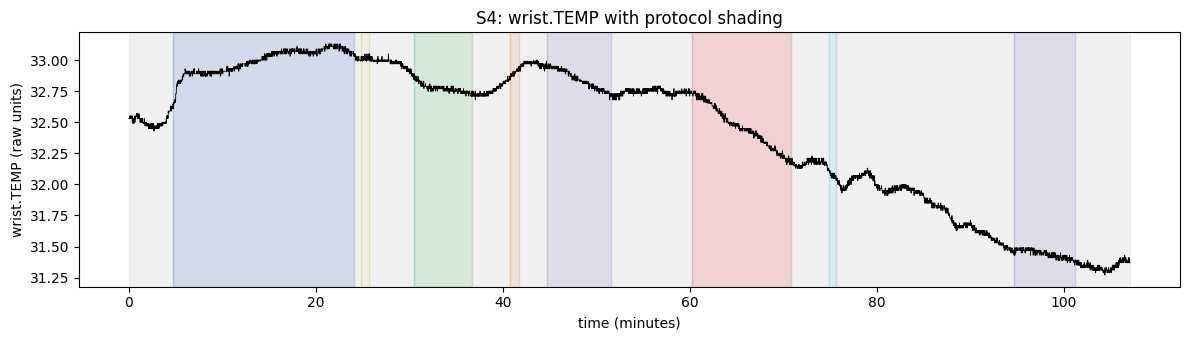

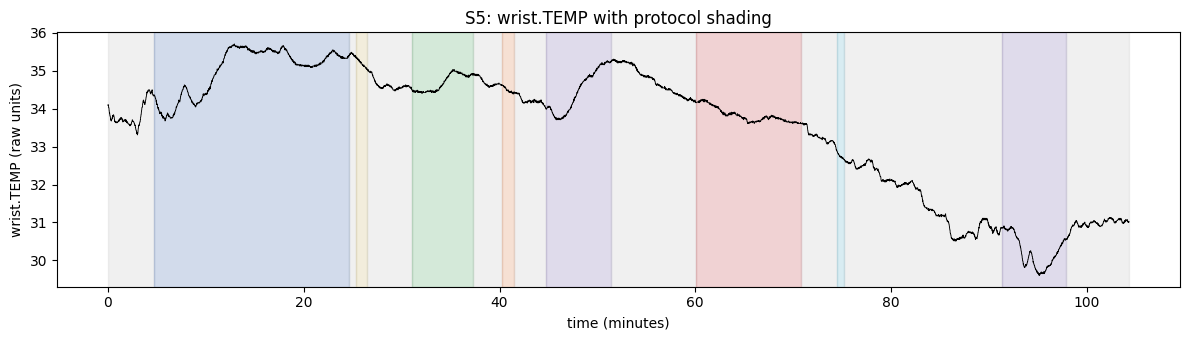

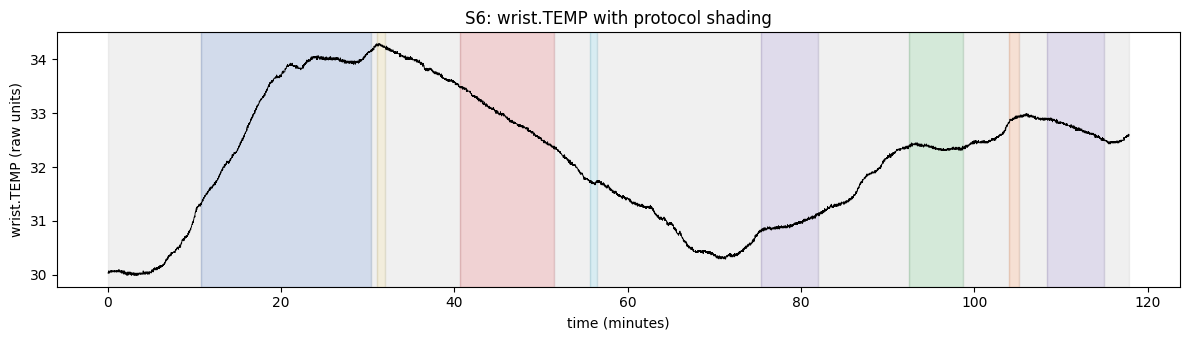

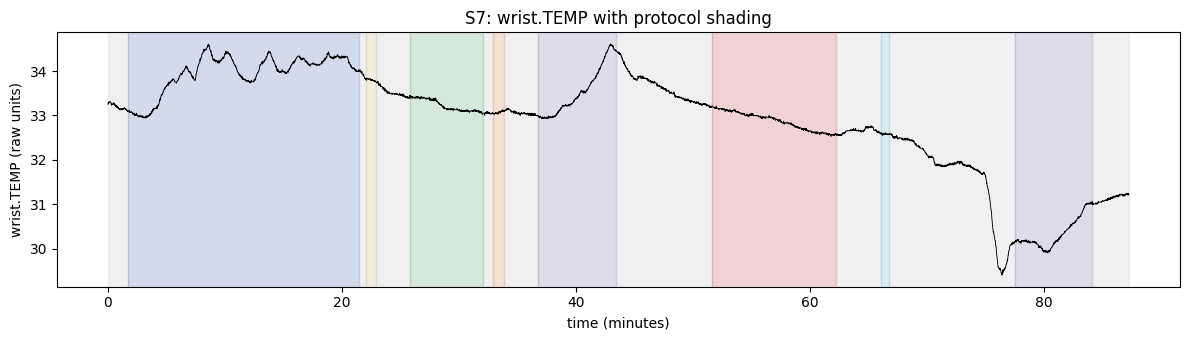

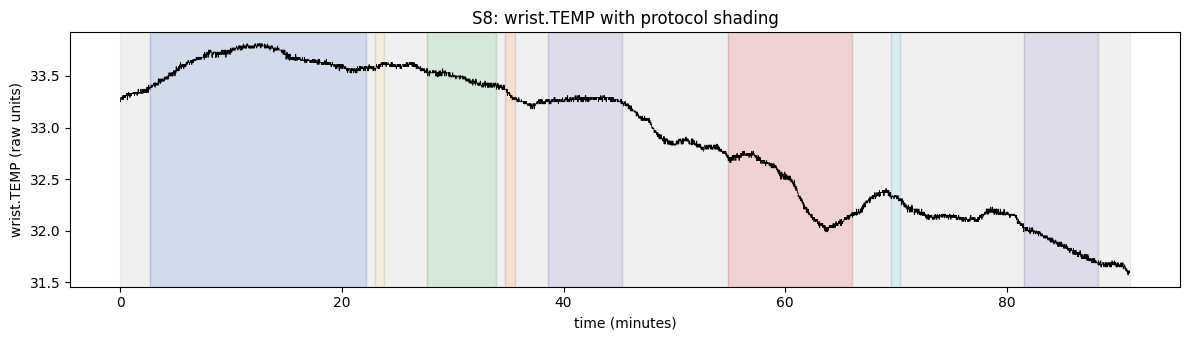

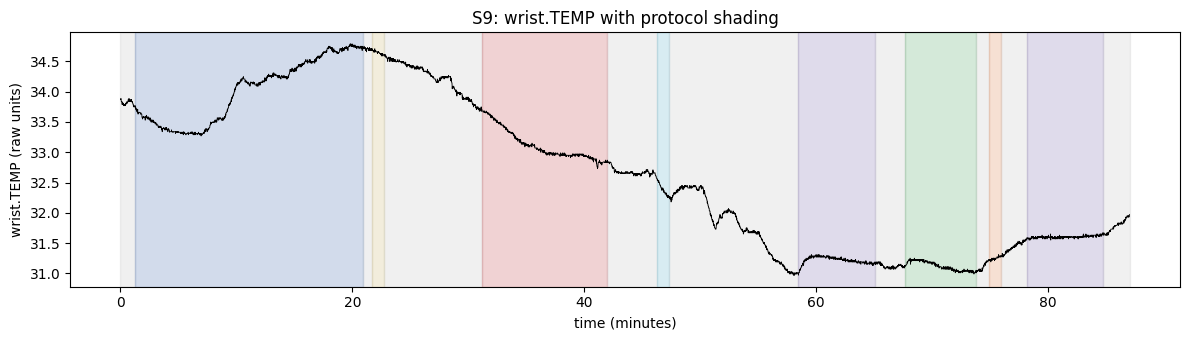

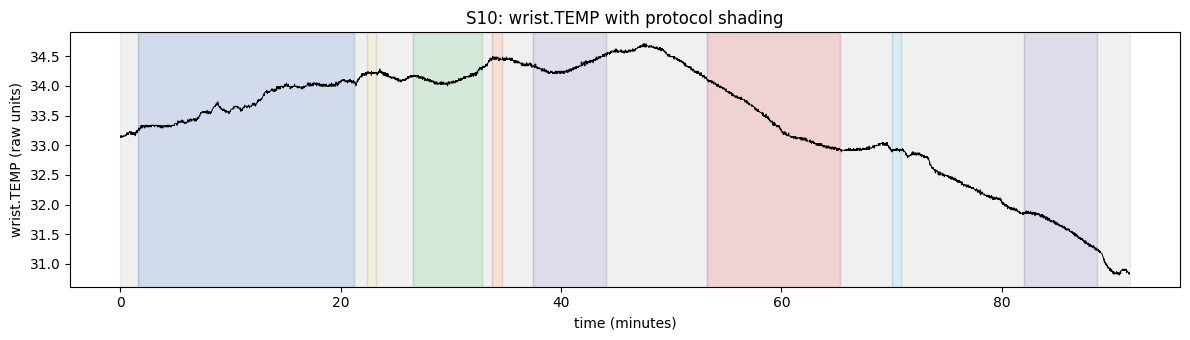

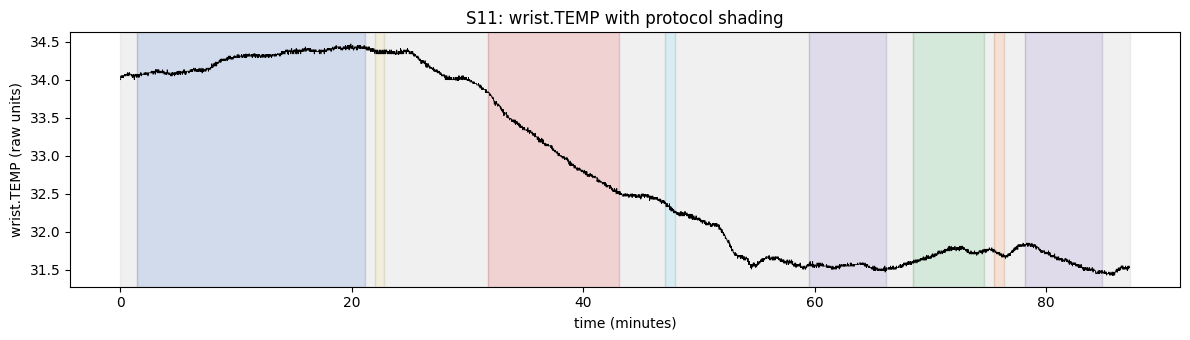

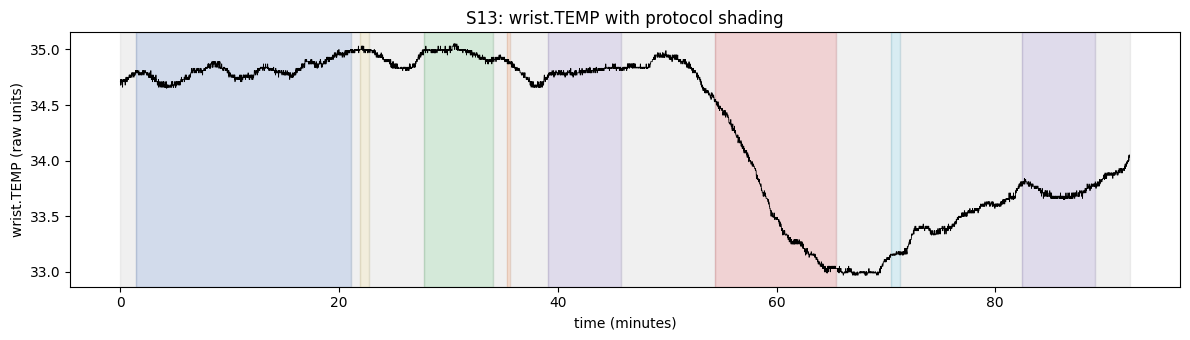

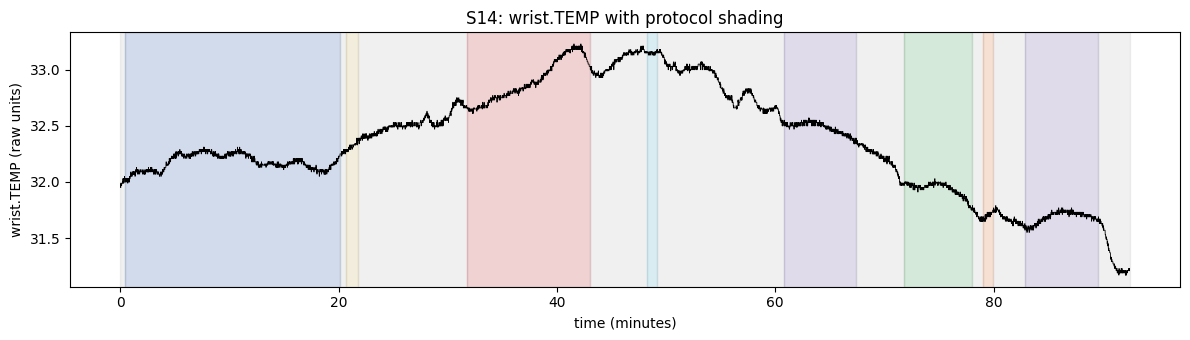

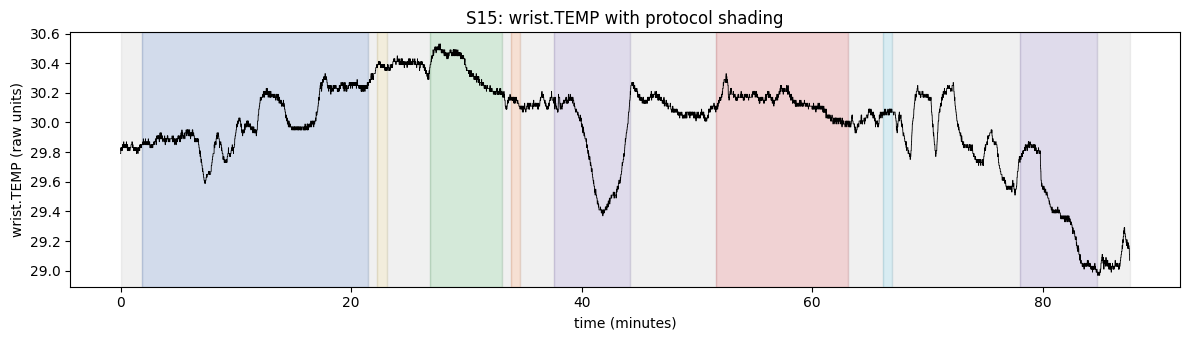

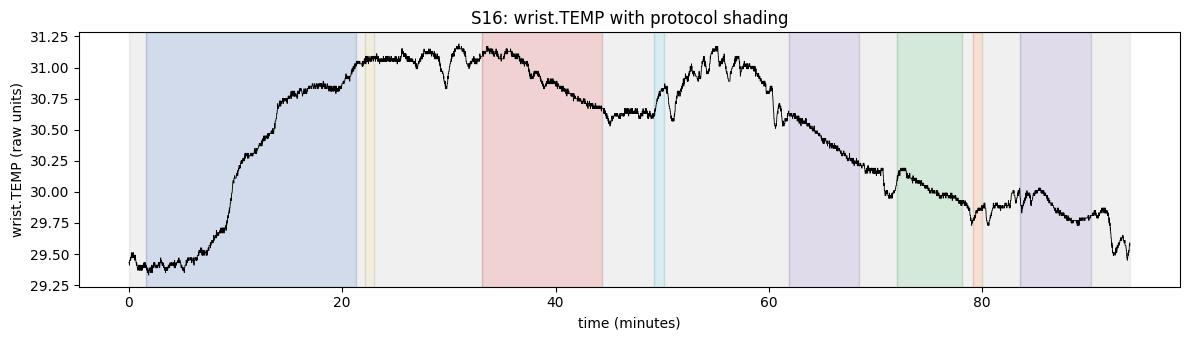

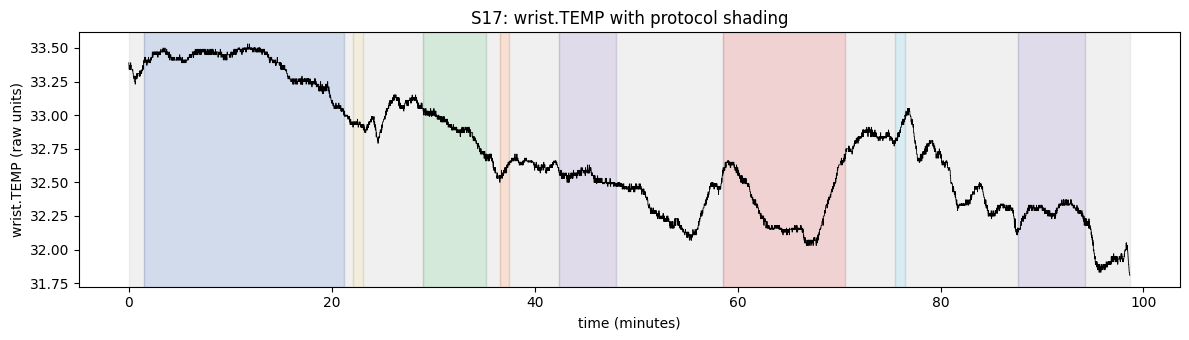

In [ ]:
for sid, subject_data in wesad_full.items():
    fig = plot_channel_with_label_shading(subject_data, device="wrist", channel="TEMP")

    # Display the plot in the cell output
    plt.show()

    # CRITICAL: Close the figure to free up RAM!
    plt.close(fig)

In [ ]:
# Verify if the chest signals are raw ADC counts or pre-converted physical units
sample_chest = wesad_full['S2']['chest']

for channel in ['ECG', 'EDA', 'Temp', 'ACC']:
    data = sample_chest[channel]
    print(f"Chest Channel: {channel}")
    print(f"  Shape: {data.shape}")
    print(f"  Min:   {data.min():.4f}")
    print(f"  Max:   {data.max():.4f}")
    print(f"  Mean:  {data.mean():.4f}")
    print("-" * 30)

Chest Channel: ECG
  Shape: (4255300, 1)
  Min:   -1.4995
  Max:   1.4993
  Mean:  0.0012
------------------------------
Chest Channel: EDA
  Shape: (4255300, 1)
  Min:   0.2632
  Max:   7.5768
  Mean:  1.5284
------------------------------
Chest Channel: Temp
  Shape: (4255300, 1)
  Min:   28.0453
  Max:   34.3704
  Mean:  30.8767
------------------------------
Chest Channel: ACC
  Shape: (4255300, 3)
  Min:   -1.1354
  Max:   2.0298
  Mean:  0.0660
------------------------------


# **Preprocessing pipeline**

This pipeline cleans, structures, and normalizes the multimodal physiological signals before they are windowed and fed into our deep learning encoders. The following steps are performed sequentially:

1. **Missing Data & Dropout Checks (`has_missing_samples`):** Checks the entire session dataset for NaNs or corrupted samples prior to downstream processing.
2. **Initial Stabilization Trimming (`trim_initial_data`):** Drops the first 5 minutes ($300$ seconds) of all chest/wrist signals and label alignments. This removes the initial setup periods and transient skin hydration artifacts (e.g., the high starting EDA artifact).
3. **ECG Baseline Wander Removal (`apply_ecg_highpass`):** Applies a 4th-order zero-phase highpass Butterworth filter ($f_c = 0.5$ Hz) to the chest ECG channel to eliminate slow baseline drifts caused by breathing and physical movement.
4. **Session-Wide Threshold Computing (`compute_session_thresholds`):** Dynamically calculates baseline levels for clipping detection (minimum/maximum limits for Respiration) and establishes a motion-artifact threshold (95th percentile of the wrist $L_2$ accelerometer magnitude).
5. **Contiguous State Run Segmentation (`find_label_runs`):** Scans the aligned 700 Hz labels to locate contiguous segments of interest (Baseline, Stress, Meditation and Amusement) while ignoring transitions.
6. **Overlapping Window Generation (`generate_windows_for_subject`):** Slides a 60-second window with a 15-second step across contiguous target runs.
7. **Data-Driven Artifact Filtering (`has_clipping` & `has_excessive_motion`):** Drops individual windows if their chest respiration is clipped/flatlined or if their average wrist motion magnitude exceeds the session-wide threshold.
8. **Within-Subject Baseline Normalization (`_slice_and_normalize`):** Z-scores each valid window segment using only the mean and standard deviation computed from that subject's stabilized *Baseline* (label 1) period.

In [ ]:
import numpy as np, pandas as pd
from collections import defaultdict
from scipy.signal import cheby2, filtfilt, find_peaks

def bandpass_bvp(bvp, fs=64, lo=0.5, hi=5.0):
    """Chebyshev II order-4 band-pass (as in Campanella et al.), zero-phase."""
    b, a = cheby2(4, 20, [lo, hi], btype="bandpass", fs=fs)
    return filtfilt(b, a, np.asarray(bvp, dtype=np.float64).reshape(-1))

def bvp_ibi_quality(bvp_filt_win, fs, rel_tol=0.35, abs_lo=0.3, abs_hi=2.0, min_dist_s=0.3):
    """Relative IBI consistency. An interval is bad if it deviates from the window's
    own median IBI by > rel_tol, or is physiologically impossible (<0.3s / >2s).
    A steady 125 bpm rhythm passes; missed or spurious peaks fail."""
    x = np.asarray(bvp_filt_win, dtype=np.float64).reshape(-1)
    peaks, _ = find_peaks(x, distance=max(1, int(min_dist_s * fs)), prominence=0.5 * np.std(x))
    if len(peaks) < 5:
        return {"n_beats": int(len(peaks)), "bad_ibi_frac": 1.0}
    ibi = np.diff(peaks) / fs
    med = np.median(ibi)
    bad = (np.abs(ibi - med) > rel_tol * med) | (ibi < abs_lo) | (ibi > abs_hi)
    return {"n_beats": int(len(peaks)), "bad_ibi_frac": float(bad.mean())}

def annotate_raw_quality(windows, subject_data, window_sec=60):
    """Motion + IBI quality from RAW wrist signals (not the z-scored window arrays).
    Needs w['t_start_sec'] (added to generate_windows_for_subject below).
    Wrist ACC is in 1/64 g; scale is irrelevant for the per-subject percentile."""
    bvp_f = bandpass_bvp(subject_data["wrist"]["BVP"], WRIST_FS["BVP"])  # whole recording once: no per-window edge effects
    acc = np.asarray(subject_data["wrist"]["ACC"], dtype=np.float64)
    for w in windows:
        t0 = w["t_start_sec"]
        a0 = int(round(t0 * WRIST_FS["ACC"])); a1 = a0 + int(window_sec * WRIST_FS["ACC"])
        b0 = int(round(t0 * WRIST_FS["BVP"])); b1 = b0 + int(window_sec * WRIST_FS["BVP"])
        w["motion_raw"] = float(np.std(np.linalg.norm(acc[a0:a1] / 64.0, axis=1)))
        w.update(bvp_ibi_quality(bvp_f[b0:b1], WRIST_FS["BVP"]))
    return windows

def apply_gate(windows, clip=True, motion=False, ibi=False, motion_pct=90, max_bad_ibi=0.15):
    """Returns (kept_windows, per-window report DataFrame). Gating is a separate,
    explicit step, so every ablation condition runs off the same cached windows."""
    by_s = defaultdict(list)
    for w in windows:
        by_s[w["subject"]].append(w["motion_raw"])
    thr = {s: float(np.percentile(v, motion_pct)) for s, v in by_s.items()}
    rows, kept = [], []
    for w in windows:
        r_clip = bool(w["clip_flag"])
        r_mot = bool(w["motion_raw"] > thr[w["subject"]])
        r_ibi = bool(w["bad_ibi_frac"] > max_bad_ibi)
        ok = not ((clip and r_clip) or (motion and r_mot) or (ibi and r_ibi))
        rows.append({"subject": w["subject"], "label": w.get("model_label", w["label"]),
                     "clip": r_clip, "motion": r_mot, "ibi": r_ibi, "kept": ok})
        if ok:
            kept.append(w)
    return kept, pd.DataFrame(rows)

In [ ]:
from collections import defaultdict

import numpy as np
from scipy.signal import butter, filtfilt

def check_missing_samples(subject_data):
    """Report NaN counts per channel rather than a single yes/no -- one dropped
    sample in one channel is a very different situation from a large gap."""
    report = {}
    for location in ["chest", "wrist"]:
        for sensor, arr in subject_data[location].items():
            n_nan = int(np.isnan(arr).sum())
            if n_nan > 0:
                report[f"{location}.{sensor}"] = n_nan
    return report


def apply_ecg_highpass(subject_data, cutoff_hz=0.5, order=4):
    """Remove ECG baseline wander (movement/loose-contact drift) with a zero-phase
    Butterworth high-pass. 0.5Hz is the standard cutoff for this; note it sits
    close to typical breathing-rate frequencies (~0.15-0.4Hz) that also modulate
    R-peak *amplitude* (a real physiological effect, distinct from baseline wander)
    -- if that amplitude-modulation signal matters to your features, sanity-check
    with a lower cutoff (e.g. 0.3Hz) rather than assuming 0.5Hz is harmless here."""
    b, a = butter(order, cutoff_hz / (CHEST_FS / 2), btype="high")
    ecg = subject_data["chest"]["ECG"]
    filtered = filtfilt(b, a, ecg, axis=0)

    new_subject_data = dict(subject_data)
    new_subject_data["chest"] = dict(subject_data["chest"])
    new_subject_data["chest"]["ECG"] = filtered.astype(np.float64)
    return new_subject_data

In [ ]:
def compute_channel_extrema(subject_data):
    """Per-subject, per-channel (min, max) over the full raw recording -- clipping
    means 'pinned at this channel's own physical limit for this session', not an
    absolute constant, so the reference has to come from the subject's own data."""
    extrema = {"chest": {}, "wrist": {}}
    for ch in CHEST_CHANNELS:
        arr = subject_data["chest"][ch]
        extrema["chest"][ch] = (arr.min(axis=0), arr.max(axis=0))
    for ch in WRIST_CHANNELS:
        arr = subject_data["wrist"][ch]
        extrema["wrist"][ch] = (arr.min(axis=0), arr.max(axis=0))
    return extrema


def normalize_extrema(extrema, baseline_stats):
    """Transform raw-unit (min, max) into the same z-scored space the windows are
    actually stored in (generate_windows_for_subject normalizes before returning).
    Comparing clip thresholds against normalized window values requires this --
    comparing raw-unit extrema against z-scored data can never match (confirmed:
    it silently produced zero clip detections against an injected clip run, since
    raw Resp extrema were ~[-23, 29] while window values were already z-scored to
    ~[-0.4, 0.9])."""
    out = {"chest": {}, "wrist": {}}
    for location in ("chest", "wrist"):
        for ch, (gmin, gmax) in extrema[location].items():
            mean, std = baseline_stats[location][ch]
            out[location][ch] = ((gmin - mean) / std, (gmax - mean) / std)
    return out

In [ ]:
def _has_clip_run(arr, glob_min, glob_max, min_run=15, atol=1e-3):
    """True if arr contains a run of >= min_run consecutive samples pinned at this
    channel's (z-scored) global min or max, within a small tolerance. A tolerance
    (rather than exact equality) is necessary here because windows pass through a
    float64->float32 cast during normalization -- exact equality against a
    separately-computed z-scored threshold isn't guaranteed to survive that
    rounding, even though the underlying raw values are exactly equal."""
    arr = np.atleast_2d(arr.T).T
    for col in range(arr.shape[1]):
        x = arr[:, col]
        gmin = glob_min[col] if np.ndim(glob_min) else glob_min
        gmax = glob_max[col] if np.ndim(glob_max) else glob_max
        pinned = np.isclose(x, gmin, atol=atol) | np.isclose(x, gmax, atol=atol)
        if not pinned.any():
            continue
        kernel = np.ones(min_run)
        if np.max(np.convolve(pinned.astype(int), kernel, mode="valid")) >= min_run:
            return True
    return False


def compute_motion_energy(acc_window):
    """Std of the ACC vector magnitude -- high means the sensor is moving,
    regardless of orientation (unlike raw axis values, which depend on how the
    wrist happens to be rotated)."""
    mag = np.linalg.norm(acc_window, axis=1)
    return float(np.std(mag))

In [ ]:
def annotate_windows_with_quality(windows, normalized_extrema, clip_channels=("chest.Resp", "chest.ECG", "chest.EDA", "chest.Temp", "wrist.EDA", "wrist.TEMP"), min_run=15):
    """Add clip_flag / motion_energy to each window (from
    wesad_dataset.generate_windows_for_subject, called with keep_labels=None so
    windows still carry the raw WESAD label -- map to model classes separately
    with wesad_dataset.map_labels() once you've decided on a scheme). Flags, does
    not drop -- see flag_high_motion_windows for the drop decision. Pass extrema
    already transformed by normalize_extrema() -- window arrays are z-scored, not
    raw, so raw-unit extrema will never match (see normalize_extrema's docstring)."""
    for w in windows:
        clip_flag = False
        for spec in clip_channels:
            location, ch = spec.split(".")
            gmin, gmax = normalized_extrema[location][ch]
            if _has_clip_run(w[location][ch], gmin, gmax, min_run=min_run):
                clip_flag = True
                break
        w["clip_flag"] = clip_flag
        w["motion_energy"] = compute_motion_energy(w["wrist"]["ACC"])
    return windows


def flag_high_motion_windows(windows, percentile=90):
    """Per-subject percentile threshold on motion_energy (subjects differ in
    baseline fidgetiness/sensor fit, so a global constant threshold isn't
    comparable across them). Mutates windows with 'motion_flag', returns the
    per-subject thresholds used for reporting."""
    by_subject = defaultdict(list)
    for w in windows:
        by_subject[w["subject"]].append(w["motion_energy"])
    thresholds = {s: float(np.percentile(v, percentile)) for s, v in by_subject.items()}
    for w in windows:
        w["motion_flag"] = w["motion_energy"] > thresholds[w["subject"]]
    return windows, thresholds

In [ ]:
def build_dataset_with_quality(root_dir, subject_ids=None, window_sec=60, step_sec=15,
                                baseline_trim_start_sec=300, ecg_highpass=True,
                                nan_report_only=True):
    """load -> NaN report -> ECG high-pass -> baseline stats -> window -> annotate
    clip_flag (z-scored, as before) + raw-signal motion_raw / n_beats / bad_ibi_frac.
    Flags only; nothing is dropped here (see apply_gate)."""
    root_dir = Path(root_dir)
    subject_ids = subject_ids or ALL_SUBJECTS
    all_windows, report = [], {}

    for sid in subject_ids:
        pkl_path = root_dir / sid / f"{sid}.pkl"
        if not pkl_path.exists():
            print(f"  [skip] {pkl_path} not found")
            continue

        subject_data = load_subject_pkl(pkl_path)
        nan_report = check_missing_samples(subject_data)
        if nan_report and not nan_report_only:
            print(f"  [skip] {sid}: NaNs found {nan_report}")
            continue
        if ecg_highpass:
            subject_data = apply_ecg_highpass(subject_data)

        baseline_stats = compute_baseline_stats(subject_data, trim_start_sec=baseline_trim_start_sec)
        extrema = normalize_extrema(compute_channel_extrema(subject_data), baseline_stats)

        windows = generate_windows_for_subject(
            subject_data, baseline_stats, window_sec=window_sec, step_sec=step_sec, keep_labels=(1, 2, 3, 4)
        )
        windows = annotate_windows_with_quality(windows, extrema)
        windows = annotate_raw_quality(windows, subject_data, window_sec=window_sec)

        report[sid] = {
            "n_windows": len(windows),
            "n_clip_flagged": sum(w["clip_flag"] for w in windows),
            "mean_bad_ibi_frac": float(np.mean([w["bad_ibi_frac"] for w in windows])),
            "nan_counts": nan_report,
        }
        all_windows.extend(windows)
        print(f"  {sid}: {len(windows)} windows | clip {report[sid]['n_clip_flagged']} "
              f"| mean bad_ibi_frac {report[sid]['mean_bad_ibi_frac']:.2f}"
              + (f" | NaNs: {nan_report}" if nan_report else ""))

    print(f"Total: {len(all_windows)} windows across {len(report)} subjects")
    return all_windows, report

In [ ]:
wesad_clean, wesad_report = build_dataset_with_quality("/content/wesad_data/WESAD", subject_ids=ALL_SUBJECTS)

  S2: 177 windows | clip-flagged 0 | motion-flagged 18
  S3: 179 windows | clip-flagged 4 | motion-flagged 18
  S4: 181 windows | clip-flagged 0 | motion-flagged 18
  S5: 183 windows | clip-flagged 0 | motion-flagged 19
  S6: 182 windows | clip-flagged 0 | motion-flagged 19
  S7: 182 windows | clip-flagged 0 | motion-flagged 19
  S8: 182 windows | clip-flagged 0 | motion-flagged 19
  S9: 182 windows | clip-flagged 0 | motion-flagged 19
  S10: 187 windows | clip-flagged 0 | motion-flagged 19
  S11: 184 windows | clip-flagged 0 | motion-flagged 19
  S13: 184 windows | clip-flagged 0 | motion-flagged 19
  S14: 184 windows | clip-flagged 0 | motion-flagged 19
  S15: 184 windows | clip-flagged 0 | motion-flagged 19
  S16: 183 windows | clip-flagged 0 | motion-flagged 19
  S17: 183 windows | clip-flagged 0 | motion-flagged 19
Total: 2737 windows across 15 subjects


In [ ]:
def map_labels(windows, label_map, drop_unmapped=True):
    """Apply a raw-label -> model-class mapping once you've decided what to keep,
    e.g. map_labels(windows, {1: 0, 2: 1, 3: 2}) for baseline/stress/amusement only.
    Returns a new list; each kept example gets an added 'model_label' field."""
    out = []
    for ex in windows:
        if ex["label"] in label_map:
            new_ex = dict(ex)
            new_ex["model_label"] = label_map[ex["label"]]
            out.append(new_ex)
        elif not drop_unmapped:
            out.append(ex)
    return out

In [ ]:
mapped = map_labels(wesad_clean, {1: 0, 2: 1, 3: 2, 4: 3})  # baseline, stress, amusement, meditation
final_windows = [w for w in mapped if not w["clip_flag"]]

print(f"{len(wesad_clean)} -> {len(mapped)} after label mapping -> {len(final_windows)} after dropping clip-flagged")

2737 -> 2737 after label mapping -> 2733 after dropping clip-flagged


#**Cache the dataset**

In [ ]:
def load_or_build_final_dataset(cache_path, root_dir, label_map, subject_ids=None,
                                 window_sec=60, step_sec=15, force_rebuild=False, **build_kwargs):
    """Caches ALL label-mapped windows WITH quality flags. Nothing is dropped here;
    use apply_gate() so every gate condition runs off the same cache."""
    cache_path = Path(cache_path)
    if cache_path.exists() and not force_rebuild:
        print(f"Loading cached dataset from {cache_path} ...")
        with open(cache_path, "rb") as f:
            cached = pickle.load(f)
        if (cached["label_map"] != label_map
                or cached["window_sec"] != window_sec or cached["step_sec"] != step_sec):
            raise ValueError(f"Cache at {cache_path} was built with different parameters/QC version. "
                             f"Use force_rebuild=True or a new cache_path.")
        print(f"Loaded {len(cached['windows'])} windows.")
        return cached["windows"], cached["report"]

    print("Building dataset ...")
    windows, report = build_dataset_with_quality(
        root_dir, subject_ids=subject_ids, window_sec=window_sec, step_sec=step_sec, **build_kwargs)
    mapped = map_labels(windows, label_map)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    with open(cache_path, "wb") as f:
        pickle.dump({"windows": mapped, "report": report, "label_map": label_map,
                     "window_sec": window_sec, "step_sec": step_sec},
                    f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"{len(windows)} raw -> {len(mapped)} mapped, saved to {cache_path}")
    return mapped, report

In [ ]:
final_windows, report = load_or_build_final_dataset(
    cache_path="/content/drive/MyDrive/licenta/WESAD/wesad_cache/final_windows.pkl",
    root_dir="/content/wesad_data/WESAD",
    label_map={1: 0, 2: 1, 3: 2, 4: 3},
    subject_ids=ALL_SUBJECTS,
)

Loading cached dataset from /content/drive/MyDrive/licenta/WESAD/wesad_cache/final_windows.pkl ...
Loaded 2733 windows.


In [ ]:
# Regression check: clip-only gate must reproduce your OLD final_windows count exactly.
final_windows_qc, _ = apply_gate(final_windows, clip=True)
print(len(final_windows_qc))

2733


#**Creating the training + validation sets**

In [ ]:
import random
from collections import Counter

def subject_level_split(windows, val_subjects=None, val_frac=0.2, seed=42):
    """Split by whole subject, not by window. If val_subjects is given, use exactly
    those as validation (e.g. val_subjects=['S3', 'S3'] if you want a specific,
    reproducible held-out set -- useful once you've picked subjects deliberately
    rather than randomly). Otherwise randomly select round(val_frac * n_subjects)
    subjects, seeded for reproducibility. Returns (train_windows, val_windows,
    val_subjects_used)."""
    all_subjects = sorted({w["subject"] for w in windows})

    if val_subjects is None:
        n_val = max(1, round(val_frac * len(all_subjects)))
        rng = random.Random(seed)
        val_subjects = sorted(rng.sample(all_subjects, n_val))
    else:
        missing = set(val_subjects) - set(all_subjects)
        if missing:
            raise ValueError(f"val_subjects not present in windows: {missing}")

    val_set = set(val_subjects)
    train_windows = [w for w in windows if w["subject"] not in val_set]
    val_windows = [w for w in windows if w["subject"] in val_set]
    return train_windows, val_windows, val_subjects

In [ ]:
def loso_folds(windows):
    """Generator of (train_windows, val_windows, held_out_subject) -- one fold per
    subject. Use this for the final reported evaluation once the architecture is
    settled; NOT for day-to-day iteration, since it means N full training runs."""
    all_subjects = sorted({w["subject"] for w in windows})
    for held_out in all_subjects:
        train_windows = [w for w in windows if w["subject"] != held_out]
        val_windows = [w for w in windows if w["subject"] == held_out]
        yield train_windows, val_windows, held_out

In [ ]:
def label_distribution(windows, label_field="model_label"):
    """Counter of label -> window count. Check this on both sides of any split --
    a subject-level split can accidentally produce a validation set skewed toward
    one class if, e.g., the held-out subject's session had unusually long/short
    stress or amusement segments."""
    return Counter(w[label_field] for w in windows)

In [ ]:
train_windows, val_windows, val_subjects = subject_level_split(final_windows, val_frac=0.2, seed=42)
print("held out:", val_subjects)
print("train:", label_distribution(train_windows))
print("val:  ", label_distribution(val_windows))

held out: ['S10', 'S11', 'S5']
train: Counter({0: 895, 3: 547, 1: 483, 2: 254})
val:   Counter({0: 226, 3: 138, 1: 127, 2: 63})


In [ ]:
class WESADWindowDataset:
    """Thin torch.utils.data.Dataset wrapper around a pre-built window list.
    label_field defaults to 'model_label' (the mapped 0..K-1 class from
    map_labels()), NOT 'label' (the raw WESAD id 1/2/3/4) -- training against
    'label' would silently use the wrong target values.

    Leave device=None and move the BATCH to the GPU inside your training loop
    instead. Setting device here only works safely with num_workers=0 in the
    DataLoader: each worker is a separate process, and moving tensors to CUDA
    inside a forked worker process is unsupported."""

    def __init__(self, windows, label_field="model_label", device=None):
        self.windows = windows
        self.label_field = label_field
        self.device = device

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        import torch  # local import: only required when actually training

        ex = self.windows[idx]
        chest = {ch: torch.from_numpy(ex["chest"][ch]) for ch in CHEST_CHANNELS}
        wrist = {ch: torch.from_numpy(ex["wrist"][ch]) for ch in WRIST_CHANNELS}
        label = torch.tensor(ex[self.label_field], dtype=torch.long)
        if self.device is not None:
            chest = {ch: t.to(self.device) for ch, t in chest.items()}
            wrist = {ch: t.to(self.device) for ch, t in wrist.items()}
            label = label.to(self.device)
        return {"chest": chest, "wrist": wrist, "label": label, "subject": ex["subject"]}

In [ ]:
import torch

train_ds = WESADWindowDataset(train_windows)
loader = torch.utils.data.DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=0)

batch = next(iter(loader))
print(batch["label"].shape, batch["label"].dtype)         # expect: torch.Size([8]) torch.int64
print(batch["chest"]["ECG"].shape)                          # expect: torch.Size([8, 42000, 1])
print(batch["wrist"]["EDA"].shape)                          # expect: torch.Size([8, 240, 1])
print(batch["subject"])                                     # expect: list of 8 subject-id strings

torch.Size([8]) torch.int64
torch.Size([8, 42000, 1])
torch.Size([8, 240, 1])
['S3', 'S3', 'S14', 'S14', 'S15', 'S9', 'S16', 'S4']


#**Training the classical baseline models**

##**Building the full and the wrist-only datasets**

In [ ]:
import numpy as np
from scipy.signal import find_peaks
from scipy.stats import iqr


def _flatten(x):
    """Drop a trailing size-1 channel dim (e.g. (N,1) -> (N,)); leave multi-channel
    arrays (e.g. ACC's (N,3)) untouched -- callers that need per-axis handling
    (acc_features) work on the raw array directly and never call this."""
    x = np.asarray(x)
    return x.reshape(-1) if x.ndim > 1 and x.shape[1] == 1 else x


def basic_stats(x, prefix, fs=None):
    """Generic per-channel summary stats. `fs` is optional: pass it to also get a
    linear trend (units/sec) over the window -- useful for EDA/TEMP drift, not
    meaningful for something like EMG."""
    x = _flatten(x).astype(np.float64)
    feats = {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_range": np.ptp(x),
        f"{prefix}_iqr": iqr(x),
    }
    if fs is not None and len(x) > 1:
        t = np.arange(len(x)) / fs
        feats[f"{prefix}_slope"] = np.polyfit(t, x, 1)[0]
    return feats

In [ ]:
def acc_features(acc, prefix, fs):
    """Vector-magnitude stats (orientation-invariant motion level) plus per-axis
    std, from a raw (N, 3) accelerometer window."""
    acc = np.asarray(acc, dtype=np.float64)
    mag = np.linalg.norm(acc, axis=1)
    feats = basic_stats(mag, f"{prefix}_mag", fs=fs)
    feats[f"{prefix}_energy"] = float(np.mean(mag ** 2))
    for i, axis in enumerate(["x", "y", "z"]):
        feats[f"{prefix}_{axis}_std"] = float(np.std(acc[:, i]))
    return feats

In [ ]:
def eda_features(eda, prefix, fs):
    """Level/trend stats plus a crude SCR (skin conductance response) peak count:
    local maxima with a minimum prominence, at most one per second."""
    eda = _flatten(eda).astype(np.float64)
    feats = basic_stats(eda, prefix, fs=fs)
    if len(eda) > 3:
        peaks, props = find_peaks(eda, prominence=0.02, distance=max(1, int(fs)))
        feats[f"{prefix}_n_scr"] = len(peaks)
        feats[f"{prefix}_scr_mean_prom"] = float(np.mean(props["prominences"])) if len(peaks) else 0.0
    else:
        feats[f"{prefix}_n_scr"] = 0
        feats[f"{prefix}_scr_mean_prom"] = 0.0
    return feats

In [ ]:
def hr_features_from_peaks(sig, prefix, fs, min_hr=40, max_hr=180):
    """Peak-based HRV from a pulsatile signal (ECG or BVP): mean/std HR, SDNN,
    RMSSD, pNN50, from inter-peak intervals. Returns NaNs (not zeros) when fewer
    than 3 peaks are found, so a downstream imputer can fill from the column
    median rather than a model reading 'zero variability' as a real signal."""
    sig = _flatten(sig).astype(np.float64)
    min_dist = max(1, int(fs * 60 / max_hr))
    peaks, _ = find_peaks(sig, distance=min_dist, prominence=np.std(sig) * 0.5)
    if len(peaks) < 3:
        return {
            f"{prefix}_hr_mean": np.nan, f"{prefix}_hr_std": np.nan,
            f"{prefix}_sdnn": np.nan, f"{prefix}_rmssd": np.nan,
            f"{prefix}_pnn50": np.nan, f"{prefix}_n_peaks": float(len(peaks)),
        }
    rr = np.diff(peaks) / fs
    hr = 60.0 / rr
    valid = (hr >= min_hr) & (hr <= max_hr)
    rr_v, hr_v = (rr[valid], hr[valid]) if valid.sum() >= 2 else (rr, hr)
    diffs = np.diff(rr_v) * 1000
    pnn50 = float(np.mean(np.abs(diffs) > 50)) if len(diffs) else np.nan
    return {
        f"{prefix}_hr_mean": float(np.mean(hr_v)),
        f"{prefix}_hr_std": float(np.std(hr_v)),
        f"{prefix}_sdnn": float(np.std(rr_v) * 1000),
        f"{prefix}_rmssd": float(np.sqrt(np.mean(diffs ** 2))) if len(diffs) else np.nan,
        f"{prefix}_pnn50": pnn50,
        f"{prefix}_n_peaks": float(len(peaks)),
    }

In [ ]:
def resp_features(resp, prefix, fs):
    """Chest-only: level/trend stats plus estimated breathing rate (breaths/min)
    from peak spacing."""
    resp = _flatten(resp).astype(np.float64)
    feats = basic_stats(resp, prefix, fs=fs)
    peaks, _ = find_peaks(resp, distance=int(fs * 1.5), prominence=np.std(resp) * 0.3)
    duration_min = len(resp) / fs / 60
    feats[f"{prefix}_breath_rate"] = len(peaks) / duration_min if duration_min > 0 else np.nan
    return feats

In [ ]:
def emg_features(emg, prefix):
    """Chest-only: muscle activation level (mean abs, std, RMS)."""
    emg = _flatten(emg).astype(np.float64)
    return {
        f"{prefix}_mean_abs": float(np.mean(np.abs(emg))),
        f"{prefix}_std": float(np.std(emg)),
        f"{prefix}_rms": float(np.sqrt(np.mean(emg ** 2))),
    }


In [ ]:
def extract_wrist_features(window):
    w = window["wrist"]
    feats = {}
    feats.update(acc_features(w["ACC"], "wrist_acc", WRIST_FS["ACC"]))
    feats.update(hr_features_from_peaks(w["BVP"], "wrist_bvp", WRIST_FS["BVP"]))
    feats.update(eda_features(w["EDA"], "wrist_eda", WRIST_FS["EDA"]))
    feats.update(basic_stats(w["TEMP"], "wrist_temp", fs=WRIST_FS["TEMP"]))
    return feats

In [ ]:
def extract_chest_features(window):
    c = window["chest"]
    feats = {}
    feats.update(acc_features(c["ACC"], "chest_acc", CHEST_FS))
    feats.update(hr_features_from_peaks(c["ECG"], "chest_ecg", CHEST_FS))
    feats.update(eda_features(c["EDA"], "chest_eda", CHEST_FS))
    feats.update(basic_stats(c["Temp"], "chest_temp", fs=CHEST_FS))
    feats.update(resp_features(c["Resp"], "chest_resp", CHEST_FS))
    feats.update(emg_features(c["EMG"], "chest_emg"))
    return feats

In [ ]:
def extract_features(window, mode="full"):
    """mode='wrist' -> wrist channels only (deployable feature set).
    mode='full'  -> wrist + chest channels (oracle / upper-bound feature set)."""
    feats = extract_wrist_features(window)
    if mode == "full":
        feats.update(extract_chest_features(window))
    feats["subject"] = window["subject"]
    feats["label"] = window["model_label"]
    return feats


def build_feature_df(windows, mode="full"):
    import pandas as pd
    rows = [extract_features(w, mode=mode) for w in windows]
    return pd.DataFrame(rows)

In [ ]:
df_full = build_feature_df(final_windows, mode="full")
df_wrist = build_feature_df(final_windows, mode="wrist")

FEATURE_COLS_FULL = [c for c in df_full.columns if c not in ("subject", "label")]
FEATURE_COLS_WRIST = [c for c in df_wrist.columns if c not in ("subject", "label")]

print(f"full:  {df_full.shape[0]} windows x {len(FEATURE_COLS_FULL)} features")
print(f"wrist: {df_wrist.shape[0]} windows x {len(FEATURE_COLS_WRIST)} features")

nan_counts = df_full[FEATURE_COLS_FULL].isna().sum()
nan_counts = nan_counts[nan_counts > 0]
print("\nColumns with NaNs (from failed peak detection on some windows -- the\n"
      "imputer in the model pipeline below handles these, this is just visibility):")
print(nan_counts if len(nan_counts) else "  none")

full:  2733 windows x 77 features
wrist: 2733 windows x 33 features

Columns with NaNs (from failed peak detection on some windows -- the
imputer in the model pipeline below handles these, this is just visibility):
  none


##**Building and training the models**
 - **Random Forest** -- a solid default: robust to
   unscaled/heterogeneous features, handles nonlinear interactions, hard to overfit catastrophically even at N=8 subjects if depth/leaf-size are kept sane.
 - **Histogram Gradient Boosting** (`sklearn`'s built-in, no extra dependency) -- usually a bit stronger than RF on tabular data of this size, and fast enough
   that LOSO CV below costs nothing.
 - **Logistic Regression** (regularized, scaled features) -- a linear reference
   point. If it does almost as well as the tree ensembles, that's informative: it would suggest the classes separate roughly linearly in this feature space,
   which is itself worth reporting alongside the RF/GBM numbers.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight

CLASS_NAMES = ["baseline", "stress", "amusement", "meditation"]  # model_label 0,1,2,3


def get_models():
    """Fresh, unfit pipelines -- call this every time you're about to fit, so
    results from one split/fold never leak model state into the next."""
    return {
        "random_forest": Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("clf", RandomForestClassifier(
                n_estimators=300, max_depth=8, min_samples_leaf=5,
                random_state=42, n_jobs=-1,
            )),
        ]),
        "hist_gb": Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("clf", HistGradientBoostingClassifier(
                max_depth=4, max_iter=200, learning_rate=0.05, random_state=42,
            )),
        ]),
        "logreg": Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, random_state=42)),
        ]),
    }

In [ ]:
def fit_with_sample_weight(pipeline, X, y):
    sw = compute_sample_weight("balanced", y)
    pipeline.fit(X, y, clf__sample_weight=sw)
    return pipeline


def evaluate(pipeline, X, y):
    preds = pipeline.predict(X)
    return {
        "balanced_accuracy": balanced_accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro"),
        "per_class_f1": f1_score(y, preds, average=None, labels=[0, 1, 2, 3]),
        "confusion_matrix": confusion_matrix(y, preds, labels=[0, 1, 2, 3]),
        "y_true": y, "y_pred": preds,
    }

In [ ]:
train_subj = {w["subject"] for w in train_windows}
val_subj = {w["subject"] for w in val_windows}

def split_df(df, feature_cols):
    tr = df["subject"].isin(train_subj)
    va = df["subject"].isin(val_subj)
    return df.loc[tr, feature_cols], df.loc[tr, "label"], df.loc[va, feature_cols], df.loc[va, "label"]

In [ ]:
def loso_cv(df, feature_cols, model_name):
    subjects = sorted(df["subject"].unique())
    fold_metrics = []
    for held_out in subjects:
        train_mask = df["subject"] != held_out
        val_mask = df["subject"] == held_out
        Xtr, ytr = df.loc[train_mask, feature_cols], df.loc[train_mask, "label"]
        Xva, yva = df.loc[val_mask, feature_cols], df.loc[val_mask, "label"]
        pipeline = fit_with_sample_weight(get_models()[model_name], Xtr, ytr)
        m = evaluate(pipeline, Xva, yva)
        m["held_out_subject"] = held_out
        fold_metrics.append(m)
    return fold_metrics

#**Deep learning models: 1D-CNN and TCN**

Two architectures, each with one small per-modality encoder tower fused by
concatenation into a shared head:

- **1D-CNN** -- plain `Conv1d` stack, 16 -> 32 -> 64 channels.
- **TCN** -- dilated causal residual blocks (Bai et al., 2018), same 16 -> 32 -> 64
  channel progression, so the CNN and TCN bodies are an apples-to-apples
  architectural comparison.

Chest ECG is 42,000 timesteps at 700Hz; wrist EDA is 240 timesteps at 4Hz. Instead
of hand-tuning a conv stack per modality/rate, every encoder starts with a strided
**"patchify" stem**: one cheap non-overlapping-patch `Conv1d` (kernel=stride=`input_len // 64`)
followed by an `AdaptiveAvgPool1d(64)` to snap the result to exactly 64 timesteps.
Everything downstream -- the CNN/TCN body, the GAP, the head -- then operates on the
same `(B, 16, 64)` shape regardless of whether the modality started at 700Hz or 4Hz.
This is what makes full-sensor and wrist-only genuinely the same architecture (`MultiModalNet`
below is instantiated with a different list of modality names, nothing else changes) rather
than two architectures that happen to solve the same task.

Per encoder tower: GAP instead of a big dense layer, dropout, and `weight_decay` (via
`AdamW`) from the start -- not bolted on after the fact. Loss is class-weighted
`CrossEntropyLoss` (inverse frequency), and every epoch records both train and val
macro-F1 so the train/val gap -- the overfitting curve -- is visible directly, not just
the final number.

**On the split:** the deep models below train on the single subject-level split
(`train_windows` / `val_windows`, from `subject_level_split` above), **not LOSO**.
`loso_folds`'s own docstring already flags LOSO as "not for day-to-day iteration"
since it means N full training runs -- for four neural nets each trained over
several dozen epochs, that cost is real, so the same call applies here. Concretely,
this means the LOSO summary table above (15 held-out subjects, averaged) and the
deep-model numbers below (1 held-out subject) are **not evaluated the same way** --
the single-split numbers carry much higher variance. The fair comparison is against
`quick_results` (the classical models' own single-split numbers, computed earlier),
not against `loso_results`. The comparison table at the end of this section uses
`quick_results`, not `loso_results`, for exactly this reason.

In [ ]:
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

try:
    from torch.nn.utils.parametrizations import weight_norm
except ImportError:  # older torch
    from torch.nn.utils import weight_norm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  {torch.cuda.get_device_name(0)}")
else:
    print("  No GPU visible -- in Colab, go to Runtime > Change runtime type > GPU.")

torch.manual_seed(42)

Using device: cuda
  Tesla T4


In [ ]:
WINDOW_SEC = 60  # matches window_sec used when final_windows was built (see load_or_build_final_dataset call)

# name -> (location, channel key into batch["chest"/"wrist"], sample rate, n_signal_channels)
MODALITY_SPECS = {
    "chest_acc":  ("chest", "ACC",  CHEST_FS,         3),
    "chest_ecg":  ("chest", "ECG",  CHEST_FS,         1),
    "chest_eda":  ("chest", "EDA",  CHEST_FS,         1),
    "chest_emg":  ("chest", "EMG",  CHEST_FS,         1),
    "chest_resp": ("chest", "Resp", CHEST_FS,         1),
    "chest_temp": ("chest", "Temp", CHEST_FS,         1),
    "wrist_acc":  ("wrist", "ACC",  WRIST_FS["ACC"],  3),
    "wrist_bvp":  ("wrist", "BVP",  WRIST_FS["BVP"],  1),
    "wrist_eda":  ("wrist", "EDA",  WRIST_FS["EDA"],  1),
    "wrist_temp": ("wrist", "TEMP", WRIST_FS["TEMP"], 1),
}


def modality_input_len(name):
    _, _, fs, _ = MODALITY_SPECS[name]
    return int(WINDOW_SEC * fs)


FULL_MODALITIES = list(MODALITY_SPECS.keys())
WRIST_MODALITIES = [m for m in MODALITY_SPECS if m.startswith("wrist_")]

print("full modalities  (n=%d):" % len(FULL_MODALITIES), FULL_MODALITIES)
print("wrist modalities (n=%d):" % len(WRIST_MODALITIES), WRIST_MODALITIES)
print()
for m in FULL_MODALITIES:
    in_len = modality_input_len(m)
    patch = max(1, in_len // 64)
    print(f"  {m:12s} input_len={in_len:5d}  in_channels={MODALITY_SPECS[m][3]}  "
          f"patchify: kernel=stride={patch:3d} -> ~{in_len // patch} timesteps -> pooled to 64")


full modalities  (n=10): ['chest_acc', 'chest_ecg', 'chest_eda', 'chest_emg', 'chest_resp', 'chest_temp', 'wrist_acc', 'wrist_bvp', 'wrist_eda', 'wrist_temp']
wrist modalities (n=4): ['wrist_acc', 'wrist_bvp', 'wrist_eda', 'wrist_temp']

  chest_acc    input_len=42000  in_channels=3  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  chest_ecg    input_len=42000  in_channels=1  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  chest_eda    input_len=42000  in_channels=1  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  chest_emg    input_len=42000  in_channels=1  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  chest_resp   input_len=42000  in_channels=1  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  chest_temp   input_len=42000  in_channels=1  patchify: kernel=stride=656 -> ~64 timesteps -> pooled to 64
  wrist_acc    input_len= 1920  in_channels=3  patchify: kernel=stride= 30 -> ~64 timesteps -> pooled to 64
  wris

In [ ]:
class Chomp1d(nn.Module):
    """Cut the extra right-padding a dilated conv adds, so output length matches
    input length exactly (standard causal-TCN trick)."""

    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size] if self.chomp_size > 0 else x


class PatchifyStem(nn.Module):
    """Downsample an arbitrary-length (B, T_in, C_in) signal to exactly
    (B, 16, target_len) in one cheap strided conv. This is what makes a
    42000-sample chest ECG window and a 240-sample wrist EDA window
    architecturally symmetric: everything downstream sees the same shape."""

    def __init__(self, in_channels, input_len, target_len=64, out_channels=16):
        super().__init__()
        patch = max(1, input_len // target_len)
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size=patch, stride=patch)
        self.bn = nn.BatchNorm1d(out_channels)
        self.resize = nn.AdaptiveAvgPool1d(target_len)

    def forward(self, x):
        x = x.transpose(1, 2)  # (B, T_in, C_in) -> (B, C_in, T_in)
        x = F.relu(self.bn(self.conv(x)))
        return self.resize(x)  # (B, 16, target_len)


class CNNBody(nn.Module):
    """16 -> 32 -> 64 plain conv stack operating on the common ~64-timestep scale."""

    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=3, padding=1), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class TemporalBlock(nn.Module):
    """Dilated-causal TCN residual block (Bai et al., 2018)."""

    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1, dropout=0.2):
        super().__init__()
        pad = (kernel_size - 1) * dilation
        self.conv1 = weight_norm(nn.Conv1d(in_channels, out_channels, kernel_size, padding=pad, dilation=dilation))
        self.chomp1 = Chomp1d(pad)
        self.conv2 = weight_norm(nn.Conv1d(out_channels, out_channels, kernel_size, padding=pad, dilation=dilation))
        self.chomp2 = Chomp1d(pad)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.downsample = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else None
        self._init_weights()

    def _init_weights(self):
        self.conv1.weight.data.normal_(0, 0.01)
        self.conv2.weight.data.normal_(0, 0.01)
        if self.downsample is not None:
            self.downsample.weight.data.normal_(0, 0.01)

    def forward(self, x):
        out = self.dropout(self.relu(self.chomp1(self.conv1(x))))
        out = self.dropout(self.relu(self.chomp2(self.conv2(out))))
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class TCNBody(nn.Module):
    """16 -> 32 -> 64 with increasing dilation (1, 2) -- same channel progression
    as CNNBody, so the CNN vs TCN comparison isolates the conv type, not the width."""

    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            TemporalBlock(16, 32, kernel_size=3, dilation=1, dropout=dropout),
            TemporalBlock(32, 64, kernel_size=3, dilation=2, dropout=dropout),
        )

    def forward(self, x):
        return self.net(x)


class ModalityEncoder(nn.Module):
    """One tiny tower per channel: patchify stem -> CNN or TCN body -> GAP.
    Every modality comes out as a single 64-dim vector, regardless of its
    native length or sample rate."""

    def __init__(self, in_channels, input_len, body="cnn", target_len=64, dropout=0.2):
        super().__init__()
        self.stem = PatchifyStem(in_channels, input_len, target_len=target_len)
        self.body = CNNBody(dropout=dropout) if body == "cnn" else TCNBody(dropout=dropout)

    def forward(self, x):
        x = self.stem(x)
        x = self.body(x)
        return F.adaptive_avg_pool1d(x, 1).squeeze(-1)  # GAP: (B, 64, 64) -> (B, 64)


class MultiModalNet(nn.Module):
    """One ModalityEncoder per modality, GAP-pooled outputs concatenated into a
    small head. Each modality also has a learnable 'missing' token (same dim as
    its embedding) substituted in when that modality isn't available -- either
    structurally (absent from batch entirely) or via modality_mask (per-sample,
    used for training-time dropout)."""

    def __init__(self, modalities, body="cnn", num_classes=4, head_hidden=64, dropout=0.3):
        super().__init__()
        self.modalities = modalities
        self.encoders = nn.ModuleDict({
            name: ModalityEncoder(MODALITY_SPECS[name][3], modality_input_len(name), body=body, dropout=dropout)
            for name in modalities
        })
        self.missing_tokens = nn.ParameterDict({
            name: nn.Parameter(torch.zeros(64)) for name in modalities
        })
        for p in self.missing_tokens.values():
            nn.init.normal_(p, mean=0.0, std=0.02)

        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(64 * len(modalities), head_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, num_classes),
        )

    def forward(self, batch, modality_mask=None):
        """
        modality_mask: optional dict {modality_name: BoolTensor(B,)}, True = present.
        A modality absent from `batch` entirely (no key for it) always uses its
        missing token for the whole batch, regardless of modality_mask.
        modality_mask is only for modalities that ARE in `batch` but should be
        hidden for some samples (the training-time dropout case).
        """
        ref = None
        for name in self.modalities:
            location, ch, _, _ = MODALITY_SPECS[name]
            if location in batch and ch in batch[location]:
                ref = batch[location][ch]
                break
        if ref is None:
            raise ValueError("no modality data found in batch")
        B, device = ref.shape[0], ref.device

        feats = []
        for name in self.modalities:
            location, ch, _, _ = MODALITY_SPECS[name]
            token = self.missing_tokens[name]
            if location in batch and ch in batch[location]:
                emb = self.encoders[name](batch[location][ch])
                if modality_mask is not None and name in modality_mask:
                    present = modality_mask[name].to(device).view(-1, 1).float()
                    emb = present * emb + (1 - present) * token.unsqueeze(0)
            else:
                emb = token.unsqueeze(0).expand(B, -1)
            feats.append(emb)
        x = torch.cat(feats, dim=1)
        return self.head(x)


# sanity check: param counts, and that a forward pass runs on both variants
for body in ("cnn", "tcn"):
    m_full = MultiModalNet(FULL_MODALITIES, body=body)
    m_wrist = MultiModalNet(WRIST_MODALITIES, body=body)
    n_full = sum(p.numel() for p in m_full.parameters())
    n_wrist = sum(p.numel() for p in m_wrist.parameters())
    print(f"{body:4s} | full:  {n_full:7,d} params  | wrist: {n_wrist:7,d} params")


cnn  | full:  208,548 params  | wrist:  51,524 params
tcn  | full:  389,668 params  | wrist: 123,972 params


In [ ]:
def sample_modality_mask(modalities, batch_size, drop_prob, device):
    """Per-sample, per-modality boolean mask (True = present). drop_prob is either
    one float (applied to every modality) or a dict {modality_name: prob} for
    per-modality rates -- e.g. ACC/TEMP more plausibly absent on the eventual
    device than BVP/EDA. Guarantees at least one modality survives per sample."""
    if isinstance(drop_prob, dict):
        probs = torch.tensor([drop_prob.get(m, 0.0) for m in modalities], device=device)
    else:
        probs = torch.full((len(modalities),), float(drop_prob), device=device)

    present = torch.rand(batch_size, len(modalities), device=device) >= probs.unsqueeze(0)
    none_present = ~present.any(dim=1)
    if none_present.any():
        forced_idx = torch.randint(0, len(modalities), (int(none_present.sum()),), device=device)
        rows = none_present.nonzero(as_tuple=True)[0]
        present[rows, forced_idx] = True
    return {name: present[:, i] for i, name in enumerate(modalities)}

In [ ]:
def class_weights_from_windows(windows, label_field="model_label", num_classes=4):
    """Inverse-frequency class weights (normalized to mean 1) for CrossEntropyLoss,
    computed from the training split only."""
    counts = np.zeros(num_classes)
    for w in windows:
        counts[w[label_field]] += 1
    inv = 1.0 / np.maximum(counts, 1)
    weights = inv * (num_classes / inv.sum())
    return torch.tensor(weights, dtype=torch.float32)


def move_batch(batch, device):
    chest = {ch: t.to(device) for ch, t in batch["chest"].items()}
    wrist = {ch: t.to(device) for ch, t in batch["wrist"].items()}
    label = batch["label"].to(device)
    return {"chest": chest, "wrist": wrist}, label


def run_epoch(model, loader, criterion, device, optimizer=None,
              modality_dropout_p=0.0, fixed_modality_mask=None):
    """modality_dropout_p: random per-sample masking, applied only when training.
    fixed_modality_mask: {modality_name: False}, forces that modality 'absent'
    for every sample in every batch this pass -- for eval, to test a specific
    subset (e.g. simulate no ACC/TEMP) against a held-out fold. The two are
    mutually exclusive in practice: dropout during training, fixed mask during
    eval."""
    is_train = optimizer is not None
    model.train(is_train)
    all_true, all_pred = [], []
    total_loss, n = 0.0, 0
    with torch.set_grad_enabled(is_train):
        for batch in loader:
            inputs, labels = move_batch(batch, device)
            if is_train and modality_dropout_p:
                mask = sample_modality_mask(model.modalities, labels.size(0), modality_dropout_p, device)
            elif fixed_modality_mask is not None:
                mask = {name: torch.full((labels.size(0),), present, dtype=torch.bool, device=device)
                        for name, present in fixed_modality_mask.items()}
            else:
                mask = None
            logits = model(inputs, modality_mask=mask)
            loss = criterion(logits, labels)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            n += labels.size(0)
            all_true.append(labels.detach().cpu().numpy())
            all_pred.append(logits.detach().argmax(1).cpu().numpy())
    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_pred)
    return {
        "loss": total_loss / n,
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "y_true": y_true, "y_pred": y_pred,
    }


In [ ]:
def train_deep_model(modalities, body, train_windows, val_windows, num_classes=4,
                      epochs=30, batch_size=32, lr=1e-3, weight_decay=1e-2, dropout=0.3,
                      modality_dropout_p=0.0, verbose=True, select_best=True):
    """select_best=True keeps the epoch with best VAL macro-F1 (fine when val is a
    separate tuning split). In LOSO, val IS the test subject, so use select_best=False
    to evaluate the final epoch instead."""
    train_loader = DataLoader(WESADWindowDataset(train_windows), batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(WESADWindowDataset(val_windows), batch_size=batch_size, shuffle=False, num_workers=0)

    model = MultiModalNet(modalities, body=body, num_classes=num_classes, dropout=dropout).to(DEVICE)
    weights = class_weights_from_windows(train_windows, num_classes=num_classes).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history, best_val_f1, best_state = [], -1.0, None
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, criterion, DEVICE, optimizer=optimizer,
                        modality_dropout_p=modality_dropout_p)
        va = run_epoch(model, val_loader, criterion, DEVICE, optimizer=None)
        history.append({"epoch": epoch, "train_loss": tr["loss"], "val_loss": va["loss"],
                        "train_macro_f1": tr["macro_f1"], "val_macro_f1": va["macro_f1"],
                        "train_balanced_acc": tr["balanced_accuracy"], "val_balanced_acc": va["balanced_accuracy"]})
        if va["macro_f1"] > best_val_f1:
            best_val_f1, best_state = va["macro_f1"], copy.deepcopy(model.state_dict())
        if verbose:
            print(f"  epoch {epoch:2d}/{epochs} | train f1 {tr['macro_f1']:.3f} | val f1 {va['macro_f1']:.3f}")

    if select_best:
        model.load_state_dict(best_state)
    return model, history

In [ ]:
def loso_deep_cv(modalities, body, feat_name, windows, num_classes=4, epochs=20,
                  batch_size=32, lr=1e-3, weight_decay=1e-2, dropout=0.3,
                  modality_dropout_p=0.0, eval_subsets=None,
                  cache_dir=None, force_rebuild=False, verbose=False, select_best=True):
    """eval_subsets: optional dict {subset_name: {modality_name: False, ...}} --
    each held-out fold is evaluated once with full modalities (key 'full',
    added automatically) and once per entry here, using a fixed_modality_mask
    so the missing modality genuinely uses its learned token, not real data."""
    subjects = sorted({w["subject"] for w in windows})
    cache_dir = Path(cache_dir) if cache_dir else None
    if cache_dir:
        cache_dir.mkdir(parents=True, exist_ok=True)
    class_labels = list(range(num_classes))
    eval_subsets = dict(eval_subsets or {})
    eval_subsets.setdefault("full", None)

    fold_metrics = []
    for held_out in subjects:
        fold_cache = cache_dir / f"{feat_name}_{body}_{held_out}.pkl" if cache_dir else None
        if fold_cache and fold_cache.exists() and not force_rebuild:
            with open(fold_cache, "rb") as f:
                fold_metrics.append(pickle.load(f))
            print(f"  [cache] {feat_name}/{body} held out {held_out}")
            continue

        train_w = [w for w in windows if w["subject"] != held_out]
        val_w = [w for w in windows if w["subject"] == held_out]

        model, _ = train_deep_model(
            modalities, body, train_w, val_w, num_classes=num_classes,
            epochs=epochs, batch_size=batch_size, lr=lr, weight_decay=weight_decay,
            dropout=dropout, modality_dropout_p=modality_dropout_p, verbose=verbose, select_best=select_best
        )
        val_loader = DataLoader(WESADWindowDataset(val_w), batch_size=batch_size, shuffle=False, num_workers=0)

        subset_results = {}
        for subset_name, mask in eval_subsets.items():
            final_val = run_epoch(model, val_loader, nn.CrossEntropyLoss(), DEVICE,
                                   optimizer=None, fixed_modality_mask=mask)
            subset_results[subset_name] = {
                "balanced_accuracy": final_val["balanced_accuracy"],
                "macro_f1": final_val["macro_f1"],
                "per_class_f1": f1_score(final_val["y_true"], final_val["y_pred"], average=None, labels=class_labels),
                "confusion_matrix": confusion_matrix(final_val["y_true"], final_val["y_pred"], labels=class_labels),
                "y_true": final_val["y_true"], "y_pred": final_val["y_pred"],
            }

        fold = {"held_out_subject": held_out, "subsets": subset_results}
        if fold_cache:
            with open(fold_cache, "wb") as f:
                pickle.dump(fold, f)
        summary = "  ".join(f"{name}: f1={m['macro_f1']:.3f}" for name, m in subset_results.items())
        print(f"  {feat_name}/{body} held out {held_out}: {summary}")
        fold_metrics.append(fold)
    return fold_metrics

#**Binary relabeling - stress and non-stress**

In [ ]:
def to_binary_windows(windows):
    """Shallow copy -- signal arrays aren't duplicated, only the label field
    changes -- so this is cheap even over all 15 subjects' windows."""
    out = []
    for w in windows:
        w2 = dict(w)
        w2["model_label"] = 1 if w["model_label"] == 1 else 0  # 1=stress, 0=everything else
        out.append(w2)
    return out

In [ ]:
def gate_ablation_classical(windows_bin, model_names=("logreg", "random_forest"),
                            motion_pct=90, max_bad_ibi=0.15):
    base = [w for w in windows_bin if not w["clip_flag"]]
    _, rep = apply_gate(base, clip=False, motion=True, ibi=True,
                        motion_pct=motion_pct, max_bad_ibi=max_bad_ibi)
    df = build_feature_df(base, mode="wrist")
    ok_m, ok_i = ~rep["motion"].values, ~rep["ibi"].values
    conditions = {"clip_only": np.ones(len(df), bool), "motion": ok_m, "ibi": ok_i, "motion+ibi": ok_m & ok_i}
    strict = conditions["motion+ibi"]
    cols = [c for c in df.columns if c not in ("subject", "label")]
    subj = df["subject"].values

    rows = []
    for model_name in model_names:
        for cname, train_ok in conditions.items():
            f1s = {"own": [], "common": [], "all": []}
            for held in sorted(set(subj)):
                tr = (subj != held) & train_ok
                pipe = fit_with_sample_weight(get_models()[model_name], df.loc[tr, cols], df.loc[tr, "label"])
                for ename, emask in {"own": train_ok, "common": strict, "all": np.ones(len(df), bool)}.items():
                    vm = (subj == held) & emask
                    if vm.sum() == 0 or df.loc[vm, "label"].nunique() < 2:
                        f1s[ename].append(np.nan); continue
                    f1s[ename].append(f1_score(df.loc[vm, "label"], pipe.predict(df.loc[vm, cols]), average="macro"))
            rows.append({"model": model_name, "train_gate": cname, "kept_frac": round(train_ok.mean(), 3),
                         **{f"f1_{k}": round(float(np.nanmean(v)), 3) for k, v in f1s.items()}})
    return pd.DataFrame(rows)

gate_df = gate_ablation_classical(to_binary_windows(final_windows))
gate_df

,model,train_gate,kept_frac,f1_own,f1_common,f1_all
0,logreg,clip_only,1.000,0.920,0.793,0.920
1,logreg,motion,0.897,0.887,0.789,0.907
2,logreg,ibi,0.477,0.787,0.774,0.652
3,logreg,motion+ibi,0.475,0.774,0.774,0.651
4,random_forest,clip_only,1.000,0.840,0.755,0.840
5,random_forest,motion,0.897,0.803,0.726,0.804
6,random_forest,ibi,0.477,0.709,0.695,0.629
7,random_forest,motion+ibi,0.475,0.695,0.695,0.609


In [ ]:
final_windows_bin = to_binary_windows(final_windows)

In [ ]:
BIN_CLASS_NAMES = ["non_stress", "stress"]
BIN_LABELS = [0, 1]

def evaluate_binary(pipeline, X, y):
    preds = pipeline.predict(X)
    return {
        "balanced_accuracy": balanced_accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro"),
        "per_class_f1": f1_score(y, preds, average=None, labels=BIN_LABELS),
        "confusion_matrix": confusion_matrix(y, preds, labels=BIN_LABELS),
        "y_true": y, "y_pred": preds,
    }

def loso_cv_binary(df, feature_cols, model_name):
    subjects = sorted(df["subject"].unique())
    fold_metrics = []
    for held_out in subjects:
        train_mask = df["subject"] != held_out
        val_mask = df["subject"] == held_out
        Xtr, ytr = df.loc[train_mask, feature_cols], df.loc[train_mask, "label"]
        Xva, yva = df.loc[val_mask, feature_cols], df.loc[val_mask, "label"]
        pipeline = fit_with_sample_weight(get_models()[model_name], Xtr, ytr)
        m = evaluate_binary(pipeline, Xva, yva)
        m["held_out_subject"] = held_out
        fold_metrics.append(m)
    return fold_metrics

In [ ]:
df_wrist_bin = df_wrist.copy()
df_wrist_bin["label"] = (df_wrist_bin["label"] == 1).astype(int)

df_full_bin = df_full.copy()
df_full_bin["label"] = (df_full_bin["label"] == 1).astype(int)

NameError: name 'df_wrist' is not defined

In [ ]:
loso_results_bin = {}
for feat_name, df, cols in [("full", df_full_bin, FEATURE_COLS_FULL), ("wrist", df_wrist_bin, FEATURE_COLS_WRIST)]:
    for model_name in get_models():
        loso_results_bin[(feat_name, model_name)] = loso_cv_binary(df, cols, model_name)
        print(f"done: {feat_name} / {model_name} (binary)")

done: full / random_forest (binary)
done: full / hist_gb (binary)
done: full / logreg (binary)
done: wrist / random_forest (binary)
done: wrist / hist_gb (binary)
done: wrist / logreg (binary)


In [ ]:
summary_rows_bin = []
for (feat_name, model_name), folds in loso_results_bin.items():
    bal_accs = np.array([f["balanced_accuracy"] for f in folds])
    macro_f1s = np.array([f["macro_f1"] for f in folds])
    per_class = np.array([f["per_class_f1"] for f in folds])  # (n_subjects, 2)
    row = {
        "features": feat_name, "model": model_name,
        "balanced_acc_mean": bal_accs.mean(), "balanced_acc_std": bal_accs.std(),
        "macro_f1_mean": macro_f1s.mean(), "macro_f1_std": macro_f1s.std(),
    }
    for i, cname in enumerate(BIN_CLASS_NAMES):
        row[f"f1_{cname}"] = per_class[:, i].mean()
    summary_rows_bin.append(row)

summary_df_bin = pd.DataFrame(summary_rows_bin).sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
summary_df_bin

,features,model,balanced_acc_mean,balanced_acc_std,macro_f1_mean,macro_f1_std,f1_non_stress,f1_stress
0,wrist,logreg,0.934935,0.067136,0.919923,0.068112,0.961641,0.878205
1,full,logreg,0.891451,0.157062,0.879499,0.154342,0.959729,0.799269
2,full,random_forest,0.873445,0.139080,0.878889,0.140616,0.956041,0.801738
3,full,hist_gb,0.873795,0.108487,0.876529,0.110320,0.942599,0.810460
4,wrist,random_forest,0.857250,0.170328,0.839818,0.182300,0.946878,0.732758
5,wrist,hist_gb,0.852589,0.172859,0.830322,0.181643,0.943143,0.717500


#**Testing dropout**

In [ ]:
#@title CNN models (leave this cell for each epoch results)

from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

MODALITY_DROPOUT_P = {
    "wrist_bvp": 0.05, "wrist_eda": 0.05, "wrist_acc": 0.4, "wrist_temp": 0.4,
}

EVAL_SUBSETS = {
    "bvp_eda_only": {"wrist_acc": False, "wrist_temp": False},   # e.g. UBFC-Phys shape
    "no_temp":      {"wrist_temp": False},                        # e.g. a device missing just temp
}

wrist_bin_dropout_results_cnn = loso_deep_cv(
    WRIST_MODALITIES, "cnn", "wrist_binary_dropout", final_windows_bin,
    num_classes=2, epochs=20, modality_dropout_p=MODALITY_DROPOUT_P,
    eval_subsets=EVAL_SUBSETS,
    cache_dir="/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_dropout",  # new dir, not the old one
    select_best=False
)

  wrist_binary_dropout/cnn held out S10: bvp_eda_only: f1=0.715  no_temp: f1=0.913  full: f1=0.965
  wrist_binary_dropout/cnn held out S11: bvp_eda_only: f1=1.000  no_temp: f1=0.943  full: f1=0.925
  wrist_binary_dropout/cnn held out S13: bvp_eda_only: f1=0.870  no_temp: f1=0.839  full: f1=0.913
  wrist_binary_dropout/cnn held out S14: bvp_eda_only: f1=0.903  no_temp: f1=0.843  full: f1=0.621
  wrist_binary_dropout/cnn held out S15: bvp_eda_only: f1=0.859  no_temp: f1=0.877  full: f1=0.658
  wrist_binary_dropout/cnn held out S16: bvp_eda_only: f1=0.962  no_temp: f1=0.858  full: f1=0.858
  wrist_binary_dropout/cnn held out S17: bvp_eda_only: f1=0.962  no_temp: f1=0.938  full: f1=0.993
  wrist_binary_dropout/cnn held out S2: bvp_eda_only: f1=0.881  no_temp: f1=0.921  full: f1=0.932
  wrist_binary_dropout/cnn held out S3: bvp_eda_only: f1=0.781  no_temp: f1=0.846  full: f1=0.806
  wrist_binary_dropout/cnn held out S4: bvp_eda_only: f1=1.000  no_temp: f1=1.000  full: f1=1.000
  wrist_binar

In [ ]:
#@title Run this cell for visualizations
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix

MODALITY_DROPOUT_P = {
    "wrist_bvp": 0.05, "wrist_eda": 0.05, "wrist_acc": 0.4, "wrist_temp": 0.4,
}

EVAL_SUBSETS = {
    "bvp_eda_only": {"wrist_acc": False, "wrist_temp": False},   # e.g. UBFC-Phys shape
    "no_temp":      {"wrist_temp": False},                        # e.g. a device missing just temp
}


wrist_bin_dropout_results_cnn = loso_deep_cv(
    WRIST_MODALITIES, "cnn", "wrist_binary_dropout", final_windows_bin,
    num_classes=2, epochs=20, modality_dropout_p=MODALITY_DROPOUT_P,
    eval_subsets=EVAL_SUBSETS,
    cache_dir="/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_dropout",  # new dir, not the old one
    select_best=False
)

  [cache] wrist_binary_dropout/cnn held out S10
  [cache] wrist_binary_dropout/cnn held out S11
  [cache] wrist_binary_dropout/cnn held out S13
  [cache] wrist_binary_dropout/cnn held out S14
  [cache] wrist_binary_dropout/cnn held out S15
  [cache] wrist_binary_dropout/cnn held out S16
  [cache] wrist_binary_dropout/cnn held out S17
  [cache] wrist_binary_dropout/cnn held out S2
  [cache] wrist_binary_dropout/cnn held out S3
  [cache] wrist_binary_dropout/cnn held out S4
  [cache] wrist_binary_dropout/cnn held out S5
  [cache] wrist_binary_dropout/cnn held out S6
  [cache] wrist_binary_dropout/cnn held out S7
  [cache] wrist_binary_dropout/cnn held out S8
  [cache] wrist_binary_dropout/cnn held out S9


In [ ]:
#@title TCN models (leave this cell for each epoch results)

wrist_bin_dropout_results_tcn = loso_deep_cv(
    WRIST_MODALITIES, "tcn", "wrist_binary_dropout", final_windows_bin,
    num_classes=2, epochs=20, modality_dropout_p=MODALITY_DROPOUT_P,
    eval_subsets=EVAL_SUBSETS,
    cache_dir="/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_dropout",
    select_best=False
)

  wrist_binary_dropout/tcn held out S10: bvp_eda_only: f1=0.865  no_temp: f1=0.945  full: f1=0.972
  wrist_binary_dropout/tcn held out S11: bvp_eda_only: f1=0.792  no_temp: f1=0.877  full: f1=0.951
  wrist_binary_dropout/tcn held out S13: bvp_eda_only: f1=0.948  no_temp: f1=0.923  full: f1=0.950
  wrist_binary_dropout/tcn held out S14: bvp_eda_only: f1=0.970  no_temp: f1=0.724  full: f1=0.436
  wrist_binary_dropout/tcn held out S15: bvp_eda_only: f1=0.901  no_temp: f1=0.902  full: f1=0.915
  wrist_binary_dropout/tcn held out S16: bvp_eda_only: f1=1.000  no_temp: f1=0.914  full: f1=0.876
  wrist_binary_dropout/tcn held out S17: bvp_eda_only: f1=0.957  no_temp: f1=0.922  full: f1=0.936
  wrist_binary_dropout/tcn held out S2: bvp_eda_only: f1=0.707  no_temp: f1=0.827  full: f1=0.896
  wrist_binary_dropout/tcn held out S3: bvp_eda_only: f1=0.562  no_temp: f1=0.721  full: f1=0.681
  wrist_binary_dropout/tcn held out S4: bvp_eda_only: f1=1.000  no_temp: f1=1.000  full: f1=1.000
  wrist_binar

In [ ]:
#@title Run this cell for visualizations

wrist_bin_dropout_results_tcn = loso_deep_cv(
    WRIST_MODALITIES, "tcn", "wrist_binary_dropout", final_windows_bin,
    num_classes=2, epochs=20, modality_dropout_p=MODALITY_DROPOUT_P,
    eval_subsets=EVAL_SUBSETS,
    cache_dir="/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_dropout",
    select_best=False
)

  [cache] wrist_binary_dropout/tcn held out S10
  [cache] wrist_binary_dropout/tcn held out S11
  [cache] wrist_binary_dropout/tcn held out S13
  [cache] wrist_binary_dropout/tcn held out S14
  [cache] wrist_binary_dropout/tcn held out S15
  [cache] wrist_binary_dropout/tcn held out S16
  [cache] wrist_binary_dropout/tcn held out S17
  [cache] wrist_binary_dropout/tcn held out S2
  [cache] wrist_binary_dropout/tcn held out S3
  [cache] wrist_binary_dropout/tcn held out S4
  [cache] wrist_binary_dropout/tcn held out S5
  [cache] wrist_binary_dropout/tcn held out S6
  [cache] wrist_binary_dropout/tcn held out S7
  [cache] wrist_binary_dropout/tcn held out S8
  [cache] wrist_binary_dropout/tcn held out S9


In [ ]:
import pandas as pd

rows = []
for fold in wrist_bin_dropout_results_cnn:
    for subset_name, m in fold["subsets"].items():
        rows.append({"held_out": fold["held_out_subject"], "subset": subset_name,
                      "macro_f1": m["macro_f1"], "balanced_accuracy": m["balanced_accuracy"]})

dropout_summary_cnn_df = pd.DataFrame(rows).groupby("subset")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
dropout_summary_cnn_df

macro_f1           balanced_accuracy          
                  mean       std              mean       std
subset                                                      
bvp_eda_only  0.903358  0.088026          0.922704  0.081933
full          0.900945  0.120466          0.904050  0.125387
no_temp       0.913499  0.056315          0.924373  0.054820

In [ ]:
rows = []
for fold in wrist_bin_dropout_results_tcn:
    for subset_name, m in fold["subsets"].items():
        rows.append({"held_out": fold["held_out_subject"], "subset": subset_name,
                      "macro_f1": m["macro_f1"], "balanced_accuracy": m["balanced_accuracy"]})

dropout_summary_tcn_df = pd.DataFrame(rows).groupby("subset")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
dropout_summary_tcn_df

macro_f1           balanced_accuracy          
                  mean       std              mean       std
subset                                                      
bvp_eda_only  0.876303  0.133717          0.887069  0.132843
full          0.879933  0.155235          0.883657  0.149460
no_temp       0.891467  0.094971          0.888486  0.106069

In [ ]:
import pandas as pd

# Add model suffixes to the indices
cnn_df = dropout_summary_cnn_df.copy()
tcn_df = dropout_summary_tcn_df.copy()

cnn_df.index = cnn_df.index + '_cnn'
tcn_df.index = tcn_df.index + '_tcn'

# Concatenate and display the final table
combined_dropout_summary = pd.concat([cnn_df, tcn_df])
display(combined_dropout_summary)

macro_f1           balanced_accuracy          
                      mean       std              mean       std
subset                                                          
bvp_eda_only_cnn  0.903358  0.088026          0.922704  0.081933
full_cnn          0.900945  0.120466          0.904050  0.125387
no_temp_cnn       0.913499  0.056315          0.924373  0.054820
bvp_eda_only_tcn  0.876303  0.133717          0.887069  0.132843
full_tcn          0.879933  0.155235          0.883657  0.149460
no_temp_tcn       0.891467  0.094971          0.888486  0.106069

#**Training the model with missing modalities**

In [ ]:
WRIST_MODALITIES_NO_TEMP = [m for m in WRIST_MODALITIES if m != "wrist_temp"]
# -> ['wrist_acc', 'wrist_bvp', 'wrist_eda']

CACHE_DIR_NO_TEMP = "/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_no_temp"

In [ ]:
wrist_bin_no_temp_cnn = loso_deep_cv(
    WRIST_MODALITIES_NO_TEMP,
    body="cnn",
    feat_name="wrist_no_temp",
    windows=final_windows_bin,
    num_classes=2,
    epochs=20,
    modality_dropout_p=0.0,
    eval_subsets=None, # evaluates 'full' across [ACC, BVP, EDA]
    cache_dir=CACHE_DIR_NO_TEMP,
    select_best=False
)

  wrist_no_temp/cnn held out S10: full: f1=0.715
  wrist_no_temp/cnn held out S11: full: f1=0.690
  wrist_no_temp/cnn held out S13: full: f1=0.881
  wrist_no_temp/cnn held out S14: full: f1=0.848
  wrist_no_temp/cnn held out S15: full: f1=0.550
  wrist_no_temp/cnn held out S16: full: f1=0.876
  wrist_no_temp/cnn held out S17: full: f1=0.728
  wrist_no_temp/cnn held out S2: full: f1=0.947
  wrist_no_temp/cnn held out S3: full: f1=0.904
  wrist_no_temp/cnn held out S4: full: f1=0.440
  wrist_no_temp/cnn held out S5: full: f1=0.940
  wrist_no_temp/cnn held out S6: full: f1=0.891
  wrist_no_temp/cnn held out S7: full: f1=0.969
  wrist_no_temp/cnn held out S8: full: f1=1.000
  wrist_no_temp/cnn held out S9: full: f1=0.717


In [ ]:
wrist_bin_no_temp_tcn = loso_deep_cv(
    WRIST_MODALITIES_NO_TEMP,
    body="tcn",
    feat_name="wrist_no_temp",
    windows=final_windows_bin,
    num_classes=2,
    epochs=20,
    modality_dropout_p=0.0,
    eval_subsets=None,
    cache_dir=CACHE_DIR_NO_TEMP,
    select_best=False
)

  wrist_no_temp/tcn held out S10: full: f1=0.871
  wrist_no_temp/tcn held out S11: full: f1=0.558
  wrist_no_temp/tcn held out S13: full: f1=0.929
  wrist_no_temp/tcn held out S14: full: f1=0.455
  wrist_no_temp/tcn held out S15: full: f1=0.626
  wrist_no_temp/tcn held out S16: full: f1=1.000
  wrist_no_temp/tcn held out S17: full: f1=0.812
  wrist_no_temp/tcn held out S2: full: f1=0.493
  wrist_no_temp/tcn held out S3: full: f1=0.650
  wrist_no_temp/tcn held out S4: full: f1=0.992
  wrist_no_temp/tcn held out S5: full: f1=0.977
  wrist_no_temp/tcn held out S6: full: f1=0.912
  wrist_no_temp/tcn held out S7: full: f1=0.975
  wrist_no_temp/tcn held out S8: full: f1=1.000
  wrist_no_temp/tcn held out S9: full: f1=0.881


In [ ]:
CACHE_DIR_WITH_TEMP = "/content/drive/MyDrive/licenta/WESAD/wesad_cache/binary_loso_with_temp_last"

wrist_bin_with_temp_cnn = loso_deep_cv(
    WRIST_MODALITIES, body="cnn", feat_name="wrist_with_temp",
    windows=final_windows_bin, num_classes=2, epochs=20,
    modality_dropout_p=0.0, eval_subsets=None,
    cache_dir=CACHE_DIR_WITH_TEMP, select_best=False,
)

  wrist_with_temp/cnn held out S10: full: f1=0.832
  wrist_with_temp/cnn held out S11: full: f1=0.662
  wrist_with_temp/cnn held out S13: full: f1=0.934
  wrist_with_temp/cnn held out S14: full: f1=0.397
  wrist_with_temp/cnn held out S15: full: f1=0.799
  wrist_with_temp/cnn held out S16: full: f1=0.858
  wrist_with_temp/cnn held out S17: full: f1=0.874
  wrist_with_temp/cnn held out S2: full: f1=0.948
  wrist_with_temp/cnn held out S3: full: f1=0.492
  wrist_with_temp/cnn held out S4: full: f1=1.000
  wrist_with_temp/cnn held out S5: full: f1=0.947
  wrist_with_temp/cnn held out S6: full: f1=1.000
  wrist_with_temp/cnn held out S7: full: f1=1.000
  wrist_with_temp/cnn held out S8: full: f1=0.946
  wrist_with_temp/cnn held out S9: full: f1=0.881


In [ ]:
def extract_metrics(loso_results, subset_key="full"):
    rows = []
    for fold in loso_results:
        m = fold["subsets"][subset_key]
        rows.append({
            "held_out": fold["held_out_subject"],
            "macro_f1": m["macro_f1"],
            "balanced_accuracy": m["balanced_accuracy"],
        })
    return pd.DataFrame(rows)

df_no_temp_cnn = extract_metrics(wrist_bin_no_temp_cnn)
df_no_temp_tcn = extract_metrics(wrist_bin_no_temp_tcn)

In [ ]:
# 1. Masked token results from your 4-modality dropout training
df_dropout_cnn_masked = extract_metrics(wrist_bin_dropout_results_cnn, subset_key="no_temp")
df_dropout_tcn_masked = extract_metrics(wrist_bin_dropout_results_tcn, subset_key="no_temp")

# 2. Build summary comparison table
comparison_records = [
    {
        "Architecture": "CNN",
        "Regime": "Dedicated (Trained w/o Temp)",
        "Macro F1 (Mean)": df_no_temp_cnn["macro_f1"].mean(),
        "Macro F1 (Std)": df_no_temp_cnn["macro_f1"].std(),
        "Bal Acc (Mean)": df_no_temp_cnn["balanced_accuracy"].mean(),
        "Bal Acc (Std)": df_no_temp_cnn["balanced_accuracy"].std(),
    },
    {
        "Architecture": "CNN",
        "Regime": "Dropout (Masked with Token)",
        "Macro F1 (Mean)": df_dropout_cnn_masked["macro_f1"].mean(),
        "Macro F1 (Std)": df_dropout_cnn_masked["macro_f1"].std(),
        "Bal Acc (Mean)": df_dropout_cnn_masked["balanced_accuracy"].mean(),
        "Bal Acc (Std)": df_dropout_cnn_masked["balanced_accuracy"].std(),
    },
    {
        "Architecture": "TCN",
        "Regime": "Dedicated (Trained w/o Temp)",
        "Macro F1 (Mean)": df_no_temp_tcn["macro_f1"].mean(),
        "Macro F1 (Std)": df_no_temp_tcn["macro_f1"].std(),
        "Bal Acc (Mean)": df_no_temp_tcn["balanced_accuracy"].mean(),
        "Bal Acc (Std)": df_no_temp_tcn["balanced_accuracy"].std(),
    },
    {
        "Architecture": "TCN",
        "Regime": "Dropout (Masked with Token)",
        "Macro F1 (Mean)": df_dropout_tcn_masked["macro_f1"].mean(),
        "Macro F1 (Std)": df_dropout_tcn_masked["macro_f1"].std(),
        "Bal Acc (Mean)": df_dropout_tcn_masked["balanced_accuracy"].mean(),
        "Bal Acc (Std)": df_dropout_tcn_masked["balanced_accuracy"].std(),
    },
]

comparison_df = pd.DataFrame(comparison_records).set_index(["Architecture", "Regime"])
comparison_df.round(4)

Macro F1 (Mean)  Macro F1 (Std)  \
Architecture Regime                                                          
CNN          Dedicated (Trained w/o Temp)           0.8064          0.1618   
             Dropout (Masked with Token)            0.9135          0.0563   
TCN          Dedicated (Trained w/o Temp)           0.8086          0.1970   
             Dropout (Masked with Token)            0.8915          0.0950   

                                           Bal Acc (Mean)  Bal Acc (Std)  
Architecture Regime                                                       
CNN          Dedicated (Trained w/o Temp)          0.8239         0.1520  
             Dropout (Masked with Token)           0.9244         0.0548  
TCN          Dedicated (Trained w/o Temp)          0.8119         0.1873  
             Dropout (Masked with Token)           0.8885         0.1061

In [ ]:
df_with_temp_cnn = extract_metrics(wrist_bin_with_temp_cnn)

In [ ]:
from scipy.stats import wilcoxon

def paired(df_a, df_b, name_a, name_b, col="macro_f1"):
    m = (df_a.set_index("held_out")[col].rename(name_a).to_frame()
         .join(df_b.set_index("held_out")[col].rename(name_b)))
    m["diff"] = m[name_b] - m[name_a]
    print(m.round(3).sort_values("diff"))
    print(f"mean diff {m['diff'].mean():+.3f} | median {m['diff'].median():+.3f} | "
          f"wilcoxon p={wilcoxon(m[name_a], m[name_b]).pvalue:.3f}")
    return m

_ = paired(df_with_temp_cnn, df_no_temp_cnn, "with_temp", "no_temp")        # the clean test
_ = paired(df_dropout_cnn_masked, df_no_temp_cnn, "dropout_masked", "dedicated")  # what you have now

          with_temp  no_temp   diff
held_out                           
S4            1.000    0.440 -0.560
S15           0.799    0.550 -0.249
S9            0.881    0.717 -0.164
S17           0.874    0.728 -0.146
S10           0.832    0.715 -0.117
S6            1.000    0.891 -0.109
S13           0.934    0.881 -0.054
S7            1.000    0.969 -0.031
S5            0.947    0.940 -0.007
S2            0.948    0.947 -0.001
S16           0.858    0.876  0.018
S11           0.662    0.690  0.027
S8            0.946    1.000  0.054
S3            0.492    0.904  0.412
S14           0.397    0.848  0.452
mean diff -0.032 | median -0.031 | wilcoxon p=0.277
          dropout_masked  dedicated   diff
held_out                                  
S4                 1.000      0.440 -0.560
S15                0.877      0.550 -0.326
S11                0.943      0.690 -0.253
S17                0.938      0.728 -0.210
S10                0.913      0.715 -0.198
S9                 0.881      0.717

#**Training the final models**
We will train two deployment models on all 15 subjects with no held-out data:
1. **Full Wrist Model:** Uses all wrist modalities (`wrist_acc`, `wrist_bvp`, `wrist_eda`, `wrist_temp`).
2. **BVP + EDA-only Model:** Uses only `wrist_bvp` and `wrist_eda` to simulate more constrained setups.

In [ ]:
# ============================================================
# Final deployment models trained on all 15 subjects.
# ============================================================

FINAL_MODEL_CONFIG_FULL = dict(
    modalities=WRIST_MODALITIES,
    body="cnn",
    num_classes=2,
    epochs=20,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-2,
    dropout=0.3,
)

FINAL_MODEL_CONFIG_BVP_EDA = dict(
    modalities=["wrist_bvp", "wrist_eda"],
    body="cnn",
    num_classes=2,
    epochs=20,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-2,
    dropout=0.3,
)

def train_final_model(windows, modalities, body, num_classes, epochs,
                       batch_size, lr, weight_decay, dropout, seed=42):
    """Train on every window from every subject in `windows`. No val split."""
    torch.manual_seed(seed)
    loader = DataLoader(WESADWindowDataset(windows), batch_size=batch_size,
                         shuffle=True, num_workers=0)

    model = MultiModalNet(modalities, body=body, num_classes=num_classes,
                           dropout=dropout).to(DEVICE)
    weights = class_weights_from_windows(windows, label_field="model_label",
                                          num_classes=num_classes).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = []
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, loader, criterion, DEVICE, optimizer=optimizer)
        history.append({
            "epoch": epoch,
            "train_loss": tr["loss"],
            "train_macro_f1": tr["macro_f1"],
            "train_balanced_accuracy": tr["balanced_accuracy"],
        })
        print(f"  epoch {epoch:2d}/{epochs} | loss {tr['loss']:.3f} "
              f"macro_f1 {tr['macro_f1']:.3f} bal_acc {tr['balanced_accuracy']:.3f}")
    return model, history

In [ ]:
from sklearn.metrics import f1_score, balanced_accuracy_score

subjects_used = sorted({w["subject"] for w in final_windows_bin})
label_counts = np.bincount([w["model_label"] for w in final_windows_bin], minlength=2)
print(f"Training on {len(subjects_used)} subjects, {len(final_windows_bin)} windows total\n")

print("=== Training Final Model #1: All Wrist Modalities ===")
final_model_full, final_history_full = train_final_model(final_windows_bin, **FINAL_MODEL_CONFIG_FULL)

print("\n=== Training Final Model #2: BVP + EDA Modalities Only ===")
final_model_bvp_eda, final_history_bvp_eda = train_final_model(final_windows_bin, **FINAL_MODEL_CONFIG_BVP_EDA)

Training on 15 subjects, 2733 windows total

=== Training Final Model #1: All Wrist Modalities ===
  epoch  1/20 | loss 0.304 macro_f1 0.845 bal_acc 0.878
  epoch  2/20 | loss 0.135 macro_f1 0.935 bal_acc 0.949
  epoch  3/20 | loss 0.128 macro_f1 0.935 bal_acc 0.955
  epoch  4/20 | loss 0.099 macro_f1 0.950 bal_acc 0.963
  epoch  5/20 | loss 0.085 macro_f1 0.949 bal_acc 0.964
  epoch  6/20 | loss 0.082 macro_f1 0.953 bal_acc 0.968
  epoch  7/20 | loss 0.073 macro_f1 0.963 bal_acc 0.970
  epoch  8/20 | loss 0.044 macro_f1 0.978 bal_acc 0.986
  epoch  9/20 | loss 0.064 macro_f1 0.965 bal_acc 0.976
  epoch 10/20 | loss 0.056 macro_f1 0.967 bal_acc 0.976
  epoch 11/20 | loss 0.045 macro_f1 0.977 bal_acc 0.982
  epoch 12/20 | loss 0.056 macro_f1 0.971 bal_acc 0.980
  epoch 13/20 | loss 0.057 macro_f1 0.968 bal_acc 0.979
  epoch 14/20 | loss 0.035 macro_f1 0.981 bal_acc 0.987
  epoch 15/20 | loss 0.038 macro_f1 0.978 bal_acc 0.984
  epoch 16/20 | loss 0.038 macro_f1 0.980 bal_acc 0.986
  epo

In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/licenta/WESAD/wesad_cache/final_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save Model 1
checkpoint_full = {
    "state_dict": final_model_full.state_dict(),
    "modalities": WRIST_MODALITIES,
    "body": "cnn",
    "num_classes": 2,
    "config": FINAL_MODEL_CONFIG_FULL,
    "window_sec": WINDOW_SEC,
    "modality_specs": {m: MODALITY_SPECS[m] for m in WRIST_MODALITIES},
    "trained_on_subjects": subjects_used,
}
save_path_full = os.path.join(SAVE_DIR, "wrist_cnn_binary_full15.pt")
torch.save(checkpoint_full, save_path_full)
print(f"Saved Model 1 (all wrist): {save_path_full}")

# Save Model 2
checkpoint_bvp_eda = {
    "state_dict": final_model_bvp_eda.state_dict(),
    "modalities": ["wrist_bvp", "wrist_eda"],
    "body": "cnn",
    "num_classes": 2,
    "config": FINAL_MODEL_CONFIG_BVP_EDA,
    "window_sec": WINDOW_SEC,
    "modality_specs": {m: MODALITY_SPECS[m] for m in ["wrist_bvp", "wrist_eda"]},
    "trained_on_subjects": subjects_used,
}
save_path_bvp_eda = os.path.join(SAVE_DIR, "wrist_cnn_binary_bvp_eda_full15.pt")
torch.save(checkpoint_bvp_eda, save_path_bvp_eda)
print(f"Saved Model 2 (BVP + EDA): {save_path_bvp_eda}")

Saved Model 1 (all wrist): /content/drive/MyDrive/licenta/WESAD/wesad_cache/final_model/wrist_cnn_binary_full15.pt
Saved Model 2 (BVP + EDA): /content/drive/MyDrive/licenta/WESAD/wesad_cache/final_model/wrist_cnn_binary_bvp_eda_full15.pt
